# EDA 2 — Tabla de equivalencias 911 ↔ FGJ (tarea 1.2) y brecha por AGEB (experimento 2.1)

**Objetivo:** decidir con datos qué delitos tienen un canal real en ambas fuentes antes de construir cualquier indicador de brecha por AGEB. Responde al comentario 2 de los sinodales (*"acotar los delitos: muchos no tienen llamadas al 911"*).

**Ventana común** (el C5 no publica nada después de abr-2022; 2020 y 2021 S1 se excluyen por COVID):
2019-01-01 → 2019-12-31 (12 meses) y 2021-07-01 → 2022-04-30 (10 meses). El 911 se filtra por `fecha_creacion` y la FGJ por `fecha_hecho`.

**Preguntas, en orden:**
1. ¿Qué pares `categoria_incidente_c4 × incidente_c4` (911, solo `DELITO`) corresponden a qué `delito` de la FGJ, con qué volumen y con qué confianza?
2. ¿"Agresión – Casa habitación" es robo o violencia familiar?
3. ¿Por qué "Robo – Automovilista" cae a la mitad entre 2019 y 2022: cambio de catálogo o caída real?
4. Con eso: ¿qué dos delitos (calibración y aplicación) sostienen el reencuadre?

**Hipótesis de trabajo, declaradas antes de ver las tablas:**
- **E1.** Un par 911 ↔ FGJ describe el mismo fenómeno si cumple tres pruebas independientes: se concentra en los mismos AGEB *más allá* del volumen general de actividad (correlación parcial), ocurre a las mismas horas y sigue la misma tendencia entre 2019 y 2021–22.
- **E2.** "Agresión – Casa habitación" es mayoritariamente robo a casa habitación (el supuesto implícito del plan). Si fuera violencia familiar, las tres pruebas lo delatarían.
- **E3.** La caída de "Robo – Automovilista" es un cambio de catálogo del C5. Si lo fuera, debería verse un escalón con aparición o desaparición simultánea de otros códigos, y la FGJ no caería en la misma proporción.

Lenguaje: el notebook **acota y aproxima**; no estima el subregistro real, que no es conocible.

In [1]:
import io, re, unicodedata, warnings, zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import optimize, special, stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
RNG = np.random.default_rng(2026)

def norm(s):
    # Normaliza nombres (sin acentos, mayúsculas, espacios simples) para joins entre fuentes
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper().strip())

ALC_FIX = {"CUAJIMALPA": "CUAJIMALPA DE MORELOS", "MAGDALENA CONTRERAS": "LA MAGDALENA CONTRERAS"}
def norm_alc(s):
    s = norm(s)
    return ALC_FIX.get(s, s)

VENTANAS = {"2019": ("2019-01-01", "2019-12-31"), "2021-22": ("2021-07-01", "2022-04-30")}
MESES = {"2019": 12, "2021-22": 10}
def ventana(fechas):
    f = fechas.dt.normalize()
    out = pd.Series(pd.NA, index=fechas.index, dtype="object")
    for k, (a, b) in VENTANAS.items():
        out[f.between(a, b)] = k
    return out

def hora(s):
    return pd.to_datetime(s.astype(str), format="%H:%M:%S", errors="coerce").dt.hour
print(ROOT)

/Users/emilianosandoval/Documents/code/caso_titulacion


## 1. Carga de fuentes en la ventana común

In [2]:
partes = []
for p in sorted((ROOT / "911_llamadas_datos").glob("llamadas_911_*.csv")):
    d = pd.read_csv(p, engine="pyarrow")
    d["archivo"] = p.stem.replace("llamadas_911_", "")
    partes.append(d)
c5_all = pd.concat(partes, ignore_index=True)
c5_all["fecha_creacion"] = pd.to_datetime(c5_all.fecha_creacion, errors="coerce")
c5_all["ventana"] = ventana(c5_all.fecha_creacion)
assert not c5_all.folio.duplicated().any(), "folios duplicados entre archivos"

resumen_911 = c5_all.groupby("archivo").agg(
    registros=("folio", "size"), en_ventana=("ventana", lambda s: s.notna().sum()),
    fecha_min=("fecha_creacion", "min"), fecha_max=("fecha_creacion", "max"))
resumen_911["pct_fuera_de_ventana"] = 1 - resumen_911.en_ventana / resumen_911.registros
display(resumen_911)

c5 = c5_all[c5_all.ventana.notna()].copy()
c5["hora"] = hora(c5.hora_creacion)
c5["par"] = c5.categoria_incidente_c4 + " – " + c5.incidente_c4
c5["par_clas"] = c5.clas_con_f_alarma + " | " + c5.par
c5["mes"] = c5.fecha_creacion.dt.to_period("M")
c5d = c5[c5.clas_con_f_alarma == "DELITO"].copy()
print(f"911 en ventana: {len(c5):,} llamadas | clasificadas DELITO: {len(c5d):,} | pares DELITO distintos: {c5d.par.nunique()}")

,registros,en_ventana,fecha_min,fecha_max,pct_fuera_de_ventana
archivo,,,,,
2019_s1,618653,618545,2018-11-20,2019-06-30,0.000
2019_s2,647551,647551,2019-01-30,2019-12-31,0.000
2021_s2,630697,630399,2020-03-31,2021-12-31,0.000
2022_s1,390061,390020,2020-03-07,2022-04-30,0.000


911 en ventana: 2,286,515 llamadas | clasificadas DELITO: 576,242 | pares DELITO distintos: 63


In [3]:
fgj_all = pd.read_csv(ROOT / "carpetas-datos/carpetasFGJ_acumulado_2025_01.csv", engine="pyarrow",
                      usecols=["fecha_hecho", "hora_hecho", "delito", "alcaldia_hecho", "latitud", "longitud"])
fgj_all["fecha_hecho"] = pd.to_datetime(fgj_all.fecha_hecho, errors="coerce")
fgj_all["ventana"] = ventana(fgj_all.fecha_hecho)
fgj = fgj_all[fgj_all.ventana.notna()].copy()
fgj["hora"] = hora(fgj.hora_hecho)
fgj["mes"] = fgj.fecha_hecho.dt.to_period("M")
fgj["alcaldia"] = fgj.alcaldia_hecho.map(norm_alc)
fgj["coord_ok"] = fgj.latitud.between(19.0, 19.7) & fgj.longitud.between(-99.4, -98.9)
print(f"FGJ en ventana: {len(fgj):,} carpetas | delitos distintos: {fgj.delito.nunique()} | con coordenadas válidas: {fgj.coord_ok.mean():.1%}")
print(fgj.groupby("ventana").size())

FGJ en ventana: 437,650 carpetas | delitos distintos: 300 | con coordenadas válidas: 95.2%
ventana
2019       246634
2021-22    191016
dtype: int64


**Lectura:** los archivos del 911 traen registros fuera de su semestre (el de 2019 S2 empieza en enero de 2019; los de 2021 S2 y 2022 S1, en 2020), pero solo 0.00–0.05% cae fuera de la ventana común y **ningún folio se repite entre archivos**, así que filtrar por la ventana global no genera doble conteo.

*Supuesto:* uso `fecha_creacion` como fecha del hecho en el 911 y `fecha_hecho` en la FGJ, asumiendo que la llamada ocurre el mismo día que el hecho o muy cerca de él. Si hubiera rezagos largos (por ejemplo, robos a casa descubiertos días después), la comparación mensual sería ruidosa pero no sesgada, porque las ventanas son de 10–12 meses.

### 1.1 Calidad: el código de cierre cambió de codificación entre 2019 y 2021

In [4]:
display(pd.crosstab(c5.archivo, c5.codigo_cierre))
c5d["afirmativo"] = c5d.codigo_cierre.isin(["Afirmativo", "A"])
print("Afirmativos (comparables entre ventanas):", c5d.groupby("ventana").afirmativo.mean().round(3).to_dict())

codigo_cierre,A,Afirmativo,Duplicado,Falso,Informativo,Negativo,Otros
archivo,,,,,,,
2019_s1,0,154229,174779,1380,339,287818,0
2019_s2,0,166238,179417,2073,381,299442,0
2021_s2,206721,0,0,0,0,0,423678
2022_s1,136786,0,0,0,0,0,253234


Afirmativos (comparables entre ventanas): {'2019': 0.159, '2021-22': 0.273}


**Lectura:** en 2019 el cierre distingue Afirmativo / Negativo / Duplicado / Falso / Informativo (30% de las llamadas de 2019 son **duplicados**). En 2021–22 solo existen "A" y "Otros": duplicados, negativos y falsos quedan revueltos. **La única categoría comparable entre ventanas es "afirmativo"**, y por eso la tabla de equivalencias reporta el volumen total y la proporción de afirmativos por separado.

*Supuesto:* uso todas las llamadas (no solo las afirmativas) como numerador, asumiendo que la proporción de duplicados es parecida entre AGEB; así la brecha relativa entre AGEB no se distorsiona, aunque el nivel absoluto sí esté inflado. Si los duplicados se concentraran en zonas con más cámaras o más densidad (donde más gente llama por el mismo hecho), convendría usar solo las afirmativas, a costa de perder 2/3 del volumen.

### 1.2 Cambios del catálogo C5: códigos que aparecen o desaparecen

In [5]:
def eventos_catalogo(df, min_n=50):
    filas = []
    for p, d in df.groupby("par_clas"):
        n19 = (d.ventana == "2019").sum(); n21 = (d.ventana == "2021-22").sum()
        if n19 + n21 < min_n:
            continue
        f19 = d.loc[d.ventana == "2019", "fecha_creacion"]
        ev = []
        if n19 and not n21: ev.append("solo en 2019")
        if n21 and not n19: ev.append("solo en 2021-22")
        if n19 and f19.min() > pd.Timestamp("2019-01-15"): ev.append(f"aparece el {f19.min():%Y-%m-%d}")
        if n19 and f19.max() < pd.Timestamp("2019-12-15"): ev.append(f"último registro 2019: {f19.max():%Y-%m-%d}")
        if ev:
            filas.append({"clasificacion | par": p, "n_2019": n19, "n_2021_22": n21, "evento": "; ".join(ev)})
    return pd.DataFrame(filas).sort_values(["n_2019", "n_2021_22"], ascending=False)

ev_cat = eventos_catalogo(c5)
display(ev_cat.head(30))

,clasificacion | par,n_2019,n_2021_22,evento
90,URGENCIAS MEDICAS | Lesionado – Por golpes,11976,0,solo en 2019; último registro 2019: 2019-09-02
5,DELITO | Danos – Otros,9189,0,solo en 2019
91,URGENCIAS MEDICAS | Lesionado – Por golpes agresion,8317,17944,aparece el 2019-09-02
6,DELITO | Denuncia de hechos – Portacion de arma,7035,0,solo en 2019; último registro 2019: 2019-09-02
89,URGENCIAS MEDICAS | Lesionado – Por arma blanca,4940,0,solo en 2019
94,URGENCIAS MEDICAS | Medicos – Asfixia,4634,0,solo en 2019; último registro 2019: 2019-09-02
69,SERVICIO | Denuncia – Menor en riesgo,2858,0,solo en 2019
67,SERVICIO | Denuncia – Maltrato animal,2438,0,solo en 2019
18,EMERGENCIA | Cadaver – Natural,2249,0,solo en 2019; último registro 2019: 2019-09-01
95,URGENCIAS MEDICAS | Medicos – Asfixia atragantamiento,2124,3877,aparece el 2019-09-02


**Lectura:** el catálogo del C5 **sí cambia**, y de forma documentable. (a) El 2–3 de septiembre de 2019 hubo una reestructuración: "Vehículo recuperado" se vuelve "Vehículo recuperado localizado" y "Robo – Bienes gubernamentales" se vuelve "Robo – Bienes gubernamentales (coladeras, cable)" (la guía del usuario del C5 documenta ese mismo día la división de "Lesionado – Intento de suicidio"). (b) Entre 2019 y 2021 se reclasifican códigos completos: "Lesionado – Por arma blanca" pasa de URGENCIAS MÉDICAS a DELITO; "Daños – Casa habitación" pasa de DELITO a EMERGENCIA; aparece "Denuncia – Extorsión telefónica". La guía lo advierte: *"no todos los motivos son comparables consigo mismos en el tiempo"*.

*Supuesto:* comparo el volumen de un código entre ventanas asumiendo que el catálogo es estable para ese código; esta tabla es la que permite verificarlo código por código. Si un código aparece aquí, su tendencia 2019 → 2021–22 no se interpreta como cambio real.

## 2. Unión espacial a AGEB (ambas fuentes) y denominador de viviendas

In [6]:
tmp = Path("/tmp/ageb_censo2020"); tmp.mkdir(exist_ok=True)
with zipfile.ZipFile(next((ROOT / "AGEB").glob("593c*.zip"))) as z:
    z.extractall(tmp)
ageb = gpd.read_file(tmp / "total.shp")[["ageb", "alc", "pob", "geometry"]]

with zipfile.ZipFile(ROOT / "AGEB/ageb_mza_urbana_09_cpv2020_csv.zip") as z:
    n = [x for x in z.namelist() if x.endswith(".csv") and "conjunto_de_datos" in x][0]
    res = pd.read_csv(io.BytesIO(z.read(n)), dtype=str, encoding="utf-8-sig",
                      usecols=["ENTIDAD", "MUN", "LOC", "AGEB", "MZA", "VIVPAR_HAB"])
res = res[(res.MZA == "000") & (res.AGEB != "0000")]
res["ageb"] = res.ENTIDAD + res.MUN + res.LOC + res.AGEB
res["viv"] = pd.to_numeric(res.VIVPAR_HAB, errors="coerce")  # "*" = confidencial → NaN
ageb = ageb.merge(res[["ageb", "viv"]], on="ageb", how="left")

def a_ageb(df, lat="latitud", lon="longitud"):
    d = df.dropna(subset=[lat, lon])
    d = d[d[lat].between(19.0, 19.7) & d[lon].between(-99.4, -98.9)]
    g = gpd.GeoDataFrame(d[[lat, lon]], geometry=gpd.points_from_xy(d[lon], d[lat]), crs="EPSG:4326")
    j = gpd.sjoin(g, ageb[["ageb", "geometry"]], how="left", predicate="within")
    return j.loc[~j.index.duplicated(), "ageb"].reindex(df.index)

c5d["ageb"] = a_ageb(c5d)
fgj["ageb"] = a_ageb(fgj)
print(f"911 DELITO asignadas a AGEB: {c5d.ageb.notna().mean():.1%} | FGJ asignadas a AGEB: {fgj.ageb.notna().mean():.1%}")
print(f"AGEB: {len(ageb):,} | con viviendas > 0: {(ageb.viv > 0).sum():,} | viviendas confidenciales o 0: {(~(ageb.viv > 0)).sum()}")

911 DELITO asignadas a AGEB: 99.8% | FGJ asignadas a AGEB: 95.0%
AGEB: 2,433 | con viviendas > 0: 2,401 | viviendas confidenciales o 0: 32


## 3. Tabla de equivalencias 911 ↔ FGJ

Para cada par candidato se calculan tres pruebas empíricas de correspondencia (hipótesis E1), además de volúmenes y cobertura:

| Prueba | Qué mide | Por qué |
|---|---|---|
| `rho_parcial_ageb` | Spearman entre llamadas y carpetas por AGEB, **controlando** el total de carpetas y el total de llamadas de delito del AGEB | Todo se correlaciona con todo donde hay mucha actividad (Centro, corredores). La parcial aísla la *especificidad* del par |
| `rho_horario` | Spearman entre las distribuciones por hora del día (24 valores) | Dos registros del mismo fenómeno deberían ocurrir a las mismas horas |
| `tendencia_911` vs `tendencia_fgj` | Promedio mensual 2021–22 ÷ promedio mensual 2019 en cada fuente | Si el fenómeno cambia, ambas fuentes deberían moverse juntas |

**Regla de confianza (heurística, fijada antes de leer la tabla):** *alta* = parcial ≥ 0.30, horario ≥ 0.80 y tendencias coherentes (cociente entre 0.75 y 1.33); *media* = parcial ≥ 0.15 y además horario ≥ 0.60 o tendencias coherentes; *baja* = el resto.

In [7]:
en_fgj = set(fgj.delito)
pref = lambda *ps: sorted(d for d in en_fgj if d.startswith(ps))
ROBO_CH = pref("ROBO A CASA HABITACION")
PARES = [
    ("Robo – Automovilista", "Robo a pasajero/conductor de vehículo c/v", ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"], "asalto al conductor a bordo; el vehículo no necesariamente se lleva"),
    ("Robo – Automovilista", "Robo de vehículo particular c/v", ["ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA"], "candidato del plan para calibración"),
    ("Robo – Automovilista", "Robo de vehículo particular s/v", ["ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"], "robo de auto estacionado; la víctima no está presente"),
    ("Agresion – Casa habitacion", "Violencia familiar", ["VIOLENCIA FAMILIAR"], "agresión dentro del domicilio"),
    ("Agresion – Casa habitacion", "Robo a casa habitación (c/v, s/v, y vehículo)", ROBO_CH, "candidato del plan para aplicación"),
    ("Danos – Casa habitacion", "Daño intencional a casa habitación", ["DAÑO EN PROPIEDAD AJENA INTENCIONAL A CASA HABITACION"], "código DELITO solo existe en 2019"),
    ("Robo – Otros", "Robo a transeúnte en vía pública (c/v, s/v)", ["ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA", "ROBO A TRANSEUNTE EN VIA PUBLICA SIN VIOLENCIA"], "el 911 no tiene código de robo a transeúnte; 'Otros' es residual"),
    ("Robo – Otros", "Robo a transeúnte (todas las modalidades)", pref("ROBO A TRANSEUNTE"), "versión amplia del anterior"),
    ("Detencion ciudadana – Robo", "Robo a negocio s/v (incluye farderos)", pref("ROBO A NEGOCIO SIN VIOLENCIA", "ROBO S/V DENTRO DE NEGOCIOS"), "detenido por guardias o ciudadanos, típico en autoservicios"),
    ("Agresion – Negocio", "Robo a negocio c/v", ["ROBO A NEGOCIO CON VIOLENCIA"], "agresión en local comercial"),
    ("Agresion – Persona", "Lesiones intencionales (todas)", pref("LESIONES INTENCIONALES"), "riña o golpes en vía pública"),
    ("Danos – Propiedad ajena", "Daño en propiedad ajena intencional (todos)", pref("DAÑO EN PROPIEDAD AJENA INTENCIONAL"), "vandalismo"),
    ("Amenaza – A persona", "Amenazas", ["AMENAZAS"], "equivalencia nominal directa"),
    ("Disturbio – Disparos", "Lesiones u homicidio por arma de fuego", ["LESIONES INTENCIONALES POR ARMA DE FUEGO", "HOMICIDIO POR ARMA DE FUEGO"], "detonaciones sin herido no generan carpeta"),
    ("Lesionado – Por arma blanca", "Lesiones intencionales por arma blanca", ["LESIONES INTENCIONALES POR ARMA BLANCA"], "en 2019 el código era URGENCIAS MÉDICAS, no DELITO"),
    ("Denuncia – Extorsion telefonica", "Extorsión (consumada y tentativa)", ["EXTORSION", "TENTATIVA DE EXTORSION"], "código nuevo en 2021-22"),
    ("Robo – Escuela", "Robo de objetos a escuela", ["ROBO DE OBJETOS A ESCUELA"], "equivalencia nominal directa"),
    ("Privacion de la libertad – Secuestro", "Privación de la libertad / secuestro", pref("PRIVACION DE LA LIBERTAD", "SECUESTRO"), "muchas llamadas son extravíos o ausencias"),
]
faltan = [d for _, _, ds, _ in PARES for d in ds if d not in en_fgj]
assert not faltan, faltan
assert all(ds for _, _, ds, _ in PARES), [e for _, e, ds, _ in PARES if not ds]
assert all(p in set(c5d.par) for p, *_ in PARES), set(p for p, *_ in PARES) - set(c5d.par)

# Matrices AGEB (todas las AGEB, incluidas las de cero) para la correlación parcial
idx = ageb.ageb
A911 = c5d.groupby(["ageb", "par"]).size().unstack(fill_value=0).reindex(idx, fill_value=0)
AFGJ = fgj.groupby(["ageb", "delito"]).size().unstack(fill_value=0).reindex(idx, fill_value=0)
Z = np.c_[np.ones(len(idx)), stats.rankdata(AFGJ.sum(axis=1)), stats.rankdata(A911.sum(axis=1))]
def resid(v):
    r = stats.rankdata(v)
    return r - Z @ np.linalg.lstsq(Z, r, rcond=None)[0]
def rho_parcial(y, x):
    return np.corrcoef(resid(y), resid(x))[0, 1]

def perfil_hora(h):
    return h.dropna().astype(int).value_counts(normalize=True).reindex(range(24), fill_value=0)
def tendencia(df):
    n = df.groupby("ventana").size().reindex(["2019", "2021-22"], fill_value=0)
    return (n["2021-22"] / MESES["2021-22"]) / (n["2019"] / MESES["2019"]) if n["2019"] and n["2021-22"] else np.nan

def confianza(r):
    coherente = pd.notna(r.tendencia_911) and pd.notna(r.tendencia_fgj) and 0.75 <= r.tendencia_911 / r.tendencia_fgj <= 1.33
    if r.rho_parcial_ageb >= .30 and r.rho_horario >= .80 and coherente:
        return "alta"
    if r.rho_parcial_ageb >= .15 and (r.rho_horario >= .60 or coherente):
        return "media"
    return "baja"

filas = []
for par, etiqueta, delitos, nota in PARES:
    a = c5d[c5d.par == par]; f = fgj[fgj.delito.isin(delitos)]
    cat, inc = par.split(" – ")
    r = pd.Series({
        "categoria_incidente_c4": cat, "incidente_c4": inc, "fgj_grupo": etiqueta, "fgj_delitos": " | ".join(delitos),
        "llamadas_911_2019": (a.ventana == "2019").sum(), "llamadas_911_2021_22": (a.ventana == "2021-22").sum(),
        "pct_afirmativo_911": a.afirmativo.mean(), "pct_911_en_ageb": a.ageb.notna().mean(),
        "carpetas_fgj_2019": (f.ventana == "2019").sum(), "carpetas_fgj_2021_22": (f.ventana == "2021-22").sum(),
        "pct_fgj_con_coordenadas": f.coord_ok.mean(), "pct_fgj_en_ageb": f.ageb.notna().mean(),
        "llamadas_por_carpeta": len(a) / len(f),
        "tendencia_911": tendencia(a), "tendencia_fgj": tendencia(f),
        "rho_parcial_ageb": rho_parcial(A911[par], AFGJ[delitos].sum(axis=1)),
        "rho_horario": stats.spearmanr(perfil_hora(a.hora), perfil_hora(f.hora.dropna()))[0],
    })
    r["confianza_mapeo"] = confianza(r)
    tend = f"tendencia 911 {r.tendencia_911:.2f}× vs FGJ {r.tendencia_fgj:.2f}×" if pd.notna(r.tendencia_911) else "sin tendencia comparable (código en una sola ventana)"
    r["justificacion"] = f"{nota}; parcial AGEB {r.rho_parcial_ageb:.2f}, horario {r.rho_horario:.2f}, {tend}"
    filas.append(r)
eq = pd.DataFrame(filas)
NUM_EQ = [c for c in eq.columns if c not in ("categoria_incidente_c4", "incidente_c4", "fgj_grupo", "fgj_delitos", "confianza_mapeo", "justificacion")]
eq[NUM_EQ] = eq[NUM_EQ].astype(float)
eq.index = eq.categoria_incidente_c4 + " – " + eq.incidente_c4 + "  →  " + eq.fgj_grupo
eq[["llamadas_911_2019", "llamadas_911_2021_22", "carpetas_fgj_2019", "carpetas_fgj_2021_22", "pct_afirmativo_911", "pct_fgj_con_coordenadas",
    "llamadas_por_carpeta", "tendencia_911", "tendencia_fgj", "rho_parcial_ageb", "rho_horario", "confianza_mapeo"]]

,llamadas_911_2019,llamadas_911_2021_22,carpetas_fgj_2019,carpetas_fgj_2021_22,pct_afirmativo_911,pct_fgj_con_coordenadas,llamadas_por_carpeta,tendencia_911,tendencia_fgj,rho_parcial_ageb,rho_horario,confianza_mapeo
Robo – Automovilista → Robo a pasajero/conductor de vehículo c/v,"8,061.000","3,219.000","3,792.000","1,494.000",0.223,0.992,2.134,0.479,0.473,0.421,0.927,alta
Robo – Automovilista → Robo de vehículo particular c/v,"8,061.000","3,219.000","2,811.000","1,045.000",0.223,0.936,2.925,0.479,0.446,0.018,0.672,baja
Robo – Automovilista → Robo de vehículo particular s/v,"8,061.000","3,219.000","6,547.000","2,687.000",0.223,0.977,1.222,0.479,0.493,-0.075,0.469,baja
Agresion – Casa habitacion → Violencia familiar,"25,371.000","23,010.000","26,084.000","29,074.000",0.192,0.976,0.877,1.088,1.338,0.424,-0.122,media
"Agresion – Casa habitacion → Robo a casa habitación (c/v, s/v, y vehículo)","25,371.000","23,010.000","6,743.000","2,772.000",0.192,0.997,5.085,1.088,0.493,0.267,-0.358,baja
Danos – Casa habitacion → Daño intencional a casa habitación,"1,513.000",0.000,539.000,590.000,0.266,0.997,1.340,NaN,1.314,0.001,0.231,baja
"Robo – Otros → Robo a transeúnte en vía pública (c/v, s/v)","6,301.000","2,638.000","15,430.000","9,105.000",0.372,0.986,0.364,0.502,0.708,0.073,0.825,baja
Robo – Otros → Robo a transeúnte (todas las modalidades),"6,301.000","2,638.000","19,330.000","12,037.000",0.372,0.986,0.285,0.502,0.747,0.094,0.839,baja
Detencion ciudadana – Robo → Robo a negocio s/v (incluye farderos),"4,612.000","2,431.000","15,829.000","8,566.000",0.246,0.999,0.289,0.633,0.649,0.055,0.637,baja
Agresion – Negocio → Robo a negocio c/v,"4,817.000","4,527.000","5,036.000","2,013.000",0.408,0.993,1.326,1.128,0.480,0.171,0.818,media


In [8]:
display(eq[["confianza_mapeo", "justificacion"]])

,confianza_mapeo,justificacion
Robo – Automovilista → Robo a pasajero/conductor de vehículo c/v,alta,"asalto al conductor a bordo; el vehículo no necesariamente se lleva; parcial AGEB 0.42, horario 0.93, tendencia 911 ..."
Robo – Automovilista → Robo de vehículo particular c/v,baja,"candidato del plan para calibración; parcial AGEB 0.02, horario 0.67, tendencia 911 0.48× vs FGJ 0.45×"
Robo – Automovilista → Robo de vehículo particular s/v,baja,"robo de auto estacionado; la víctima no está presente; parcial AGEB -0.07, horario 0.47, tendencia 911 0.48× vs FGJ ..."
Agresion – Casa habitacion → Violencia familiar,media,"agresión dentro del domicilio; parcial AGEB 0.42, horario -0.12, tendencia 911 1.09× vs FGJ 1.34×"
"Agresion – Casa habitacion → Robo a casa habitación (c/v, s/v, y vehículo)",baja,"candidato del plan para aplicación; parcial AGEB 0.27, horario -0.36, tendencia 911 1.09× vs FGJ 0.49×"
Danos – Casa habitacion → Daño intencional a casa habitación,baja,"código DELITO solo existe en 2019; parcial AGEB 0.00, horario 0.23, sin tendencia comparable (código en una sola ven..."
"Robo – Otros → Robo a transeúnte en vía pública (c/v, s/v)",baja,"el 911 no tiene código de robo a transeúnte; 'Otros' es residual; parcial AGEB 0.07, horario 0.82, tendencia 911 0.5..."
Robo – Otros → Robo a transeúnte (todas las modalidades),baja,"versión amplia del anterior; parcial AGEB 0.09, horario 0.84, tendencia 911 0.50× vs FGJ 0.75×"
Detencion ciudadana – Robo → Robo a negocio s/v (incluye farderos),baja,"detenido por guardias o ciudadanos, típico en autoservicios; parcial AGEB 0.06, horario 0.64, tendencia 911 0.63× vs..."
Agresion – Negocio → Robo a negocio c/v,media,"agresión en local comercial; parcial AGEB 0.17, horario 0.82, tendencia 911 1.13× vs FGJ 0.48×"


**Lectura (tabla de equivalencias):**
- **"Robo – Automovilista" no es robo de vehículo: es robo al conductor.** Su correlación parcial por AGEB con el robo de vehículo particular es prácticamente cero (con y sin violencia), mientras que con *robo a pasajero/conductor de vehículo con violencia* es de ~0.42, con perfil horario casi idéntico (~0.93, pico a las 19–20 h) y la misma tendencia en ambas fuentes. Es el único par del catálogo con confianza **alta**. **El 911 no tiene un código de robo de vehículo** (el robo de auto estacionado no tiene testigo que llame; la víctima va directo a la fiscalía o a la aseguradora).
- **"Agresión – Casa habitación" se comporta como violencia familiar, no como robo** (ver sección 4): parcial 0.42 con violencia familiar contra 0.27 con robo a casa, y tendencia opuesta a la del robo (1.09× en el 911, 0.49× en el robo a casa de la FGJ). Su volumen (≈48k llamadas en 22 meses) es del orden de las carpetas de violencia familiar (≈55k) y cinco veces el de robo a casa (≈9.5k).
- **Robo a transeúnte no tiene canal en el 911**: el único candidato, "Robo – Otros", es un residual con parcial casi nula (0.07) y un escalón de catálogo en octubre de 2019 (sección 5).
- **Disparos ↔ lesiones u homicidio por arma de fuego** también sale con confianza alta, pero no sirve para el caso: las llamadas por detonaciones no son el delito (≈15 llamadas por carpeta) y la FGJ tiene coordenadas en solo ~la mitad de las lesiones por arma de fuego.
- Pares "nominales" que parecían obvios (amenazas ↔ amenazas, agresión a persona ↔ lesiones) fallan la prueba espacial: la coincidencia de nombre no garantiza que ambas fuentes registren el mismo fenómeno.
- Los códigos que solo existen en una ventana (daños a casa habitación, arma blanca, extorsión telefónica) no admiten comparación de tendencia: son justo los cambios de catálogo de la sección 1.2.

*Supuesto:* uso la correlación parcial por AGEB como prueba de correspondencia asumiendo que, una vez descontado el volumen total de actividad del AGEB, la coincidencia espacial restante se debe al mismo fenómeno. Si dos delitos distintos compartieran determinantes espaciales (por ejemplo, violencia familiar y robo a casa en zonas de vivienda densa), la parcial sobreestimaría la correspondencia. Por eso se exige además coincidencia horaria y de tendencia, y la confianza es una cota superior de la calidad del mapeo, no una prueba de identidad.

## 4. Semántica de "Agresión – Casa habitación": ¿robo o violencia familiar?

### 4.1 ¿Qué campos permiten distinguirlo?

In [9]:
campos = pd.DataFrame({"columna": c5_all.columns[:18], "ejemplo": c5_all.iloc[0, :18].astype(str).values})
display(campos)
print("Motivos del catálogo que contienen 'Casa habitacion' (todas las clasificaciones):")
display(c5[c5.incidente_c4.str.contains("asa habitacion", case=False, na=False)].groupby("par_clas").size().rename("llamadas").to_frame())
print("¿Existe un motivo 'Robo – Casa habitación'?", any(c5.par.str.contains("Robo – Casa", case=False)))

,columna,ejemplo
0,folio,C5/190213/04539
1,categoria_incidente_c4,Medicos
2,incidente_c4,Inconsciente
3,anio_creacion,2019
4,mes_creacion,Febrero
5,fecha_creacion,2019-02-13 00:00:00
6,hora_creacion,15:05:48
7,anio_cierre,2019
8,mes_cierre,Febrero
9,fecha_cierre,2019-02-13


Motivos del catálogo que contienen 'Casa habitacion' (todas las clasificaciones):


,llamadas
par_clas,
DELITO | Agresion – Casa habitacion,48381
DELITO | Danos – Casa habitacion,1513
EMERGENCIA | Danos – Casa habitacion,1194
EMERGENCIA | Explosion – Casa habitacion,1558
EMERGENCIA | Incendio – Casa habitacion,13826
FALSA ALARMA | Agresion – Casa habitacion,35
FALSA ALARMA | Danos – Casa habitacion,4
FALSA ALARMA | Explosion – Casa habitacion,1
FALSA ALARMA | Incendio – Casa habitacion,21


¿Existe un motivo 'Robo – Casa habitación'? False


**Lectura:** la versión pública del 911 **no tiene ningún campo de texto libre** ni subclasificación del motivo. Los 18 campos son folio, motivo (categoría + incidente), fechas y horas, código de cierre, clasificación, alcaldía, colonia, manzana y coordenadas (centroide de manzana). El catálogo oficial de 311 motivos (anexo 1 de la guía del usuario del C5) **no incluye "Robo – Casa habitación"**: "Casa habitación" solo aparece como Agresión, Daños, Disturbio (falta cívica), Incendio, Explosión y Sismo. Es decir, **el 911 no permite distinguir el robo a casa de la agresión en casa a nivel registro**. Queda la evidencia indirecta.

In [10]:
AGCH = "Agresion – Casa habitacion"
cols_muestra = ["folio", "fecha_creacion", "hora_creacion", "codigo_cierre", "alcaldia_cierre", "colonia_cierre", "manzana"]
display(c5d[c5d.par == AGCH].sample(15, random_state=2026)[cols_muestra])

,folio,fecha_creacion,hora_creacion,codigo_cierre,alcaldia_cierre,colonia_cierre,manzana
744145,C5/191005/00721,2019-10-05,01:20:51,Duplicado,TLALPAN,PEDREGAL DE STA URSULA XITLA,0901200011119031
936281,C5/191213/00019,2019-12-13,00:00:10,Duplicado,TLAHUAC,SAN JUAN IXTAYOPAN (PBLO),0901100010984010
140698,C5/190328/00667,2019-03-28,05:09:23,Negativo,ALVARO OBREGON,PROF JOSE ARTURO LOPEZ,0901000012292009
1159211,C5/190729/00777,2019-07-29,03:42:32,Negativo,IZTACALCO,PANTITLAN II,0900600010081008
1879321,C5/20211219/01640,2021-12-19,03:53:46,Otros,TLALPAN,TEPETLICA EL ALTO-3 DE MAYO,9.01E+14
456830,C5/190524/08880,2019-05-24,21:51:22,Negativo,TLALPAN,TLALPAN CENTRO,0901200010375021
1110874,C5/190902/00234,2019-09-02,00:35:00,Negativo,IZTACALCO,PICOS IZTACALCO 1-A,090060001058A015
1048261,C5/190817/01103,2019-08-17,01:45:09,Duplicado,VENUSTIANO CARRANZA,EL ARENAL 1A SECCION,0901700011524004
2180771,C5/20220414/02311,2022-04-14,14:33:54,Otros,IZTAPALAPA,CASA BLANCA,9.007E+14
1235744,C5/191227/00275,2019-12-27,01:12:48,Negativo,IZTAPALAPA,SANTA BARBARA (BARR) II,0900700010731007


**Muestra aleatoria (semilla 2026, 15 registros):** confirma que no hay nada en el registro que indique si hubo robo o violencia entre personas. La inspección manual no puede resolver la pregunta.

### 4.2 Evidencia indirecta: tendencia, horario y ubicación

,n,tendencia_2021_22_vs_2019,pct_21_a_03_h,pct_08_a_17_h,pct_sab_dom
911 Agresión–Casa habitación,"48,381.000",1.088,0.451,0.223,0.445
911 Agresión–Persona,"279,006.000",0.890,0.288,0.425,0.369
FGJ Violencia familiar,"55,158.000",1.338,0.230,0.527,0.326
FGJ Robo a casa s/v,"8,372.000",0.489,0.176,0.533,0.322
FGJ Robo a casa c/v,989.000,0.522,0.233,0.461,0.254
FGJ Robo a casa (todos),"9,515.000",0.493,0.183,0.523,0.314


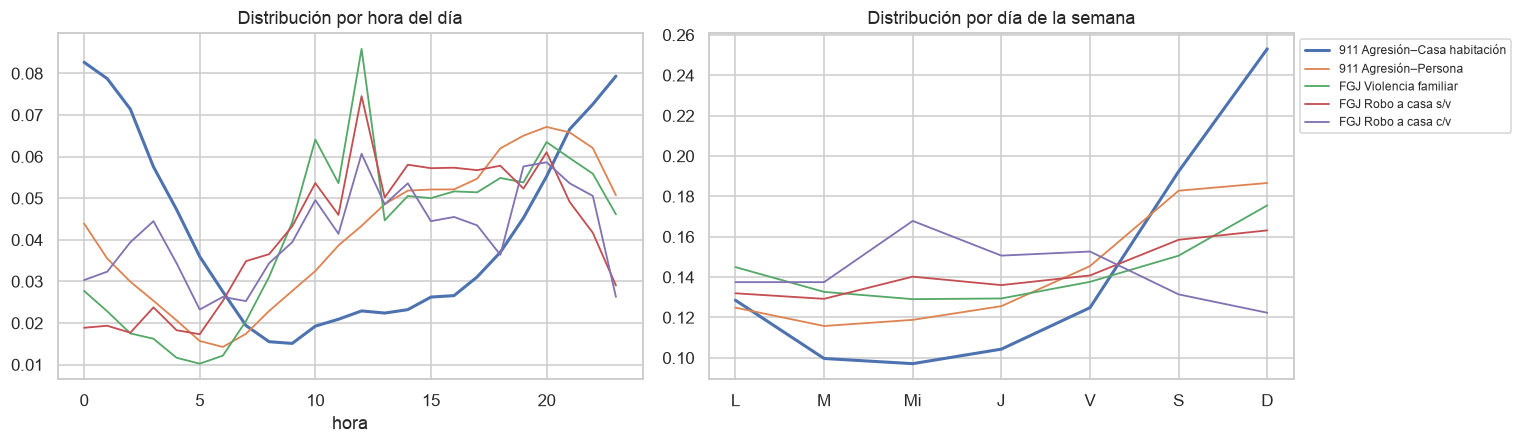

In [11]:
grupos_fgj = {"Violencia familiar": ["VIOLENCIA FAMILIAR"], "Robo a casa s/v": ["ROBO A CASA HABITACION SIN VIOLENCIA"],
              "Robo a casa c/v": ["ROBO A CASA HABITACION CON VIOLENCIA"], "Robo a casa (todos)": ROBO_CH}
series_ch = {"911 Agresión–Casa habitación": c5d[c5d.par == AGCH], "911 Agresión–Persona": c5d[c5d.par == "Agresion – Persona"]}
series_ch.update({f"FGJ {k}": fgj[fgj.delito.isin(v)] for k, v in grupos_fgj.items()})

def perfil(d, h="hora", fecha="fecha"):
    return pd.Series({
        "n": len(d), "tendencia_2021_22_vs_2019": tendencia(d),
        "pct_21_a_03_h": d[h].isin([21, 22, 23, 0, 1, 2]).mean(),
        "pct_08_a_17_h": d[h].between(8, 17).mean(),
        "pct_sab_dom": d[fecha].dt.dayofweek.isin([5, 6]).mean(),
    })
tab_ch = pd.DataFrame({k: perfil(v.assign(fecha=v.get("fecha_creacion", v.get("fecha_hecho")))) for k, v in series_ch.items()}).T
display(tab_ch)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for k, v in series_ch.items():
    if k in ("FGJ Robo a casa (todos)",):
        continue
    fecha = v.get("fecha_creacion", v.get("fecha_hecho"))
    axes[0].plot(perfil_hora(v.hora.dropna()), label=k, lw=2 if "Casa" in k and "911" in k else 1.2)
    axes[1].plot(fecha.dt.dayofweek.value_counts(normalize=True).sort_index(), label=k, lw=2 if "Casa" in k and "911" in k else 1.2)
axes[0].set_title("Distribución por hora del día"); axes[0].set_xlabel("hora")
axes[1].set_title("Distribución por día de la semana"); axes[1].set_xticks(range(7), ["L", "M", "Mi", "J", "V", "S", "D"])
axes[1].legend(fontsize=8, bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

In [12]:
# Ubicación: tasas por 1,000 viviendas en AGEB con viviendas > 0; parciales y un modelo binomial negativo con offset
T = pd.DataFrame({"agch": A911[AGCH], "vf": AFGJ["VIOLENCIA FAMILIAR"], "robo_ch": AFGJ[ROBO_CH].sum(axis=1),
                  "robo_ch_sv": AFGJ["ROBO A CASA HABITACION SIN VIOLENCIA"]})
T["viv"] = ageb.set_index("ageb").viv
T = T[T.viv > 0]
tasas = T.drop(columns="viv").div(T.viv, axis=0) * 1e3
print(f"AGEB con viviendas > 0: {len(T):,}")
print("Spearman de tasas por 1k viviendas con 911 Agresión–CH:", {c: round(stats.spearmanr(tasas.agch, tasas[c])[0], 3) for c in ["vf", "robo_ch", "robo_ch_sv"]})

X = sm.add_constant(np.log1p(T[["vf", "robo_ch"]]))
nb = sm.NegativeBinomial(T.agch, X, exposure=T.viv).fit(disp=0)
display(pd.DataFrame({"coef": nb.params, "ic95_inf": nb.conf_int()[0], "ic95_sup": nb.conf_int()[1], "p": nb.pvalues}))

AGEB con viviendas > 0: 2,401
Spearman de tasas por 1k viviendas con 911 Agresión–CH: {'vf': np.float64(0.469), 'robo_ch': np.float64(0.121), 'robo_ch_sv': np.float64(0.104)}


,coef,ic95_inf,ic95_sup,p
const,-4.771,-4.865,-4.677,0.000
vf,0.303,0.269,0.337,0.000
robo_ch,-0.083,-0.119,-0.047,0.000
alpha,0.219,0.202,0.237,0.000


**Lectura (evidencia indirecta).** Las tres pruebas apuntan en la misma dirección y rechazan E2:
1. **Tendencia:** entre 2019 y 2021–22 las llamadas "Agresión – Casa habitación" **suben** (~1.09×) y la violencia familiar en la FGJ también sube (~1.34×), mientras el robo a casa habitación en la FGJ **cae a la mitad** (~0.49×). Si las llamadas fueran robos, deberían haber caído.
2. **Horario:** 45% de las llamadas cae entre las 21 y las 3 h (pico a la medianoche) y 45% en sábado o domingo, contra 18% y 31% del robo a casa en la FGJ. Ese es el perfil de conflicto doméstico nocturno, no de robo a casa, que en la FGJ se reparte en horario diurno. Ni siquiera la violencia familiar de la FGJ reproduce del todo el pico nocturno, lo que es coherente con que la hora que declara la víctima en la fiscalía sea menos precisa que la hora de la llamada.
3. **Ubicación:** por tasa de viviendas, Spearman 0.47 con violencia familiar contra 0.12 con robo a casa; controlando el volumen total, la parcial es 0.42 contra 0.27. En el binomial negativo con exposición por viviendas, la violencia familiar tiene coeficiente positivo (0.30) y el robo a casa **negativo** (−0.08, IC −0.12 a −0.05): a igual violencia familiar, los AGEB con más robo a casa tienen *menos* llamadas de este tipo.

*Supuesto:* interpreto el perfil horario asumiendo que la hora de la llamada es cercana a la hora del hecho. En el robo a casa sin violencia, la llamada suele hacerse al *descubrirlo* (al volver a casa por la tarde o la noche), lo que acercaría su perfil a la noche. Aun así, un pico a medianoche en fin de semana no es compatible con el descubrimiento de robos, y la prueba espacial y la de tendencia no dependen de este supuesto.

### 4.3 Rango de lo que implica no poder distinguirlo

In [13]:
# ¿Qué fracción de las llamadas Agresión–CH podría ser robo a casa? Dos aproximaciones independientes.
def fraccion_robo_espacial(t):
    w, _ = optimize.nnls(t[["vf", "robo_ch"]].to_numpy(float), t.agch.to_numpy(float))
    return w[1] * t.robo_ch.sum() / t.agch.sum()

pi_esp = fraccion_robo_espacial(T)
boot = np.array([fraccion_robo_espacial(T.iloc[RNG.integers(0, len(T), len(T))]) for _ in range(1000)])
pi_esp_ic = np.percentile(boot, [2.5, 97.5])

# Temporal: mezcla no negativa sobre los 168 bins hora × día de la semana
def perfil_semana(d, fecha):
    return (d[fecha].dt.dayofweek * 24 + d.hora).astype(int).value_counts(normalize=True).reindex(range(168), fill_value=0)
P_ag = perfil_semana(c5d[c5d.par == AGCH], "fecha_creacion")
P_vf = perfil_semana(fgj[fgj.delito == "VIOLENCIA FAMILIAR"].dropna(subset=["hora"]), "fecha_hecho")
P_rc = perfil_semana(fgj[fgj.delito.isin(ROBO_CH)].dropna(subset=["hora"]), "fecha_hecho")
w_t, _ = optimize.nnls(np.c_[P_vf, P_rc], P_ag.to_numpy())
pi_temp = w_t[1] / w_t.sum()

n_ag = int((c5d.par == AGCH).sum()); n_rc = int(fgj.delito.isin(ROBO_CH).sum())
pi_sup = max(pi_esp_ic[1], pi_temp)
rango = pd.DataFrame({
    "aproximacion": ["Mezcla espacial (NNLS por AGEB, bootstrap 1,000)", "Mezcla temporal (NNLS hora × día)", "Binomial negativo (coef. robo a casa)"],
    "fraccion_robo": [pi_esp, pi_temp, np.nan],
    "ic95_inf": [pi_esp_ic[0], np.nan, np.nan], "ic95_sup": [pi_esp_ic[1], np.nan, np.nan],
    "lectura": ["cota superior aproximada", "el perfil horario no requiere componente de robo", f"coef. {nb.params['robo_ch']:.2f} (negativo)"],
})
display(rango)
print(f"Llamadas Agresión–CH en 22 meses: {n_ag:,} | carpetas de robo a casa FGJ: {n_rc:,}")
print(f"Rango de llamadas que podrían ser robo a casa: 0 – {pi_sup * n_ag:,.0f}  (fracción 0 – {pi_sup:.1%})")
print(f"Razón llamadas/carpeta de robo a casa que resultaría: 0 – {pi_sup * n_ag / n_rc:.2f}  (vs {n_ag / n_rc:.1f} si se asumiera que todas son robo)")
print(f"Aun en el extremo superior, ≥ {1 - pi_sup:.0%} del numerador sería otro fenómeno.")

brecha_falsa = (T.agch + 0.5) / (T.robo_ch + 0.5)
print("Spearman entre la 'brecha' Agresión–CH / robo a casa por AGEB y la tasa de violencia familiar:",
      round(stats.spearmanr(brecha_falsa, tasas.vf)[0], 3))

,aproximacion,fraccion_robo,ic95_inf,ic95_sup,lectura
0,"Mezcla espacial (NNLS por AGEB, bootstrap 1,000)",0.160,0.131,0.191,cota superior aproximada
1,Mezcla temporal (NNLS hora × día),0.000,NaN,NaN,el perfil horario no requiere componente de robo
2,Binomial negativo (coef. robo a casa),NaN,NaN,NaN,coef. -0.08 (negativo)


Llamadas Agresión–CH en 22 meses: 48,381 | carpetas de robo a casa FGJ: 9,515
Rango de llamadas que podrían ser robo a casa: 0 – 9,221  (fracción 0 – 19.1%)
Razón llamadas/carpeta de robo a casa que resultaría: 0 – 0.97  (vs 5.1 si se asumiera que todas son robo)
Aun en el extremo superior, ≥ 81% del numerador sería otro fenómeno.
Spearman entre la 'brecha' Agresión–CH / robo a casa por AGEB y la tasa de violencia familiar: 0.202


**Lectura (rango):** el 911 no permite separar robo de agresión en el registro, pero sí acotar la mezcla. En el mejor de los casos para el plan original (mezcla espacial, extremo superior del IC), **a lo más ~19%** de las llamadas "Agresión – Casa habitación" sería robo (estimación puntual 16%, IC 13–19%); la mezcla temporal y el binomial negativo son compatibles con una fracción de cero. Consecuencias:
- De 48,381 llamadas, entre 0 y ~9,200 podrían ser robos. La razón llamadas/carpeta del robo a casa quedaría **indeterminada entre 0 y ~1.0**, en lugar de la razón ingenua de 5.1 que se obtendría asumiendo que todas son robos. Un indicador cuyo rango incluye el cero no discrimina nada.
- Aun en el extremo superior, **≥ 81% del numerador sería otro fenómeno**. Una "brecha de robo a casa" construida con este código por AGEB ya se correlaciona positivamente con la tasa de violencia familiar (ρ = 0.20) por pura construcción.

**Conclusión:** E2 se rechaza. **El robo a casa habitación no tiene canal en el 911.** El caso de aplicación del plan (robo a casa con 911 como segunda fuente) **no se sostiene**.

*Supuesto:* la mezcla espacial asume que las llamadas de un AGEB son combinación lineal de sus carpetas de violencia familiar y de robo a casa, con proporciones de llamada constantes en la ciudad. Si la propensión a llamar variara mucho entre AGEB (justo el fenómeno que se quiere medir), la fracción estimada sería un promedio y no una cota estricta. Por eso se presenta como rango, junto con otras dos aproximaciones que no dependen de ese supuesto.

## 5. "Robo – Automovilista": ¿cambio de catálogo o caída real?

In [14]:
COD_911 = ["Robo – Automovilista", "Robo – Otros", "Detencion ciudadana – Robo", "Robo – Cable",
           "Robo – Bienes gubernamentales", "Robo – Bienes gubernamentales (coladeras cable)", "Robo – Escuela"]
COD_911_SERV = ["SERVICIO | Servicios – Vehiculo recuperado", "SERVICIO | Servicios – Vehiculo recuperado localizado",
                "SERVICIO | Servicios – Reporte de vehiculo via gps", "SERVICIO | Servicios – Reporte de vehiculo via radio",
                "SERVICIO | Abandono – Vehiculo"]
COD_FGJ = {"Robo vehículo particular c/v": ["ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA"],
           "Robo vehículo particular s/v": ["ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"],
           "Robo a pasajero/conductor c/v": ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"],
           "Robo motocicleta (c/v y s/v)": pref("ROBO DE MOTOCICLETA"),
           "Robo vehículo público (c/v y s/v)": pref("ROBO DE VEHICULO DE SERVICIO PÚBLICO")}
meses = pd.period_range("2019-01", "2019-12", freq="M").append(pd.period_range("2021-07", "2022-04", freq="M"))
m911 = c5d[c5d.par.isin(COD_911)].groupby(["mes", "par"]).size().unstack(fill_value=0).reindex(meses, fill_value=0)
m911 = m911.reindex(columns=COD_911, fill_value=0).add_prefix("911: ")
mserv = c5[c5.par_clas.isin(COD_911_SERV)].groupby(["mes", "par_clas"]).size().unstack(fill_value=0).reindex(meses, fill_value=0)
mserv = mserv.reindex(columns=COD_911_SERV, fill_value=0)
mserv.columns = ["911 servicio: " + c.split("| ")[1] for c in mserv.columns]
mfgj = pd.DataFrame({f"FGJ: {k}": fgj[fgj.delito.isin(v)].groupby("mes").size() for k, v in COD_FGJ.items()}).reindex(meses, fill_value=0)
serie = pd.concat([m911, mserv, mfgj], axis=1)
serie.index.name = "mes"
serie.insert(0, "ventana", np.where(serie.index.year == 2019, "2019", "2021-22"))
display(serie)

,ventana,911: Robo – Automovilista,911: Robo – Otros,911: Detencion ciudadana – Robo,911: Robo – Cable,911: Robo – Bienes gubernamentales,911: Robo – Bienes gubernamentales (coladeras cable),911: Robo – Escuela,911 servicio: Servicios – Vehiculo recuperado,911 servicio: Servicios – Vehiculo recuperado localizado,911 servicio: Servicios – Reporte de vehiculo via gps,911 servicio: Servicios – Reporte de vehiculo via radio,911 servicio: Abandono – Vehiculo,FGJ: Robo vehículo particular c/v,FGJ: Robo vehículo particular s/v,FGJ: Robo a pasajero/conductor c/v,FGJ: Robo motocicleta (c/v y s/v),FGJ: Robo vehículo público (c/v y s/v)
mes,,,,,,,,,,,,,,,,,,
2019-01,2019,754,780,469,70,6,0,53,225,0,74,53,1401,263,617,331,225,135
2019-02,2019,749,774,409,54,4,0,44,172,0,43,41,1351,204,567,322,211,111
2019-03,2019,704,843,391,76,10,0,76,205,0,49,47,1540,236,566,354,227,129
2019-04,2019,593,755,357,60,7,0,29,187,0,49,100,1385,266,555,379,207,139
2019-05,2019,648,830,398,55,9,0,37,226,0,44,85,1439,245,607,407,210,133
2019-06,2019,768,448,424,72,12,0,30,254,0,53,68,1543,246,558,391,185,117
2019-07,2019,702,487,357,63,19,0,44,209,0,36,78,1347,255,520,272,159,108
2019-08,2019,637,574,376,73,17,0,48,177,0,40,69,1510,237,513,265,160,108
2019-09,2019,647,457,395,33,0,19,43,10,190,48,88,1356,209,506,269,211,99


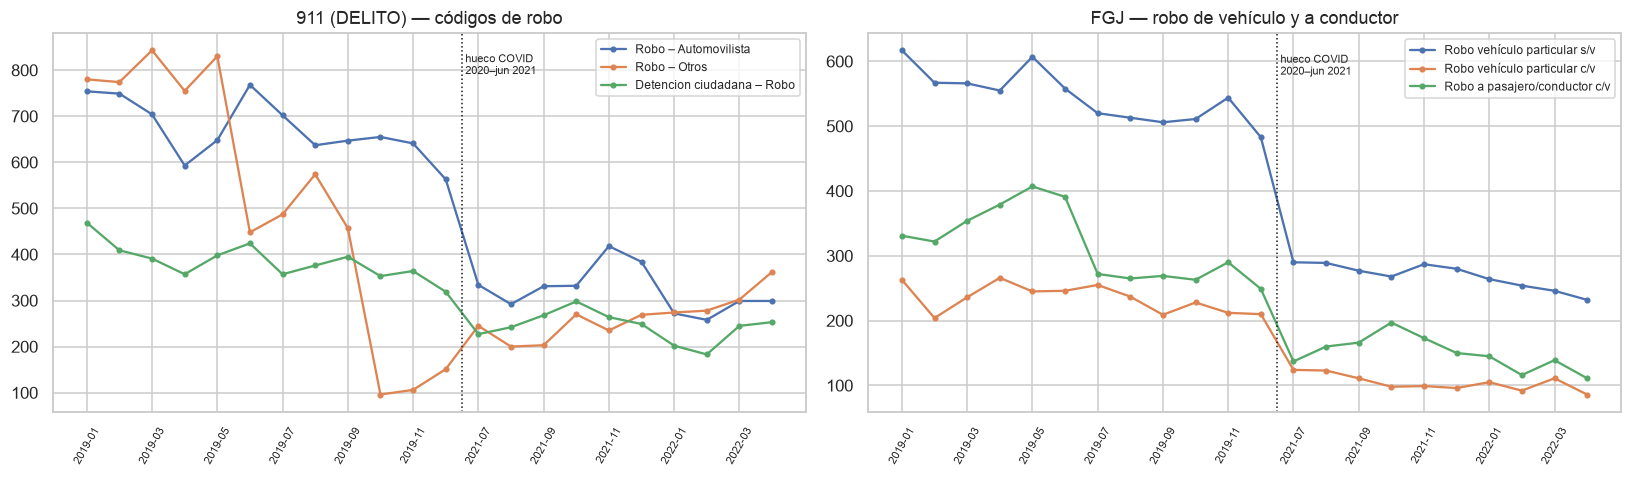

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
x = np.arange(len(meses)); etiquetas = [str(m) for m in meses]
for c in ["911: Robo – Automovilista", "911: Robo – Otros", "911: Detencion ciudadana – Robo"]:
    axes[0].plot(x, serie[c], marker="o", ms=3, label=c.replace("911: ", ""))
for c in ["FGJ: Robo vehículo particular s/v", "FGJ: Robo vehículo particular c/v", "FGJ: Robo a pasajero/conductor c/v"]:
    axes[1].plot(x, serie[c], marker="o", ms=3, label=c.replace("FGJ: ", ""))
for ax, t in zip(axes, ["911 (DELITO) — códigos de robo", "FGJ — robo de vehículo y a conductor"]):
    ax.axvline(11.5, c="k", ls=":", lw=1); ax.text(11.6, ax.get_ylim()[1] * .95, "hueco COVID\n2020–jun 2021", fontsize=7, va="top")
    ax.set_xticks(x[::2], etiquetas[::2], rotation=60, fontsize=7); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
# Escalones: máximo cambio relativo mes a mes dentro de cada ventana (sin cruzar el hueco) y tendencia entre ventanas
def escalon(s):
    out = {}
    for k in ["2019", "2021-22"]:
        v = s[serie.ventana == k].to_numpy(float)
        cambios = v[1:] / np.where(v[:-1] == 0, np.nan, v[:-1])
        i = np.nanargmin(cambios) if np.isfinite(cambios).any() else None
        out[f"mayor_caida_mensual_{k}"] = cambios[i] - 1 if i is not None else np.nan
        out[f"mes_mayor_caida_{k}"] = str(serie.index[serie.ventana == k][i + 1]) if i is not None else ""
    out["tendencia_2021_22_vs_2019"] = (s[serie.ventana == "2021-22"].mean()) / (s[serie.ventana == "2019"].mean()) if s[serie.ventana == "2019"].mean() else np.nan
    return pd.Series(out)
esc = serie.drop(columns="ventana").apply(escalon).T
display(esc)

ro = c5d[(c5d.par == "Robo – Otros") & c5d.fecha_creacion.between("2019-09-01", "2019-11-30")].groupby("fecha_creacion").size()
print("Robo – Otros, promedio diario: 1–30 sep 2019 =", round(ro.loc[:"2019-09-30"].mean(), 1), "| 1 oct – 30 nov 2019 =", round(ro.loc["2019-10-01":].mean(), 1))

,mayor_caida_mensual_2019,mes_mayor_caida_2019,mayor_caida_mensual_2021-22,mes_mayor_caida_2021-22,tendencia_2021_22_vs_2019
911: Robo – Automovilista,-0.158,2019-04,-0.292,2022-01,0.479
911: Robo – Otros,-0.790,2019-10,-0.184,2021-08,0.502
911: Detencion ciudadana – Robo,-0.158,2019-07,-0.189,2022-01,0.633
911: Robo – Cable,-0.548,2019-09,-0.286,2022-02,0.799
911: Robo – Bienes gubernamentales,-1.000,2019-09,NaN,,0.000
911: Robo – Bienes gubernamentales (coladeras cable),-0.038,2019-11,-0.313,2021-11,6.148
911: Robo – Escuela,-0.618,2019-04,-0.421,2021-10,0.650
911 servicio: Servicios – Vehiculo recuperado,-1.000,2019-10,NaN,,0.000
911 servicio: Servicios – Vehiculo recuperado localizado,-0.215,2019-11,-0.195,2022-03,1.816
911 servicio: Servicios – Reporte de vehiculo via gps,-0.419,2019-02,-0.388,2022-04,0.846


Robo – Otros, promedio diario: 1–30 sep 2019 = 15.2 | 1 oct – 30 nov 2019 = 3.4


**Lectura (Robo – Automovilista):** E3 se rechaza.
- **No hay escalón de catálogo.** Dentro de 2019 la serie baja de forma gradual (~750 → ~560 al mes), sin ningún salto el 2–3 de septiembre (cuando sí cambiaron otros códigos) ni en octubre. Dentro de 2021–22 es estable (~260–420). La mitad que falta desaparece **en el hueco COVID**, donde no se puede fechar con el 911.
- **La FGJ cae en la misma proporción.** El robo de vehículo particular (con y sin violencia) y el robo a conductor caen a ~0.45–0.49× en la FGJ, igual que "Automovilista" en el 911 (~0.48×). Dos fuentes independientes con la misma caída indican una **reducción real del fenómeno**, no una recodificación.
- **Contraste útil:** "Robo – Otros" sí muestra el patrón de un cambio de catálogo: cae 79% de septiembre a octubre de 2019 (de ~15 a ~3 llamadas diarias en la primera semana de octubre), sin contrapartida en la FGJ. Ese código no sirve para series de tiempo que crucen oct-2019.
- **Lo que sí cambia la decisión** es la sección 3: "Automovilista" es robo **al conductor**, no robo **del vehículo**. La caída se explica, pero el canal no mide el delito que el plan quería calibrar.

*Supuesto:* atribuyo la caída a un cambio real asumiendo que la FGJ no cambió su propia clasificación de robo de vehículo en el mismo periodo. Si la FGJ también se hubiera recodificado, la coincidencia sería artefacto de dos cambios simultáneos, algo improbable pero no descartable sin una tercera fuente (AMIS a nivel entidad podría servir como verificación gruesa).

## 6. Recomendación para la tarea 1.3: los dos delitos

In [17]:
env = pd.read_csv(ROOT / "resultados/02_envipe_cifra_negra_por_tipo_delito.csv", dtype={"BPCOD": str}).set_index("BPCOD")
def envipe(cod):
    r = env.loc[cod]
    return f"{r.cifra_negra:.1%} (n={int(r.n)}, {int(r.carpetas)} con carpeta)"
def canal(clave):
    if clave is None:
        return "ninguno", 0, "—"
    r = eq.loc[clave]
    return f"{r.categoria_incidente_c4} – {r.incidente_c4}", int(r.llamadas_911_2019 + r.llamadas_911_2021_22), r.confianza_mapeo
def fgj_n(delitos):
    f = fgj[fgj.delito.isin(delitos)]
    return len(f), f.coord_ok.mean()

K = lambda p, g: f"{p}  →  {g}"
candidatos = [
    ("Robo de vehículo particular", None, pref("ROBO DE VEHICULO DE SERVICIO PARTICULAR"), envipe("01"),
     "débil: el robo ocurre donde se estaciona, no donde vive el dueño"),
    ("Robo a casa habitación", K("Agresion – Casa habitacion", "Robo a casa habitación (c/v, s/v, y vehículo)"), ROBO_CH, envipe("04"),
     "fuerte: viviendas particulares habitadas (hecho en el domicilio)"),
    ("Robo a transeúnte", K("Robo – Otros", "Robo a transeúnte en vía pública (c/v, s/v)"),
     ["ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA", "ROBO A TRANSEUNTE EN VIA PUBLICA SIN VIOLENCIA"], envipe("05") + " — calle y transporte",
     "débil: población flotante, no residentes"),
    ("Robo a conductor de vehículo c/v", K("Robo – Automovilista", "Robo a pasajero/conductor de vehículo c/v"),
     ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"], "no separable: incluido en " + envipe("05"),
     "débil: ocurre en vialidades (semáforos, avenidas)"),
    ("Violencia familiar", K("Agresion – Casa habitacion", "Violencia familiar"), ["VIOLENCIA FAMILIAR"],
     "no medible con ENVIPE (fuera de su universo; INEGI la mide en ENDIREH)", "fuerte: viviendas particulares habitadas (hecho en el domicilio)"),
]
filas = []
for nombre, clave, delitos, cn, denom in candidatos:
    par, n911, conf = canal(clave)
    nf, cob = fgj_n(delitos)
    filas.append({"delito": nombre, "canal_911": par, "confianza_mapeo": conf, "llamadas_911_22m": n911, "carpetas_fgj_22m": nf,
                  "pct_fgj_con_coordenadas": cob, "cifra_negra_envipe": cn, "denominador_ageb": denom})
matriz = pd.DataFrame(filas).set_index("delito")
matriz

,canal_911,confianza_mapeo,llamadas_911_22m,carpetas_fgj_22m,pct_fgj_con_coordenadas,cifra_negra_envipe,denominador_ageb
delito,,,,,,,
Robo de vehículo particular,ninguno,—,0,13090,0.965,"36.1% (n=86, 55 con carpeta)","débil: el robo ocurre donde se estaciona, no donde vive el dueño"
Robo a casa habitación,Agresion – Casa habitacion,baja,48381,9515,0.997,"87.8% (n=138, 18 con carpeta)",fuerte: viviendas particulares habitadas (hecho en el domicilio)
Robo a transeúnte,Robo – Otros,baja,8939,24535,0.986,"94.8% (n=562, 31 con carpeta) — calle y transporte","débil: población flotante, no residentes"
Robo a conductor de vehículo c/v,Robo – Automovilista,alta,11280,5286,0.992,"no separable: incluido en 94.8% (n=562, 31 con carpeta)","débil: ocurre en vialidades (semáforos, avenidas)"
Violencia familiar,Agresion – Casa habitacion,media,48381,55158,0.976,no medible con ENVIPE (fuera de su universo; INEGI la mide en ENDIREH),fuerte: viviendas particulares habitadas (hecho en el domicilio)


**Lectura (matriz de decisión).** Ningún delito cumple los cuatro criterios a la vez, y el cuello de botella es el que el plan suponía resuelto: **la cobertura real del 911**.

| Delito | 911 | ENVIPE | Denominador AGEB | Coordenadas | Veredicto |
|---|---|---|---|---|---|
| Robo de vehículo | ✗ no existe código | ✓ 36% (el mejor medido) | ✗ | ✓ | Sin 911: no puede calibrar un indicador 911/FGJ |
| Robo a casa habitación | ✗ contaminado (mayoría violencia familiar) | ✓ 88% | ✓ | ✓ | Sin 911 limpio: el plan original no se sostiene |
| Robo a transeúnte | ✗ solo "Robo – Otros" residual y con escalón de catálogo | ✓ 95% | ✗ | ✓ | Peor que casa habitación: no es alternativa |
| Robo a conductor | ✓ **alta** | ~ solo como cota (dentro de "calle y transporte") | ✗ | ✓ | El único par limpio del catálogo |
| Violencia familiar | ✓ media (el mayor volumen del catálogo) | ✗ (requiere ENDIREH) | ✓ | ✓ | Hereda el argumento del domicilio |

**Recomendación (para decidir el 4 de oct):**

1. **Caso de aplicación → violencia familiar** (911 "Agresión – Casa habitación" ↔ FGJ "Violencia familiar"). Hereda intacto el mejor argumento del plan (el hecho ocurre en el domicilio, así que el denominador son viviendas habitadas y las covariables del AGEB describen a los hogares afectados), tiene el mayor volumen de ambos lados (~48k llamadas y ~55k carpetas en 22 meses, más de 5 veces el robo a casa) y un subregistro socialmente relevante. **Costo:** ENVIPE no la mide; la calibración a nivel ciudad tendría que salir de la **ENDIREH 2021** (INEGI, violencia contra mujeres en el ámbito familiar, representativa por entidad). Hay que verificar su disponibilidad y qué indicador de denuncia trae antes del 4 de oct. **Riesgo a declarar:** parte de "Agresión – Casa habitación" pueden ser pleitos vecinales u otros conflictos en el domicilio, no familiares.
2. **Caso de calibración → robo a conductor** (911 "Robo – Automovilista" ↔ FGJ "Robo a pasajero/conductor c/v"). Es el único par con confianza alta en las tres pruebas, así que sirve para lo que debe servir un caso de calibración: mostrar que **cuando el mapeo es limpio, el indicador llamadas/carpeta es estable y se comporta como se espera**. **Costo:** ENVIPE no lo separa de "robo en calle o transporte" (94.8%), así que la validación contra ENVIPE es solo de orden de magnitud, no de nivel. **H3 debe reescribirse:** con robo de vehículo es imposible, porque no hay canal 911.
3. **Robo de vehículo y robo a casa quedan como casos FGJ + ENVIPE sin 911**: sirven de contexto (cifra negra por tipo de delito) pero no pueden entrar en el indicador de brecha. Decirlo explícitamente es un punto a favor en D2: responde con datos al comentario 2 de los sinodales.

**Alternativa conservadora, si ENDIREH no sirve:** caso de aplicación = robo a casa habitación **sin 911**, con FGJ por AGEB contra el denominador de viviendas y ENVIPE (88%) solo a nivel ciudad. Se pierde la brecha entre fuentes (el corazón del método) y queda un análisis de incidencia registrada. Es más débil en D4.

*Supuesto de la recomendación:* uso la confianza del mapeo como criterio dominante asumiendo que un numerador contaminado invalida el indicador sin importar qué tan buena sea la cifra negra de ENVIPE. Si los sinodales priorizaran la comparabilidad con ENVIPE sobre la pureza del 911, el orden cambiaría a favor de robo a casa habitación sin 911.

## 7. Exportar resultados (`resultados/09_` y `10_`)

In [18]:
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
r4 = lambda d: d.round(4)
cols_eq = ["categoria_incidente_c4", "incidente_c4", "fgj_grupo", "fgj_delitos", "llamadas_911_2019", "llamadas_911_2021_22", "pct_afirmativo_911",
           "pct_911_en_ageb", "carpetas_fgj_2019", "carpetas_fgj_2021_22", "pct_fgj_con_coordenadas", "pct_fgj_en_ageb", "llamadas_por_carpeta",
           "tendencia_911", "tendencia_fgj", "rho_parcial_ageb", "rho_horario", "confianza_mapeo", "justificacion"]
eq_out = r4(eq[cols_eq])
conteos = [c for c in cols_eq if c.startswith(("llamadas_911_", "carpetas_fgj_"))]
eq_out[conteos] = eq_out[conteos].astype(int)
eq_out.to_csv(OUT / "09_equivalencias_911_fgj.csv", index=False)
s = serie.copy(); s.index = s.index.astype(str)
s.to_csv(OUT / "10_serie_mensual_robo_vehiculo_911_fgj.csv")
sorted(p.name for p in OUT.glob("*.csv"))

['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv']

## 8. Experimento 2.1 — Brecha llamadas/carpeta por AGEB de los dos delitos (`resultados/11_`)

Alcance cerrado el 1 de oct (`PLAN_15_OCT.md` §3): **violencia familiar** (aplicación; 911 "Agresión – Casa habitación" ↔ FGJ "VIOLENCIA FAMILIAR") y **robo a conductor** (calibración; 911 "Robo – Automovilista" ↔ FGJ "ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"). Mismos nombres que en `09_`. Las dos ventanas se tratan **por separado**.

**Orden, que no se puede alterar:**
1. La agregación espacial de robo a conductor para H3 se fijó **el 5 de oct, antes de calcular cualquier correlación entre ventanas**, viendo solo la distribución de conteos por AGEB (`PLAN_15_OCT.md` §3.1): grupos de AGEB contiguos dentro de la alcaldía con **≥ 12 carpetas en cada ventana**. El mismo umbral de 12 define "conteo bajo" y el universo de la prueba de estabilidad de violencia familiar. Aquí solo se construye; **la prueba de H3 va en el 2.4**.
2. Tabla por AGEB y ventana, con la brecha y su intervalo; en violencia familiar, además viviendas, tasas y la banda de sensibilidad de S1.
3. Prueba de estabilidad entre ventanas, **solo de violencia familiar** (S4).

**Supuestos de la sección, en el formato del caso:**
- *Numerador.* Uso todas las llamadas clasificadas DELITO, igual que `09_`, asumiendo que la proporción de duplicados es parecida entre AGEB. `codigo_cierre` no es comparable entre ventanas (2019 marca 30% de duplicados; 2021–22 solo trae "A"/"Otros"), así que no se puede depurar igual en las dos. Si los duplicados se concentraran en ciertos AGEB, convendría usar solo las "afirmativas": se reportan como sensibilidad.
- *Coordenadas (S7).* Uso solo las carpetas que caen en un AGEB, asumiendo que las que no tienen coordenadas no se concentran en ciertos territorios. Si se concentraran, los AGEB de las alcaldías con menos cobertura tendrían la brecha inflada; por eso la cobertura se reporta por alcaldía (8.1) y viaja en el CSV.
- *Unidad.* La brecha es una razón entre dos poblaciones de eventos, no un pareo llamada–carpeta: mide fricción entre el aviso y la denuncia (S6), no el subregistro.

### 8.1 Conteos por AGEB y cobertura de coordenadas por alcaldía (S7)

In [19]:
PARES_21 = {
    "violencia_familiar": ("Agresion – Casa habitacion", ["VIOLENCIA FAMILIAR"]),
    "robo_conductor": ("Robo – Automovilista", ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"]),
}
assert all(p in set(eq.index.str.split("  →  ").str[0]) for p, _ in PARES_21.values())
UMBRAL = 12   # fijado el 5 oct en PLAN §3.1: CV de Poisson del denominador 1/√12 = 28.9% ≤ 30% (frontera INEGI)
S1_ROBO = 0.19  # extremo superior de la mezcla espacial (sección 4.3)
VENT = list(VENTANAS)
ageb["alcaldia"] = ageb.alc.map(norm_alc)
# 2 AGEB traen `alc` vacío en el shapefile: se completan con la clave municipal (caracteres 3–5 de la clave AGEB)
mun = ageb.ageb.str[2:5]
ageb["alcaldia"] = ageb.alcaldia.fillna(mun.map(ageb.dropna(subset=["alcaldia"]).groupby(mun).alcaldia.agg(pd.Series.mode)))
assert ageb.alcaldia.notna().all() and ageb.groupby(mun).alcaldia.nunique().eq(1).all()
assert set(fgj.alcaldia.dropna()) >= set(ageb.alcaldia), set(ageb.alcaldia) - set(fgj.alcaldia.dropna())
IDX = pd.MultiIndex.from_product([VENT, ageb.ageb], names=["ventana", "ageb"])

def conteos(delito):
    p911, dfgj = PARES_21[delito]
    a = c5d[c5d.par == p911]; f = fgj[fgj.delito.isin(dfgj)]
    t = pd.concat({"llamadas": a.groupby(["ventana", "ageb"]).size(),
                   "llamadas_afirmativas": a[a.afirmativo].groupby(["ventana", "ageb"]).size(),
                   "carpetas": f.groupby(["ventana", "ageb"]).size()}, axis=1)
    return t.reindex(IDX).fillna(0).astype(int)

CNT = {d: conteos(d) for d in PARES_21}

OTRA = "(sin alcaldía o fuera de CDMX)"
cob, glob = [], []
for d, (p911, dfgj) in PARES_21.items():
    f = fgj[fgj.delito.isin(dfgj)].assign(alcaldia=lambda x: x.alcaldia.where(x.alcaldia.isin(set(ageb.alcaldia)), OTRA))
    a = c5d[c5d.par == p911]
    g = f.groupby(["ventana", "alcaldia"]).ageb.agg(carpetas="size", en_ageb="count")
    g["cobertura"] = g.en_ageb / g.carpetas
    cob.append(g.assign(delito=d).reset_index())
    for w in VENT:
        fw, aw = f[f.ventana == w], a[a.ventana == w]
        glob.append({"delito": d, "ventana": w, "llamadas": len(aw), "llamadas_en_ageb": aw.ageb.notna().mean(),
                     "carpetas": len(fw), "carpetas_en_ageb": fw.ageb.notna().mean()})
cob = pd.concat(cob, ignore_index=True)
display(pd.DataFrame(glob).set_index(["delito", "ventana"]))
tab_cob = cob.pivot_table(index="alcaldia", columns=["delito", "ventana"], values="cobertura")
tab_cob["carpetas_22m"] = cob.groupby("alcaldia").carpetas.sum()
display(tab_cob.style.format("{:.1%}").format("{:,.0f}", subset=["carpetas_22m"]))
print("Rango de cobertura entre las 16 alcaldías:",
      {f"{d} {w}": f"{s.min():.1%} ({s.idxmin()}) – {s.max():.1%}" for (d, w), s in tab_cob.drop(index=OTRA, columns="carpetas_22m").items()})
print(tab_cob.loc[[OTRA]].round(3).to_string())

llamadas  llamadas_en_ageb  carpetas  carpetas_en_ageb
delito             ventana                                                        
violencia_familiar 2019        25371             0.998     26084             0.970
                   2021-22     23010             0.997     29074             0.964
robo_conductor     2019         8061             0.999      3792             0.993
                   2021-22      3219             0.998      1494             0.982

Rango de cobertura entre las 16 alcaldías: {'robo_conductor 2019': '96.6% (CUAJIMALPA DE MORELOS) – 100.0%', 'robo_conductor 2021-22': '96.6% (XOCHIMILCO) – 100.0%', 'violencia_familiar 2019': '88.9% (MILPA ALTA) – 99.7%', 'violencia_familiar 2021-22': '87.7% (CUAUHTEMOC) – 99.9%'}
delito                         robo_conductor         violencia_familiar         carpetas_22m
ventana                                  2019 2021-22               2019 2021-22             
alcaldia                                                                                     
(sin alcaldía o fuera de CDMX)          0.000   0.000              0.000   0.000          618


**Lectura (cobertura):** en la ciudad caen en un AGEB el 97.0% (2019) y el 96.4% (2021–22) de las carpetas de violencia familiar, el 99.3% y el 98.2% de las de robo a conductor, y ≥ 99.7% de las llamadas. En robo a conductor todas las alcaldías quedan en ≥ 96.6%: **S7 se sostiene**. En violencia familiar la cobertura no es pareja: va de 87.7% (Cuauhtémoc, 2021–22, que cae desde 97.4% en 2019) y 88.9% (Milpa Alta, 2019) a 99.9%. Si las carpetas sin coordenadas de Cuauhtémoc cayeran en sus propios AGEB, su brecha de 2021–22 estaría inflada hasta en 14% (1/0.877). No basta para invertir una clasificación sólida, pero el mapa del 2.6 debe llevar la cobertura de esas dos alcaldías al pie. Otras 618 carpetas de los dos delitos (22 meses) no tienen alcaldía de la CDMX.

### 8.2 Brecha por AGEB con intervalo exacto

**Método del intervalo.** Si llamadas ~ Poisson(λ₁) y carpetas ~ Poisson(λ₂) son independientes, condicionando en el total n = llamadas + carpetas, las llamadas siguen una Binomial(n, p) con p = λ₁/(λ₁+λ₂), y la brecha es R = p/(1−p). El IC 95% de Clopper-Pearson para p se transforma a R: es **exacto** con conteos chicos, que es justo el caso de robo a conductor, y no necesita la aproximación normal del log de la razón, que falla con ceros. *Supuesto:* uso la razón de dos Poisson asumiendo que, dentro de un AGEB y ventana, los eventos son independientes y su tasa es constante. Si hubiera sobredispersión (rachas de llamadas por el mismo hecho, que es justo el problema de los duplicados), el intervalo sería demasiado estrecho; por eso la estabilidad se prueba con rangos y permutación, que no dependen de este intervalo.

**Clasificación**, en cada ventana: *alta* si el IC del AGEB queda entero por encima de la brecha de la ciudad, *baja* si queda entero por debajo, *indistinguible* si la cruza y *sin carpetas* si el denominador es cero. Es una clasificación con incertidumbre, no un ranking: un AGEB con dos carpetas casi nunca sale del "indistinguible".

In [20]:
def ic_razon(x, y, alfa=0.05):
    # IC exacto de λx/λy condicionando en n = x + y (Clopper-Pearson sobre p = λx/(λx+λy), luego R = p/(1-p))
    x = np.asarray(x, float); y = np.asarray(y, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        lo = np.where(x > 0, stats.beta.ppf(alfa / 2, x, y + 1), 0.0)
        hi = np.where(y > 0, stats.beta.ppf(1 - alfa / 2, x + 1, y), 1.0)
        return lo / (1 - lo), np.where(hi < 1, hi / (1 - hi), np.inf)

def brecha(t, num="llamadas", den="carpetas"):
    lo, hi = ic_razon(t[num], t[den])
    ok = t[den] > 0
    return pd.DataFrame({"brecha": (t[num] / t[den]).where(ok), "brecha_ic95_inf": pd.Series(lo, t.index).where(ok),
                         "brecha_ic95_sup": pd.Series(hi, t.index).where(ok)}, index=t.index)

def clasifica(b, ciudad):
    c = pd.Series("indistinguible", index=b.index)
    c[b.brecha_ic95_inf > ciudad] = "alta"; c[b.brecha_ic95_sup < ciudad] = "baja"
    c[b.brecha.isna()] = "sin carpetas"
    return c

ciudad, TAB = [], {}
for d, t in CNT.items():
    b = t.join(brecha(t))
    tot = t.groupby("ventana").sum()
    lo, hi = ic_razon(tot.llamadas, tot.carpetas)
    tot = tot.assign(brecha_ciudad=tot.llamadas / tot.carpetas, ic95_inf=lo, ic95_sup=hi, delito=d)
    ciudad.append(tot.reset_index())
    b["brecha_ciudad"] = b.index.get_level_values("ventana").map(tot.brecha_ciudad)
    b["clasificacion"] = clasifica(b, b.brecha_ciudad)
    b["conteo_bajo"] = b.carpetas < UMBRAL
    TAB[d] = b
ciudad = pd.concat(ciudad).set_index(["delito", "ventana"])
display(ciudad)

resumen_ageb = pd.concat({d: b.groupby("ventana").agg(
    ageb_con_carpetas=("carpetas", lambda s: (s > 0).sum()), ageb_conteo_bajo=("conteo_bajo", "sum"),
    brecha_mediana=("brecha", "median"), brecha_p10=("brecha", lambda s: s.quantile(.1)), brecha_p90=("brecha", lambda s: s.quantile(.9)),
    alta=("clasificacion", lambda s: (s == "alta").sum()), baja=("clasificacion", lambda s: (s == "baja").sum()),
    indistinguible=("clasificacion", lambda s: (s == "indistinguible").sum()), sin_carpetas=("clasificacion", lambda s: (s == "sin carpetas").sum()))
    for d, b in TAB.items()})
display(resumen_ageb)

llamadas  llamadas_afirmativas  carpetas  brecha_ciudad  ic95_inf  ic95_sup
delito             ventana                                                                             
violencia_familiar 2019        25325                  3711     25294          1.001     0.984     1.019
                   2021-22     22937                  5554     28022          0.819     0.804     0.833
robo_conductor     2019         8050                  1459      3767          2.137     2.056     2.222
                   2021-22      3214                  1053      1467          2.191     2.059     2.332

ageb_con_carpetas  ageb_conteo_bajo  brecha_mediana  brecha_p10  brecha_p90  alta  baja  indistinguible  sin_carpetas
                   ventana                                                                                                                       
violencia_familiar 2019                  2337              1570           0.947       0.229       2.375   160   165            2012            96
                   2021-22               2358              1425           0.776       0.235       2.000   138   133            2087            75
robo_conductor     2019                  1254              2393           1.250       0.000       4.500    24    42            1188          1179
                   2021-22                842              2433           1.000       0.000       3.000     5     8             829          1591

**Lectura (brecha por AGEB):** en la ciudad, la violencia familiar tiene **1.00 llamadas por carpeta en 2019** (IC 95%: 0.98–1.02; 25,325 llamadas y 25,294 carpetas) y **0.82 en 2021–22** (IC 0.80–0.83; 22,937 y 28,022). La caída de nivel es el aumento de carpetas (1.34×) que ya registra `09_`; el orden entre AGEB lo prueba 8.5. Robo a conductor queda en **2.14** (IC 2.06–2.22; 8,050 y 3,767) y **2.19** (IC 2.06–2.33; 3,214 y 1,467), con el mismo nivel en las dos ventanas.
- *Violencia familiar por AGEB:* mediana 0.95 y 0.78, con rango p10–p90 de 0.23–2.38 y de 0.24–2.00. Aun así, el 86% (2,012 de 2,337) y el 89% (2,087 de 2,358) de los AGEB con carpetas no se distinguen de la ciudad con su IC 95%. Los que sí se distinguen son 325 (160 altos, 165 bajos) en 2019 y 271 (138 y 133) en 2021–22, más del ~5% que daría el azar si todos tuvieran la brecha de la ciudad. La prueba formal es H1, en el 2.3. Hay 1,570 y 1,425 AGEB con conteo bajo (< 12 carpetas).
- *Robo a conductor por AGEB:* **no es interpretable a ese grano**. Hay 1,179 y 1,591 AGEB sin carpetas, los 2,433 tienen conteo bajo en 2021–22, y solo 66 y 13 AGEB se distinguen de la ciudad. Esto confirma que la agregación del §3.1 era necesaria.

### 8.3 Violencia familiar: viviendas, tasas y banda de sensibilidad de S1

**Denominador.** `VIVPAR_HAB` de RESAGEBURB (viviendas particulares habitadas). Las tasas por 1,000 viviendas se calculan solo con viviendas > 0; `*` es dato protegido, no cero, y se marca aparte.

**Banda de S1.** Hasta 19% de las llamadas "Agresión – Casa habitación" podría ser robo a casa (sección 4.3). **Descontar 19% parejo no cambia nada**: escala todas las brechas y la de la ciudad por el mismo 0.81, así que ni el orden ni la clasificación se mueven. Lo que S1 teme es que el robo se concentre en ciertos territorios. Por eso el escenario de 19% reparte el descuento **donde está el robo a casa**: a cada AGEB se le quita una parte de 19% de las llamadas de la ciudad proporcional a sus carpetas de robo a casa en la FGJ (con tope en sus propias llamadas), que es la misma mezcla espacial con que se estimó el 19%. *Supuesto:* uso la distribución de las carpetas de robo a casa como la distribución del robo escondido en el código, asumiendo que el robo que se llama al 911 ocurre donde se denuncia. Si el robo llamado se concentrara donde **no** se denuncia, este escenario subestimaría el cambio; sería el peor caso para S1 y no hay forma de verlo con estos datos. El intervalo del escenario se escala por el mismo factor, tratando el descuento como fijo.

In [21]:
vf = TAB["violencia_familiar"].copy()
viv = res.set_index("ageb")[["VIVPAR_HAB", "viv"]].reindex(ageb.ageb)
a_idx = vf.index.get_level_values("ageb")
vf["viviendas"] = viv.viv.reindex(a_idx).to_numpy()
vf["viv_protegido"] = (viv.VIVPAR_HAB.reindex(a_idx) == "*").to_numpy()
vf["viv_cero"] = (vf.viviendas == 0).to_numpy()
con_viv = vf.viviendas > 0
vf["llamadas_por_1k_viv"] = (vf.llamadas / vf.viviendas * 1e3).where(con_viv)
vf["carpetas_por_1k_viv"] = (vf.carpetas / vf.viviendas * 1e3).where(con_viv)

rch = fgj[fgj.delito.isin(ROBO_CH)].groupby(["ventana", "ageb"]).size().reindex(IDX, fill_value=0)
LL = vf.groupby("ventana").llamadas.transform("sum"); RCH = rch.groupby("ventana").transform("sum")
vf["robo_ch_fgj"] = rch
vf["llamadas_robo_desc_s1"] = np.minimum(vf.llamadas, S1_ROBO * LL * rch / RCH)
ll_s1 = vf.llamadas - vf.llamadas_robo_desc_s1
fac = (ll_s1 / vf.llamadas).where(vf.llamadas > 0, 1.0)
vf["brecha_s1_19"] = (ll_s1 / vf.carpetas).where(vf.carpetas > 0)
vf["brecha_s1_19_ic95_inf"] = vf.brecha_ic95_inf * fac
vf["brecha_s1_19_ic95_sup"] = vf.brecha_ic95_sup * fac
ciudad_s1 = ll_s1.groupby("ventana").sum() / vf.groupby("ventana").carpetas.sum()
b_s1 = vf[["brecha_s1_19", "brecha_s1_19_ic95_inf", "brecha_s1_19_ic95_sup"]].set_axis(["brecha", "brecha_ic95_inf", "brecha_ic95_sup"], axis=1)
vf["clasificacion_s1_19"] = clasifica(b_s1, vf.index.get_level_values("ventana").map(ciudad_s1))
vf["cambia_clasif_s1"] = (vf.clasificacion != vf.clasificacion_s1_19) & (vf.carpetas > 0)

print("Fracción de llamadas descontadas por ventana (meta 19%; el tope por AGEB la reduce):",
      (vf.groupby("ventana").llamadas_robo_desc_s1.sum() / vf.groupby("ventana").llamadas.sum()).round(4).to_dict())
print("Brecha de la ciudad con 0% y con 19% descontado:",
      {w: (round(ciudad.loc[("violencia_familiar", w), "brecha_ciudad"], 3), round(ciudad_s1[w], 3)) for w in VENT})
print(f"AGEB: viviendas protegidas (*) = {viv.VIVPAR_HAB.eq('*').sum()} | viviendas 0 = {(viv.viv == 0).sum()} | con viviendas > 0 = {(viv.viv > 0).sum():,}")

banda = pd.crosstab([vf.index.get_level_values("ventana"), vf.clasificacion], vf.clasificacion_s1_19, margins=True)
display(banda)
cambios = vf[vf.cambia_clasif_s1].groupby("ventana").size().reindex(VENT, fill_value=0)
evaluables = vf[vf.carpetas > 0].groupby("ventana").size()
print("AGEB que cambian de clasificación dentro de la banda 0–19%:",
      {w: f"{cambios[w]} de {evaluables[w]:,} ({cambios[w] / evaluables[w]:.1%})" for w in VENT})
ambas = vf.cambia_clasif_s1.groupby("ageb").any()
print(f"AGEB que cambian en al menos una ventana: {ambas.sum()} | con clasificación robusta en ambas ventanas: {(~ambas).sum():,} de {len(ambas):,}")
print("Spearman (dentro de cada ventana) entre la brecha con 0% y con 19%:",
      {w: round(stats.spearmanr(*vf.xs(w)[["brecha", "brecha_s1_19"]].dropna().to_numpy().T)[0], 3) for w in VENT})
display(vf.xs("2019")[["llamadas_por_1k_viv", "carpetas_por_1k_viv", "brecha"]].describe(percentiles=[.1, .5, .9]).T)

Fracción de llamadas descontadas por ventana (meta 19%; el tope por AGEB la reduce): {'2019': 0.1773, '2021-22': 0.1786}
Brecha de la ciudad con 0% y con 19% descontado: {'2019': (np.float64(1.001), np.float64(0.824)), '2021-22': (np.float64(0.819), np.float64(0.672))}
AGEB: viviendas protegidas (*) = 12 | viviendas 0 = 20 | con viviendas > 0 = 2,401


clasificacion_s1_19     alta  baja  indistinguible  sin carpetas   All
row_0   clasificacion                                                 
2019    alta             150     0              10             0   160
        baja               0   142              23             0   165
        indistinguible    40   249            1723             0  2012
        sin carpetas       0     0               0            96    96
2021-22 alta             129     0               9             0   138
        baja               0   114              19             0   133
        indistinguible    57   252            1778             0  2087
        sin carpetas       0     0               0            75    75
All                      376   757            3562           171  4866

AGEB que cambian de clasificación dentro de la banda 0–19%: {'2019': '322 de 2,337 (13.8%)', '2021-22': '337 de 2,358 (14.3%)'}
AGEB que cambian en al menos una ventana: 601 | con clasificación robusta en ambas ventanas: 1,832 de 2,433
Spearman (dentro de cada ventana) entre la brecha con 0% y con 19%: {'2019': np.float64(0.92), '2021-22': np.float64(0.893)}


,count,mean,std,min,10%,50%,90%,max
llamadas_por_1k_viv,"2,401.000",12.441,52.880,0.000,1.548,8.519,18.697,"2,000.000"
carpetas_por_1k_viv,"2,401.000",17.178,138.128,0.000,3.141,8.845,17.685,"5,750.000"
brecha,"2,337.000",1.201,1.267,0.000,0.229,0.947,2.375,20.000


**Lectura (S1):** al descontar el robo donde está el robo, el descuento efectivo queda en 17.7% y 17.9% (el tope por AGEB impide llegar a 19%), y la brecha de la ciudad baja a 0.82 (2019) y 0.67 (2021–22). **322 de 2,337 AGEB (13.8%) en 2019 y 337 de 2,358 (14.3%) en 2021–22 cambian de clasificación dentro de la banda.** Ninguno pasa de alto a bajo ni al revés: todos los cambios son entre una clase definida e "indistinguible". La mayoría (249 y 252) pasa de indistinguible a baja: son AGEB con mucho robo a casa que pierden llamadas. 1,832 de los 2,433 AGEB conservan su clasificación en las dos ventanas. El orden casi no se mueve (Spearman entre la brecha con 0% y con 19%: 0.92 y 0.89). **Qué dice de S1:** la contaminación con robo no reordena el mapa ni invierte AGEB, así que la distribución territorial aguanta; pero cerca de 1 de cada 7 clasificaciones depende del supuesto. El mapa del 2.6 debe marcar los 601 AGEB sensibles a S1 (`cambia_clasif_s1`) y no presentarlos como altos o bajos.

*Para el 2.5:* hay 20 AGEB con 0 viviendas y 12 con dato protegido (`*`), sin tasa. Además, 56 AGEB tienen menos de 50 viviendas, y en ellos las tasas por 1,000 viviendas se disparan (máximo 2,000 llamadas y 5,750 carpetas por 1,000): son AGEB comerciales o institucionales. La brecha no depende del denominador, pero las tasas de esos AGEB no deben mapearse.

### 8.4 Robo a conductor: agregación de H3 (regla fijada el 5 de oct; aquí **no** se correlacionan ventanas)

Grupos de AGEB contiguos dentro de la misma alcaldía, con **≥ 12 carpetas en cada ventana**. Algoritmo determinista: mientras quede un grupo por debajo del umbral, se toma el que tiene menos carpetas en su ventana más delgada (desempate: menos carpetas totales, luego clave) y se fusiona con el grupo vecino de centroide más cercano (vecindad = polígonos que se tocan, con tolerancia de 1 m en EPSG:6372). Si un grupo no tiene vecinos en su alcaldía, se fusiona con el grupo más cercano de la alcaldía. Si toda la alcaldía no llega al umbral, queda como un solo grupo marcado. Los grupos usan **solo los conteos de carpetas**; nunca las llamadas ni la razón.

*Supuesto:* uso grupos contiguos asumiendo que la brecha varía suave en el espacio, de modo que unir vecinos promedia ruido y no mezcla regímenes. Si la brecha cambiara de golpe entre vecinos (un corredor vial junto a una zona habitacional), los grupos la diluirían y H3 perdería potencia, sin dar falsos positivos; en ese caso convendría un umbral sobre segmentos viales, que no tenemos. Restringir a la alcaldía hace que los grupos anidan en ella, que es lo que necesita el contraste AGEB vs alcaldía del 2.3.

In [22]:
rc = TAB["robo_conductor"]
car = rc.carpetas.unstack("ventana")[VENT]              # AGEB × ventana (solo carpetas)
geo = ageb.set_index("ageb")[["alcaldia", "geometry"]].to_crs(6372)
sin_geom = geo.index[geo.geometry.isna()]   # 2 AGEB sin polígono en el shapefile: no reciben eventos, quedan sin grupo
assert car.loc[sin_geom].to_numpy().sum() == 0
geo = geo.drop(sin_geom)
buf = gpd.GeoDataFrame(geo[["alcaldia"]], geometry=geo.buffer(1.0)).reset_index()
adj = gpd.sjoin(buf, buf, predicate="intersects")
adj = adj[(adj.ageb_left != adj.ageb_right) & (adj.alcaldia_left == adj.alcaldia_right)]

cnt = {a: car.loc[a].to_numpy(float) for a in geo.index}
area = geo.area
cen = {a: (geo.geometry[a].centroid.x, geo.geometry[a].centroid.y, area[a]) for a in geo.index}
miembros = {a: [a] for a in geo.index}
alc_de = geo.alcaldia.to_dict()
vec = {a: set() for a in geo.index}
for l, r in zip(adj.ageb_left, adj.ageb_right):
    vec[l].add(r)
fijo = set()

def dist(g, h):
    return np.hypot(cen[g][0] - cen[h][0], cen[g][1] - cen[h][1])

while True:
    pend = [g for g in cnt if cnt[g].min() < UMBRAL and g not in fijo]
    if not pend:
        break
    g = min(pend, key=lambda g: (cnt[g].min(), cnt[g].sum(), g))
    cand = vec[g] or {h for h in cnt if h != g and alc_de[h] == alc_de[g]}
    if not cand:
        fijo.add(g); continue
    h = min(cand, key=lambda h: (dist(g, h), h))
    nuevo, viejo = min(g, h), max(g, h)
    (xg, yg, ag), (xh, yh, ah) = cen[nuevo], cen[viejo]
    cen[nuevo] = ((xg * ag + xh * ah) / (ag + ah), (yg * ag + yh * ah) / (ag + ah), ag + ah)
    cnt[nuevo] = cnt[nuevo] + cnt.pop(viejo); miembros[nuevo] += miembros.pop(viejo); cen.pop(viejo)
    vec[nuevo] = (vec[nuevo] | vec.pop(viejo)) - {nuevo, viejo}
    for k in vec[nuevo]:
        vec[k] = (vec[k] - {viejo, nuevo}) | {nuevo}

orden = sorted(miembros, key=lambda g: (alc_de[g], g))
grupo_de = {a: f"G{i:03d}" for i, g in enumerate(orden, 1) for a in miembros[g]}
assert len(grupo_de) == len(geo)
print(f"AGEB sin polígono, fuera de la agrupación: {list(sin_geom)}")

rc["grupo_h3"] = rc.index.get_level_values("ageb").map(grupo_de)
G = rc.groupby(["ventana", "grupo_h3"])[["llamadas", "llamadas_afirmativas", "carpetas"]].sum()
G["n_ageb"] = rc.groupby(["ventana", "grupo_h3"]).size()
G = G.join(brecha(G))
G["cumple_umbral"] = G.carpetas.groupby("grupo_h3").transform("min") >= UMBRAL
G["alcaldia"] = G.index.get_level_values("grupo_h3").map({grupo_de[a]: alc_de[a] for a in grupo_de})

ok = G.xs("2019").cumple_umbral
dentro = rc.grupo_h3.map(ok).fillna(False).astype(bool)
print(f"Grupos: {len(ok)} | cumplen ≥ {UMBRAL} carpetas en cada ventana: {ok.sum()} | AGEB en grupos que cumplen: {dentro.groupby('ageb').first().fillna(False).sum():,} de {len(ageb):,}")
print("Grupos que no cumplen (alcaldía completa por debajo del umbral):", G.xs("2019")[~ok][["alcaldia", "n_ageb"]].to_dict("index"))
ret = pd.DataFrame({w: {"llamadas_dentro": rc.xs(w).llamadas[dentro.xs(w)].sum() / rc.xs(w).llamadas.sum(),
                        "carpetas_dentro": rc.xs(w).carpetas[dentro.xs(w)].sum() / rc.xs(w).carpetas.sum(),
                        "llamadas_dentro_vs_total_911": rc.xs(w).llamadas[dentro.xs(w)].sum() / ((c5d.par == PARES_21["robo_conductor"][0]) & (c5d.ventana == w)).sum(),
                        "carpetas_dentro_vs_total_fgj": rc.xs(w).carpetas[dentro.xs(w)].sum() / (fgj.delito.isin(PARES_21["robo_conductor"][1]) & (fgj.ventana == w)).sum()}
                    for w in VENT}).T
display(ret)
display(G[G.cumple_umbral].groupby("ventana")[["n_ageb", "carpetas", "llamadas", "brecha"]].describe(percentiles=[.1, .5, .9]).T)
print("Grupos por alcaldía:", G.xs("2019").groupby("alcaldia").size().to_dict())

AGEB sin polígono, fuera de la agrupación: ['0901101101107', '0901201351227']
Grupos: 77 | cumplen ≥ 12 carpetas en cada ventana: 76 | AGEB en grupos que cumplen: 2,389 de 2,433
Grupos que no cumplen (alcaldía completa por debajo del umbral): {'G065': {'alcaldia': 'MILPA ALTA', 'n_ageb': 42}}


,llamadas_dentro,carpetas_dentro,llamadas_dentro_vs_total_911,carpetas_dentro_vs_total_fgj
2019,1.000,0.999,0.998,0.992
2021-22,0.999,0.999,0.998,0.981


ventana           2019  2021-22
n_ageb   count  76.000   76.000
         mean   31.434   31.434
         std    24.638   24.638
         min     2.000    2.000
         10%     7.000    7.000
         50%    22.000   22.000
         90%    69.000   69.000
         max   110.000  110.000
carpetas count  76.000   76.000
         mean   49.513   19.289
         std    28.807    6.199
         min    13.000   12.000
         10%    21.500   13.000
         50%    43.500   17.500
         90%    89.500   28.000
         max   161.000   35.000
llamadas count  76.000   76.000
         mean  105.868   42.250
         std    63.680   23.633
         min    15.000    9.000
         10%    39.000   22.500
         50%    90.500   36.500
         90%   183.500   71.500
         max   313.000  161.000
brecha   count  76.000   76.000
         mean    2.207    2.204
         std     0.795    0.901
         min     0.750    0.692
         10%     1.332    1.056
         50%     2.144    2.179
         90%     3.050    3.293
         max     4.947    5.367

Grupos por alcaldía: {'ALVARO OBREGON': 8, 'AZCAPOTZALCO': 5, 'BENITO JUAREZ': 5, 'COYOACAN': 3, 'CUAJIMALPA DE MORELOS': 1, 'CUAUHTEMOC': 7, 'GUSTAVO A. MADERO': 5, 'IZTACALCO': 4, 'IZTAPALAPA': 14, 'LA MAGDALENA CONTRERAS': 1, 'MIGUEL HIDALGO': 11, 'MILPA ALTA': 1, 'TLAHUAC': 1, 'TLALPAN': 4, 'VENUSTIANO CARRANZA': 5, 'XOCHIMILCO': 2}


**Lectura (agregación de H3):** la regla del §3.1 da **77 grupos; 76 cumplen ≥ 12 carpetas en cada ventana** y abarcan **2,389 de 2,433 AGEB**. Conservan prácticamente todos los eventos: 99.9–100% de las llamadas y de las carpetas geolocalizadas (99.8% de todas las llamadas y 99.2% y 98.1% de todas las carpetas del par). Quedan fuera Milpa Alta (42 AGEB), que ni completa llega al umbral y se marca con `grupo_cumple_umbral = False`, y los 2 AGEB sin polígono, que no tienen eventos. Un grupo típico reúne 22 AGEB (p10–p90: 7–69), con 43.5 carpetas en 2019 y 17.5 en 2021–22 (mediana). La brecha por grupo tiene mediana 2.14 y 2.18, con rango p10–p90 de 1.33–3.05 y de 1.06–3.29. Aquí no se calculó ninguna correlación entre ventanas.

**Costo de la regla, que hay que decir:** la resolución es desigual. El centro y el oriente quedan finos (Iztapalapa 14 grupos, Miguel Hidalgo 11, Álvaro Obregón 8, Cuauhtémoc 7), pero Cuajimalpa, Magdalena Contreras y Tláhuac quedan como un solo grupo y Xochimilco como dos. Para el 2.4, H3 se prueba con n = 76; con ese n, el percentil 95 de la nula ronda ρ ≈ 0.19 (1.645/√75), así que solo una estabilidad moderada se distingue del azar. Para el 2.3, el contraste AGEB vs alcaldía en robo a conductor es débil: cuatro alcaldías tienen un solo grupo.

### 8.5 Estabilidad territorial de la brecha de violencia familiar entre ventanas (S4)

**Prueba:** Spearman de la brecha por AGEB entre 2019 y 2021–22, sobre los AGEB con **≥ 12 carpetas en cada ventana** (umbral fijado el 5 de oct, el mismo de H3). Nula: se permutan los AGEB de una ventana contra la otra (semilla 2026, 1,000 permutaciones); p de una cola = (1 + #{ρ_perm ≥ ρ_obs}) / 1,001. IC 95% de ρ por bootstrap de AGEB (semilla 2026, 1,000 réplicas). Es de rangos, así que el cambio de nivel entre ventanas (FGJ 1.34×, 911 1.09×) no la afecta.

*Supuesto:* uso la permutación de AGEB como nula asumiendo que, sin estabilidad real, el orden de la brecha en una ventana no dice nada del orden en la otra. La autocorrelación espacial no invalida esta nula (la permutación rompe el pareo, no la geografía), pero sí hace que la ρ refleje en parte patrones de escala mayor que el AGEB; eso es materia del 2.3 (H1) y del I de Moran del 2.5. Si los AGEB de conteo bajo tuvieran otro patrón, la prueba solo hablaría de los AGEB con volumen: por eso se repite con umbral ≥ 5.

**Sensibilidades declaradas el 5 de oct, antes de verla:** umbral ≥ 5; solo llamadas "afirmativas"; brecha con 19% descontado (S1).

,n_ageb,rho,ic95_inf,ic95_sup,p95_nula,p_perm,veredicto
"principal: todas las llamadas, ≥ 12 carpetas",698,0.295,0.228,0.367,0.065,0.001,estable (ρ > p95 de la nula)
sensibilidad: umbral ≥ 5,1624,0.216,0.165,0.260,0.039,0.001,estable (ρ > p95 de la nula)
"sensibilidad: solo afirmativas, ≥ 12",698,0.240,0.174,0.310,0.066,0.001,estable (ρ > p95 de la nula)
"sensibilidad: 19% descontado (S1), ≥ 12",698,0.259,0.187,0.331,0.063,0.001,estable (ρ > p95 de la nula)


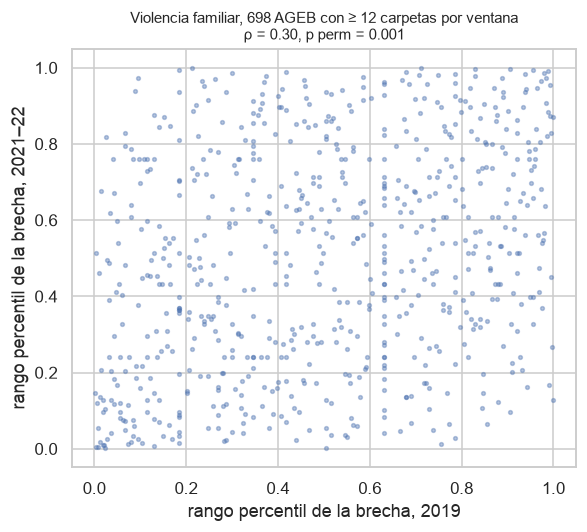

In [23]:
def estabilidad(x, y, B=1000, semilla=2026):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rho = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(semilla)
    nula = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(B)])
    rng = np.random.default_rng(semilla)
    boot = []
    for _ in range(B):
        i = rng.integers(0, len(x), len(x))
        boot.append(stats.spearmanr(x[i], y[i])[0])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"n_ageb": len(x), "rho": rho, "ic95_inf": lo, "ic95_sup": hi,
            "p95_nula": np.percentile(nula, 95), "p_perm": (1 + (nula >= rho).sum()) / (B + 1)}

def pares_ventanas(col, umbral):
    w = vf[[col, "carpetas"]].unstack("ventana")
    m = (w["carpetas"][VENT] >= umbral).all(axis=1)
    return w[col][VENT][m].dropna()

variantes = {
    f"principal: todas las llamadas, ≥ {UMBRAL} carpetas": ("brecha", UMBRAL),
    "sensibilidad: umbral ≥ 5": ("brecha", 5),
    f"sensibilidad: solo afirmativas, ≥ {UMBRAL}": ("brecha_afirm", UMBRAL),
    f"sensibilidad: 19% descontado (S1), ≥ {UMBRAL}": ("brecha_s1_19", UMBRAL),
}
vf["brecha_afirm"] = (vf.llamadas_afirmativas / vf.carpetas).where(vf.carpetas > 0)
s4 = pd.DataFrame({k: estabilidad(*pares_ventanas(c, u).to_numpy().T) for k, (c, u) in variantes.items()}).T
s4["n_ageb"] = s4.n_ageb.astype(int)
s4["veredicto"] = np.where(s4.rho > s4.p95_nula, "estable (ρ > p95 de la nula)", "no se distingue del azar")
display(s4)

xy = pares_ventanas("brecha", UMBRAL)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(stats.rankdata(xy["2019"]) / len(xy), stats.rankdata(xy["2021-22"]) / len(xy), s=6, alpha=.4)
ax.set_xlabel("rango percentil de la brecha, 2019"); ax.set_ylabel("rango percentil de la brecha, 2021–22")
ax.set_title(f"Violencia familiar, {len(xy):,} AGEB con ≥ {UMBRAL} carpetas por ventana\nρ = {s4.rho.iloc[0]:.2f}, p perm = {s4.p_perm.iloc[0]:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura (S4):** **S4 no se refuta.** Entre los 698 AGEB con ≥ 12 carpetas en cada ventana, la brecha de violencia familiar de 2019 y la de 2021–22 tienen **ρ = 0.30 (IC 95%: 0.23–0.37)**, contra un percentil 95 de la nula de 0.065. **p de permutación = 0.001**, el mínimo posible con 1,000 permutaciones: ninguna la alcanzó. Las tres sensibilidades declaradas dan lo mismo: umbral ≥ 5, ρ = 0.22 (IC 0.17–0.26; n = 1,624); solo afirmativas, 0.24 (0.17–0.31); 19% descontado, 0.26 (0.19–0.33).
- **Estable, pero moderada.** ρ ≈ 0.3 significa que el orden se repite mejor que el azar, no que se conserve AGEB por AGEB. Parte de la diferencia es ruido de Poisson: con 12 carpetas el ruido atenúa la ρ, y por eso con umbral 5 baja a 0.22. La ρ observada es, entonces, una cota inferior de la estabilidad de la brecha subyacente. Otra parte puede ser patrón de escala mayor que el AGEB (autocorrelación espacial), que separan el 2.3 y el 2.5.
- **Universo.** La prueba habla de los AGEB con volumen (698 de 2,433). Con umbral 5 (1,624 AGEB) se sostiene.
- **Qué cambia.** En la tabla de lectura conjunta del §3.1, violencia familiar queda en *estable*, y la conclusión depende de H3 (2.4). Juntar las dos ventanas es defendible para el **orden** de los AGEB, no para el **nivel** (1.00 vs 0.82). El 2.3 puede usar la brecha conjunta y reportar cada ventana como robustez.

### 8.6 Exportar `resultados/11_ageb_brecha_por_delito.csv`

In [24]:
COB = cob.set_index(["delito", "ventana", "alcaldia"]).cobertura
def a_csv(d, b):
    o = b.reset_index()
    o.insert(0, "delito", d)
    o.insert(3, "alcaldia", o.ageb.map(ageb.set_index("ageb").alcaldia))
    o["cobertura_coord_alcaldia"] = [COB.get((d, w, a), np.nan) for w, a in zip(o.ventana, o.alcaldia)]
    return o

g_cols = G.rename(columns=lambda c: f"grupo_{c}" if c != "alcaldia" else "grupo_alcaldia").drop(columns=["grupo_llamadas_afirmativas", "grupo_alcaldia"])
rc_out = rc.reset_index().merge(g_cols.reset_index(), on=["ventana", "grupo_h3"], how="left").set_index(["ventana", "ageb"])
out = pd.concat([a_csv("violencia_familiar", vf.drop(columns=["brecha_afirm"])), a_csv("robo_conductor", rc_out)], ignore_index=True)
orden_cols = ["delito", "ventana", "ageb", "alcaldia", "llamadas", "llamadas_afirmativas", "carpetas", "brecha", "brecha_ic95_inf", "brecha_ic95_sup",
              "brecha_ciudad", "clasificacion", "conteo_bajo", "viviendas", "viv_protegido", "viv_cero", "llamadas_por_1k_viv", "carpetas_por_1k_viv",
              "robo_ch_fgj", "llamadas_robo_desc_s1", "brecha_s1_19", "brecha_s1_19_ic95_inf", "brecha_s1_19_ic95_sup", "clasificacion_s1_19", "cambia_clasif_s1",
              "grupo_h3", "grupo_n_ageb", "grupo_llamadas", "grupo_carpetas", "grupo_brecha", "grupo_brecha_ic95_inf", "grupo_brecha_ic95_sup",
              "grupo_cumple_umbral", "cobertura_coord_alcaldia"]
out = out[orden_cols]
num = out.select_dtypes("number").columns
out[num] = out[num].replace([np.inf, -np.inf], np.nan).round(4)
assert len(out) == 2 * len(VENT) * len(ageb) and not out.duplicated(["delito", "ventana", "ageb"]).any()
out.to_csv(OUT / "11_ageb_brecha_por_delito.csv", index=False)
print(out.shape); display(out.groupby(["delito", "ventana"])[["llamadas", "carpetas"]].sum())
sorted(p.name for p in OUT.glob("*.csv"))

(9732, 34)


llamadas  carpetas
delito             ventana                    
robo_conductor     2019         8050      3767
                   2021-22      3214      1467
violencia_familiar 2019        25325     25294
                   2021-22     22937     28022

['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv']

## 9. Experimento 2.3 — H1: ¿la brecha varía más entre AGEB que entre alcaldías? (`resultados/13_`)

**H1** *(regla de decisión fijada el 8 de oct de 2026 en `PLAN_15_OCT.md` §3.3, antes de calcular cualquier componente de varianza)*: en violencia familiar, la brecha llamadas/carpeta varía más entre AGEB que entre alcaldías, y más de lo que daría el azar.

Esta sección **no recalcula la brecha ni los conteos**: lee `vf`, `rc` y `G` de la sección 8, que es lo mismo que `resultados/11_ageb_brecha_por_delito.csv`.

**Por qué no se descompone la varianza cruda de la razón.** La varianza de llamadas/carpeta entre AGEB mezcla dos cosas: variación territorial real y ruido de conteo. El ruido es mayor justo donde hay menos eventos, así que la varianza cruda ordenaría los territorios por volumen y no por fricción. Se trabaja en el **log de la brecha**, que es el logit de p = llamadas / (llamadas + carpetas): condicionando en n = llamadas + carpetas, llamadas ~ Binomial(n, p), log(brecha) = logit(p) y **la varianza de conteo es conocida en forma cerrada**.

**Modelo** (los componentes están en la escala del log de la brecha):

> log(brecha)_{g,w} = mu + delta_w + A_{alcaldia(g)} + B_g + I_{g,w} + e_{g,w},  Var(e_{g,w}) conocida

- `var_alcaldia` = Var(A): entre las 16 alcaldías.
- `var_unidad` = Var(B): entre AGEB **dentro** de la alcaldía (o entre grupos de H3, en el contraste).
- `var_interaccion` = Var(I): AGEB × ventana, la parte de la brecha de un AGEB que **no** se repite entre ventanas. Solo se identifica con las dos ventanas juntas; es la contraparte del rho = 0.30 de la sección 8.5.
- `delta_w`: efecto fijo de ventana, que absorbe la caída de nivel 1.00 → 0.82.

**Estimación por momentos, no con un GLMM.** Se usa el logit empírico con corrección de 0.5 (y = log((llamadas+0.5)/(carpetas+0.5)), v = 1/(llamadas+0.5) + 1/(carpetas+0.5)) y se resta la varianza binomial esperada con las esperanzas exactas del diseño anidado desbalanceado. *Supuesto:* uso momentos con la varianza binomial conocida asumiendo que el ruido dentro de un AGEB y ventana es binomial dado n; si hubiera sobredispersión extra dentro del AGEB (rachas de llamadas por el mismo hecho), `var_unidad` quedaría sobreestimada, y por eso se verifica la sobredispersión en 9.4 y se contrasta con una beta-binomial. Las tres razones para no usar un GLMM binomial con efectos aleatorios de alcaldía y AGEB están en el §3.3: las nulas exigen ~42,000 reajustes, el efecto aleatorio de ~2,400 niveles con 1–2 observaciones cada uno es donde menos sirven las aproximaciones de Laplace o variacionales, y la varianza binomial conocida hace exacta la corrección por momentos. **Lo importante:** las nulas se simulan con el *mismo* estimador, así que los valores p son válidos aunque el estimador tuviera sesgo de orden 1/n.

**Universo y peso.** Unidad = AGEB con **≥ 1 carpeta en cada ventana**, con **peso igual por AGEB**. *Supuesto:* peso igual porque la pregunta es cuánto varía la brecha entre territorios, no entre eventos; con peso por precisión (1/v) el resultado hablaría sobre todo del centro de la ciudad.

**Las dos pruebas** (§3.3): **(a)** `var_unidad` observada contra una nula de homogeneidad (cada unidad con la p de su alcaldía y ventana; llamadas ~ Binomial(n observado, p), 1,000 simulaciones, semilla 2026); **(b)** IC 95% bootstrap de `var_unidad / var_alcaldia` enteramente por encima de 1 (1,000 réplicas, remuestreo de AGEB **dentro** de cada alcaldía conservando su tamaño, semilla 2026), con el ICC de alcaldía contra una nula de permutación de etiquetas de alcaldía como contexto. **H1 se acepta solo si (a) y (b) se cumplen.**

**Autocorrelación espacial:** no invalida la nula de (a), que se simula unidad por unidad bajo homogeneidad; sí hace que `var_unidad` pueda ser un gradiente suave sub-alcaldía y no AGEB independientes (eso lo separa el I de Moran del 2.5). Para (b) la nula de permutación es **conservadora**: una partición arbitraria en 16 grupos tiene menos varianza entre grupos que una partición contigua, así que le facilita a la alcaldía parecer informativa. Por eso (b) se decide con el IC bootstrap de la razón.

### 9.1 Estimador: componentes de varianza con la varianza binomial restada

In [25]:
ALC_DE_AGEB = ageb.set_index("ageb").alcaldia
ALC = sorted(ageb.alcaldia.unique())
A_COD = {a: i for i, a in enumerate(ALC)}
K_ALC = len(ALC)
B_REP = 1000
SEMILLA = 2026

def _oneway(m, nu, g, K):
    # Anidado desbalanceado con varianza de ruido nu_g conocida por unidad.
    # Var(m_g) = s2_alc + s2_unidad + nu_g. Esperanzas exactas de las sumas de cuadrados.
    k = np.bincount(g, minlength=K).astype(float)
    nz = k > 0
    sm = np.bincount(g, weights=m, minlength=K)
    mb = np.zeros(K); mb[nz] = sm[nz] / k[nz]
    ss_w = float(((m - mb[g]) ** 2).sum())
    nu_a = np.bincount(g, weights=nu, minlength=K)
    den = float((k[nz] - 1).sum())
    s2u = (ss_w - float((nu_a[nz] * (1 - 1 / k[nz])).sum())) / den if den > 0 else np.nan
    tau = max(s2u, 0.0) + nu                      # varianza residual de m_g una vez fijada la alcaldía
    tau_a = np.bincount(g, weights=tau, minlength=K)
    N = float(k.sum()); gm = float(m.sum()) / N
    ss_b = float((k[nz] * (mb[nz] - gm) ** 2).sum())
    c = N - float((k ** 2).sum()) / N             # (N - sum k_a^2 / N), coeficiente del diseño desbalanceado
    s2a = (ss_b - float((tau_a[nz] / k[nz]).sum()) + float(tau.sum()) / N) / c
    return s2a, s2u

def componentes(Y, V, g, K=K_ALC):
    # Y, V: (n_unidades, n_ventanas). La media de columna es el efecto fijo de ventana.
    z = Y - Y.mean(axis=0, keepdims=True)
    vbar = V.mean(axis=1)
    if Y.shape[1] == 2:
        s2i = float(((z[:, 0] - z[:, 1]) ** 2 / 2).mean() - vbar.mean())
        nu = vbar / 2 + max(s2i, 0.0) / 2         # Var(media de las dos ventanas) = ... + s2_int/2 + vbar/2
    else:
        s2i = np.nan
        nu = vbar
    s2a, s2u = _oneway(z.mean(axis=1), nu, g, K)
    return s2a, s2u, s2i

def icc_razon(s2a, s2u, s2i):
    a, u = max(s2a, 0.0), max(s2u, 0.0)
    i = 0.0 if (s2i is None or np.isnan(s2i)) else max(s2i, 0.0)
    tot = a + u + i
    icc = a / tot if tot > 0 else np.nan
    raz = u / a if a > 0 else (np.inf if u > 0 else np.nan)
    return icc, raz

def y_v(ll_y, ll_n, car):
    # logit empirico: y usa el numerador efectivo (puede no ser entero), v usa el conteo observado
    return np.log((ll_y + 0.5) / (car + 0.5)), 1.0 / (ll_n + 0.5) + 1.0 / (car + 0.5)
print("estimador listo")

estimador listo


### 9.2 Armado de las variantes y universo

In [26]:
Wvf = vf[["llamadas", "llamadas_afirmativas", "carpetas", "llamadas_robo_desc_s1"]].unstack("ventana")
LLA = Wvf["llamadas"][VENT].to_numpy(float)
LLF = Wvf["llamadas_afirmativas"][VENT].to_numpy(float)
CAR = Wvf["carpetas"][VENT].to_numpy(float)
DESC = Wvf["llamadas_robo_desc_s1"][VENT].to_numpy(float)
G_VF = np.array([A_COD[a] for a in ALC_DE_AGEB.reindex(Wvf.index)])

V_PRIN = "principal: todas las llamadas, >= 1 carpeta por ventana"
V_UMB = f"sensibilidad: solo AGEB con >= {UMBRAL} carpetas por ventana"
V_S1 = "sensibilidad: 19% de robo descontado (S1)"
V_AFI = "sensibilidad: solo llamadas afirmativas"
V_GRU = "contraste a igual unidad: agregada a los grupos de H3"

def spec_vf(variante, ventanas):
    m = (CAR >= UMBRAL).all(1) if variante == V_UMB else (CAR >= 1).all(1)
    j = [VENT.index(w) for w in ventanas]
    sel = np.ix_(m, j)
    car = CAR[sel]
    if variante == V_AFI:
        lln = LLF[sel]; lly = lln
    elif variante == V_S1:
        lln = LLA[sel]; lly = lln - DESC[sel]
    else:
        lln = LLA[sel]; lly = lln
    return dict(delito="violencia_familiar", unidad="AGEB", variante=variante,
                ventana="ambas" if len(j) == 2 else ventanas[0],
                lly=lly, lln=lln, car=car, g=G_VF[m], n_llamadas=lly.sum(), n_carpetas=car.sum())

def spec_rc(ventana):
    gg = G.xs(ventana)
    gg = gg[gg.cumple_umbral]
    lln = gg.llamadas.to_numpy(float)[:, None]; car = gg.carpetas.to_numpy(float)[:, None]
    return dict(delito="robo_conductor", unidad="grupo_h3", variante="contraste: grupos de H3 (regla del 5 de oct)",
                ventana=ventana, lly=lln, lln=lln, car=car,
                g=np.array([A_COD[a] for a in gg.alcaldia]), n_llamadas=lln.sum(), n_carpetas=car.sum())

GRUPO_DE_AGEB = rc.grupo_h3.groupby("ageb").first()
def spec_vf_grupos(ventana):
    # Agregada a los MISMOS grupos de H3, para que el contraste con robo a conductor compare unidades del mismo tamano
    q = vf.xs(ventana)[["llamadas", "carpetas"]].copy()
    q["grupo_h3"] = GRUPO_DE_AGEB.reindex(q.index)
    ok = G.xs(ventana).cumple_umbral
    q = q[q.grupo_h3.map(ok).fillna(False).to_numpy()].groupby("grupo_h3").sum()
    lln = q.llamadas.to_numpy(float)[:, None]; car = q.carpetas.to_numpy(float)[:, None]
    alc_g = {gr: a for gr, a in zip(G.xs(ventana).index, G.xs(ventana).alcaldia)}
    return dict(delito="violencia_familiar", unidad="grupo_h3", variante=V_GRU, ventana=ventana,
                lly=lln, lln=lln, car=car, g=np.array([A_COD[alc_g[gr]] for gr in q.index]),
                n_llamadas=lln.sum(), n_carpetas=car.sum())

def completa(sp):
    sp["Y"], sp["V"] = y_v(sp["lly"], sp["lln"], sp["car"])
    sp["fac"] = np.where(sp["lln"] > 0, sp["lly"] / np.maximum(sp["lln"], 1e-12), 1.0)
    n_tot = (sp["lln"] + sp["car"]).round().astype(np.int64)
    num = np.column_stack([np.bincount(sp["g"], weights=sp["lln"][:, c], minlength=K_ALC) for c in range(n_tot.shape[1])])
    tot = np.column_stack([np.bincount(sp["g"], weights=n_tot[:, c].astype(float), minlength=K_ALC) for c in range(n_tot.shape[1])])
    p_cel = np.divide(num, tot, out=np.full_like(num, 0.5), where=tot > 0)
    sp["n_tot"], sp["P"], sp["p_cel"] = n_tot, p_cel[sp["g"]], p_cel
    sp["n_unidades"] = len(sp["g"]); sp["n_alcaldias"] = int((np.bincount(sp["g"], minlength=K_ALC) > 0).sum())
    return sp

SPECS = [completa(spec_vf(v, w)) for v in (V_PRIN, V_UMB, V_S1, V_AFI) for w in (VENT, ["2019"], ["2021-22"])]
SPECS += [completa(spec_vf_grupos(w)) for w in VENT]
SPECS += [completa(spec_rc(w)) for w in VENT]
print("Llamadas afirmativas por AGEB y ventana (media / mediana):",
      {w: (round(LLF[(CAR >= 1).all(1), i].mean(), 2), float(np.median(LLF[(CAR >= 1).all(1), i]))) for i, w in enumerate(VENT)})
print(f"AGEB con >= 1 carpeta en cada ventana: {int((CAR >= 1).all(1).sum()):,} de {len(CAR):,} "
      f"(cubren {CAR[(CAR >= 1).all(1)].sum() / CAR.sum():.3%} de las carpetas y {LLA[(CAR >= 1).all(1)].sum() / LLA.sum():.3%} de las llamadas de violencia familiar)")
print(f"AGEB con >= {UMBRAL} carpetas en cada ventana: {int((CAR >= UMBRAL).all(1).sum()):,} "
      f"(cubren {CAR[(CAR >= UMBRAL).all(1)].sum() / CAR.sum():.3%} de las carpetas)")
display(pd.DataFrame([{k: s[k] for k in ("delito", "variante", "ventana", "unidad", "n_unidades", "n_alcaldias", "n_llamadas", "n_carpetas")} for s in SPECS]))

Llamadas afirmativas por AGEB y ventana (media / mediana): {'2019': (np.float64(1.6), 1.0), '2021-22': (np.float64(2.4), 1.0)}
AGEB con >= 1 carpeta en cada ventana: 2,294 de 2,433 (cubren 99.501% de las carpetas y 99.101% de las llamadas de violencia familiar)
AGEB con >= 12 carpetas en cada ventana: 698 (cubren 55.302% de las carpetas)


,delito,variante,ventana,unidad,n_unidades,n_alcaldias,n_llamadas,n_carpetas
0,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",ambas,AGEB,2294,16,"47,828.000","53,050.000"
1,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2019,AGEB,2294,16,"25,104.000","25,173.000"
2,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2021-22,AGEB,2294,16,"22,724.000","27,877.000"
3,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,ambas,AGEB,698,16,"24,282.000","29,485.000"
4,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2019,AGEB,698,16,"12,707.000","14,202.000"
5,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2021-22,AGEB,698,16,"11,575.000","15,283.000"
6,violencia_familiar,sensibilidad: 19% de robo descontado (S1),ambas,AGEB,2294,16,"39,316.736","53,050.000"
7,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2019,AGEB,2294,16,"20,657.722","25,173.000"
8,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2021-22,AGEB,2294,16,"18,659.014","27,877.000"
9,violencia_familiar,sensibilidad: solo llamadas afirmativas,ambas,AGEB,2294,16,"9,177.000","53,050.000"


**Lectura (universo y variantes):** la prueba corre sobre **2,294 de los 2,433 AGEB**, los que tienen al menos una carpeta de violencia familiar en **cada** ventana; cubren **99.5% de las carpetas y 99.1% de las llamadas**. Los 139 que quedan fuera tienen cero carpetas en alguna ventana, así que su log de la brecha no existe. La sensibilidad de ≥ 12 carpetas por ventana deja 698 AGEB (el mismo universo de la prueba de estabilidad de 8.5) con 55.3% de las carpetas. Las llamadas **afirmativas** son 1.6 (2019) y 2.4 (2021–22) por AGEB en promedio, con mediana 1: hay que esperar que esa sensibilidad sea la más frágil, y lo es (9.3).

### 9.3 Nulas por permutación y simulación, e IC bootstrap

In [27]:
def nula_homogeneidad(sp, B=B_REP, semilla=SEMILLA):
    # (a) cada unidad con la p de su alcaldia y ventana; n observado fijo
    rng = np.random.default_rng(semilla)
    out = np.empty((B, 2))
    for b in range(B):
        ll = rng.binomial(sp["n_tot"], sp["P"]).astype(float)
        car = sp["n_tot"] - ll
        Y, V = y_v(sp["fac"] * ll, ll, car)
        s2a, s2u, s2i = componentes(Y, V, sp["g"])
        out[b] = (s2u, s2i if sp["Y"].shape[1] == 2 else np.nan)
    return out

def nula_etiquetas(sp, s2i_obs, B=B_REP, semilla=SEMILLA):
    # (b) reasigna alcaldias a las unidades conservando el tamano de cada alcaldia
    rng = np.random.default_rng(semilla)
    z = sp["Y"] - sp["Y"].mean(axis=0, keepdims=True)
    vbar = sp["V"].mean(axis=1)
    nu = vbar / 2 + max(0.0, 0.0 if np.isnan(s2i_obs) else s2i_obs) / 2 if sp["Y"].shape[1] == 2 else vbar
    m = z.mean(axis=1)
    out = np.empty(B)
    for b in range(B):
        s2a, s2u = _oneway(m, nu, rng.permutation(sp["g"]), K_ALC)
        out[b] = icc_razon(s2a, s2u, s2i_obs)[0]
    return out

def bootstrap(sp, B=B_REP, semilla=SEMILLA):
    # remuestreo de unidades DENTRO de cada alcaldia, conservando su tamano
    rng = np.random.default_rng(semilla)
    ix = [np.where(sp["g"] == a)[0] for a in range(K_ALC)]
    ix = [i for i in ix if len(i)]
    Y, V, g = sp["Y"], sp["V"], sp["g"]
    out = np.empty((B, 5))
    for b in range(B):
        s = np.concatenate([rng.choice(i, len(i), replace=True) for i in ix])
        s2a, s2u, s2i = componentes(Y[s], V[s], g[s])
        out[b] = (s2a, s2u, s2i, *icc_razon(s2a, s2u, s2i))
    return out

def evalua(sp):
    s2a, s2u, s2i = componentes(sp["Y"], sp["V"], sp["g"])
    icc, raz = icc_razon(s2a, s2u, s2i)
    bo = bootstrap(sp)
    q = lambda c: np.nanpercentile(bo[:, c], [2.5, 97.5])
    na = nula_homogeneidad(sp)
    nb = nula_etiquetas(sp, s2i)
    pa = (1 + (na[:, 0] >= s2u).sum()) / (B_REP + 1)
    pai = (1 + (na[:, 1] >= s2i).sum()) / (B_REP + 1) if sp["Y"].shape[1] == 2 else np.nan
    interp = bool(s2u > 0)
    pb = (1 + (nb >= icc).sum()) / (B_REP + 1) if interp else np.nan
    # sobredispersion de Pearson con p de alcaldia x ventana
    mu = sp["n_tot"] * sp["P"]
    pear = ((sp["lln"] - mu) ** 2 / np.maximum(mu * (1 - sp["P"]), 1e-9)).sum()
    gl = sp["n_tot"].size - int((np.bincount(sp["g"], minlength=K_ALC) > 0).sum()) * sp["n_tot"].shape[1]
    ok_a = interp and (s2u > np.percentile(na[:, 0], 95)) and (pa <= 0.05)
    ok_b = interp and (q(4)[0] > 1)
    nan_si = lambda x: x if interp else np.nan
    u = sp["unidad"]
    fila = {**{k: sp[k] for k in ("delito", "variante", "ventana", "unidad", "n_unidades", "n_alcaldias")},
            "n_llamadas": sp["n_llamadas"], "n_carpetas": sp["n_carpetas"],
            "var_alcaldia": s2a, "var_alcaldia_ic95_inf": q(0)[0], "var_alcaldia_ic95_sup": q(0)[1],
            "var_unidad": s2u, "var_unidad_ic95_inf": q(1)[0], "var_unidad_ic95_sup": q(1)[1],
            "var_interaccion": s2i, "var_interaccion_ic95_inf": q(2)[0], "var_interaccion_ic95_sup": q(2)[1],
            "icc_alcaldia": nan_si(icc), "icc_alcaldia_ic95_inf": nan_si(q(3)[0]), "icc_alcaldia_ic95_sup": nan_si(q(3)[1]),
            "razon_unidad_alcaldia": nan_si(raz), "razon_ic95_inf": nan_si(q(4)[0]), "razon_ic95_sup": nan_si(q(4)[1]),
            "estadistico_a": s2u, "p95_nula_a": np.percentile(na[:, 0], 95), "p_perm_a": pa,
            "p_perm_a_interaccion": pai,
            "estadistico_b": nan_si(icc), "p95_nula_b": nan_si(np.percentile(nb, 95)), "p_perm_b": pb,
            "sobredispersion_pearson": pear / gl, "interpretable": interp,
            "veredicto_a": (f"variacion real entre {u}" if ok_a else "no se distingue del ruido de conteo") if interp
                           else "no interpretable: varianza corregida negativa",
            "veredicto_b": (f"mas entre {u} que entre alcaldias" if ok_b else "no se puede afirmar") if interp else "no interpretable"}
    if not interp:
        fila["veredicto_h1"] = "no concluyente: conteos demasiado chicos para corregir el ruido"
    elif sp["delito"] == "robo_conductor" or sp["variante"] == V_GRU:
        fila["veredicto_h1"] = "contraste (debil por diseno), no prueba de H1"
    elif ok_a and ok_b:
        fila["veredicto_h1"] = "H1 se acepta"
    elif ok_a:
        fila["veredicto_h1"] = "variacion real, pero no mas fina que la alcaldia"
    else:
        fila["veredicto_h1"] = "H1 se refuta (falla (a))"
    return fila

h1 = pd.DataFrame([evalua(s) for s in SPECS])
display(h1[["delito", "variante", "ventana", "n_unidades", "var_alcaldia", "var_unidad", "var_interaccion",
            "icc_alcaldia", "razon_unidad_alcaldia", "p_perm_a", "p_perm_b", "veredicto_h1"]])
display(h1[h1.variante == V_PRIN].set_index("ventana")[["var_alcaldia", "var_alcaldia_ic95_inf", "var_alcaldia_ic95_sup",
    "var_unidad", "var_unidad_ic95_inf", "var_unidad_ic95_sup", "var_interaccion", "icc_alcaldia",
    "icc_alcaldia_ic95_inf", "icc_alcaldia_ic95_sup", "razon_ic95_inf", "estadistico_a", "p95_nula_a", "p_perm_a"]].T)

,delito,variante,ventana,n_unidades,var_alcaldia,var_unidad,var_interaccion,icc_alcaldia,razon_unidad_alcaldia,p_perm_a,p_perm_b,veredicto_h1
0,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",ambas,2294,0.021,0.102,0.070,0.110,4.820,0.001,0.001,H1 se acepta
1,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2019,2294,0.014,0.228,NaN,0.057,16.614,0.001,0.001,H1 se acepta
2,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2021-22,2294,0.035,0.109,NaN,0.241,3.144,0.001,0.001,H1 se acepta
3,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,ambas,698,0.019,0.094,0.078,0.099,5.012,0.001,0.001,H1 se acepta
4,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2019,698,0.022,0.177,NaN,0.110,8.072,0.001,0.001,H1 se acepta
5,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2021-22,698,0.020,0.162,NaN,0.111,7.972,0.001,0.001,H1 se acepta
6,violencia_familiar,sensibilidad: 19% de robo descontado (S1),ambas,2294,0.044,0.137,0.345,0.084,3.104,0.001,0.001,H1 se acepta
7,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2019,2294,0.045,0.518,NaN,0.079,11.634,0.001,0.001,H1 se acepta
8,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2021-22,2294,0.050,0.440,NaN,0.103,8.748,0.001,0.001,H1 se acepta
9,violencia_familiar,sensibilidad: solo llamadas afirmativas,ambas,2294,0.087,-0.142,-0.422,NaN,NaN,0.001,NaN,no concluyente: conteos demasiado chicos para corregir el ruido


ventana,ambas,2019,2021-22
var_alcaldia,0.021,0.014,0.035
var_alcaldia_ic95_inf,0.016,0.009,0.026
var_alcaldia_ic95_sup,0.030,0.028,0.050
var_unidad,0.102,0.228,0.109
var_unidad_ic95_inf,0.072,0.185,0.074
var_unidad_ic95_sup,0.127,0.265,0.135
var_interaccion,0.070,NaN,NaN
icc_alcaldia,0.110,0.057,0.241
icc_alcaldia_ic95_inf,0.085,0.039,0.188
icc_alcaldia_ic95_sup,0.158,0.115,0.365


**Lectura (H1):** **H1 se acepta.** Con las dos ventanas juntas y efecto fijo de ventana, sobre 2,294 AGEB (47,828 llamadas y 53,050 carpetas):

| componente (escala: log de la brecha) | estimación | IC 95% bootstrap | 1 desv. est. en brecha relativa |
|---|---|---|---|
| entre **alcaldías** (σ²_alc) | **0.021** | 0.016 – 0.030 | ×1.16 |
| entre **AGEB** dentro de la alcaldía (σ²_ageb) | **0.102** | 0.072 – 0.127 | ×1.38 |
| **AGEB × ventana** (σ²_int) | 0.070 | 0.039 – 0.101 | ×1.30 |
| **ICC de alcaldía** | **0.110** | 0.085 – 0.158 | — |
| **razón σ²_ageb / σ²_alc** | **4.82** | **2.81 – 6.44** | — |

- **(a) Hay variación real entre AGEB.** σ̂²_ageb = 0.102 contra un percentil 95 de la nula de homogeneidad de **−0.012**: **p = 0.001**, el mínimo posible con 1,000 simulaciones (ninguna la alcanzó). La nula está centrada **por debajo de cero** porque la corrección de 0.5 del logit empírico encoge y la resta del ruido queda un poco larga; por eso la prueba se hace contra la nula simulada y no contra cero, y por eso el estimador puntual es **conservador** (9.4, calibración).
- **(b) Varía más entre AGEB que entre alcaldías.** El IC 95% bootstrap de la razón queda **enteramente por encima de 1** (2.81 – 6.44), así que (b) se cumple con la regla del §3.3. La alcaldía se queda con el **11% de la varianza** (ICC 0.110; IC 0.085–0.158) y el 89% es sub-alcaldía: 53% entre AGEB y 36% AGEB × ventana. En términos de la brecha: entre dos AGEB de la misma alcaldía, una desviación estándar equivale a una brecha **38% mayor o menor**; entre dos alcaldías, solo **16%**.
- *Contexto de la nula de etiquetas:* el ICC observado (0.110) **sí** supera el percentil 95 de reasignar alcaldías al azar conservando su tamaño (0.010; p = 0.001). Es decir, las fronteras de alcaldía **no son irrelevantes** —captan más que una partición arbitraria—, solo son el grano equivocado: explican una novena parte de lo que explica el AGEB. Y esa nula es conservadora con autocorrelación espacial (§3.3), así que el 11% es un techo generoso para la alcaldía.
- **σ²_int = 0.070 es del mismo orden que σ²_ageb = 0.102** (p = 0.001 contra su propia nula): un tercio largo de la variación territorial de un AGEB **no se repite** entre 2019 y 2021–22. Es la misma cosa que el ρ = 0.30 de 8.5 vista desde la varianza, y la razón por la que el mapa del 2.6 debe pintar el promedio de las dos ventanas y no una sola.

**Robustez, como exigía el §3.3:** el veredicto se repite en **9 de las 9 filas interpretables**.
- *Por ventana:* 2019 razón 16.6 (IC 7.7–25.0), ICC 0.057; 2021–22 razón 3.14 (IC 1.74–4.32), ICC 0.241. En una sola ventana σ²_ageb y σ²_int no se separan, así que el 0.228 de 2019 y el 0.109 de 2021–22 son la suma de ambos. **La alcaldía pesa cuatro veces más en 2021–22 que en 2019** (ICC 0.24 vs 0.06): el cambio de nivel de la brecha entre ventanas no fue parejo entre alcaldías. Hay que decirlo, porque matiza S4: el orden de los AGEB se repite, pero el nivel se movió de forma distinta en cada alcaldía.
- *Solo AGEB con ≥ 12 carpetas (698):* razón 5.01 (IC 2.10–7.32), ICC 0.099, casi idéntico al principal. **El resultado no lo producen los AGEB de conteo bajo.**
- *Con 19% de robo descontado (S1):* razón 3.10 (IC 1.82–4.19), ICC 0.084. Sigue aceptándose, pero el descuento **sube** σ²_alc (0.021 → 0.044) y sobre todo σ²_int (0.070 → 0.345), porque el robo a casa que se descuenta es él mismo territorial y cambia entre ventanas. Es exactamente lo que S1 temía, y aun así no invierte ninguno de los dos veredictos: la contaminación añade ruido territorial, no reordena quién varía más.
- *Solo llamadas afirmativas:* **no concluyente, no contraria.** Con 1.6 y 2.4 llamadas afirmativas por AGEB, la mayoría de los AGEB tiene cero, el logit empírico las encoge a log(0.5/(carpetas+0.5)) y la varianza binomial nominal (1/0.5 = 2) sobrepasa a la varianza real de ese valor encogido: la resta del ruido da **negativo** (−0.14) y los componentes no se pueden leer. La fila se marca `interpretable = False` y no entra en el veredicto. La misma sensibilidad **sí** funciona en 8.5 (ρ = 0.24) porque una prueba de rangos no necesita corregir ruido. *Supuesto implícito que esto deja al descubierto:* uso todas las llamadas como numerador asumiendo que el código de cierre no se puede depurar igual en las dos ventanas (sección 8); con solo afirmativas el grano AGEB simplemente no tiene eventos suficientes para descomponer varianzas, y si se quisiera esa variante habría que agregar a grupos.

### 9.4 Verificación de supuestos: sobredispersión, contraste beta-binomial y residuos por tamaño de AGEB

In [28]:
sp0 = [s for s in SPECS if s["delito"] == "violencia_familiar" and s["variante"] == V_PRIN and s["ventana"] == "ambas"][0]

# (i) cuanta de la varianza observada es ruido de conteo
z0 = sp0["Y"] - sp0["Y"].mean(axis=0, keepdims=True)
print(f"Varianza observada del log de la brecha (cruda, las dos ventanas): {z0.var(ddof=1):.4f} | "
      f"ruido binomial esperado: {sp0['V'].mean():.4f} | razon obs/ruido: {z0.var(ddof=1) / sp0['V'].mean():.2f}")
print(f"Sobredispersion de Pearson (p de alcaldia x ventana): {h1.loc[(h1.variante == V_PRIN) & (h1.ventana == 'ambas'), 'sobredispersion_pearson'].iloc[0]:.2f} "
      "(1.0 = binomial puro; > 1 = hay variacion dentro de la alcaldia)")

# (ii) contraste de verosimilitud: beta-binomial por alcaldia x ventana
def bb_mle(k, n):
    def nll(th):
        mu, rho = 1 / (1 + np.exp(-th[0])), 1 / (1 + np.exp(-th[1]))
        a, b = mu * (1 - rho) / rho, (1 - mu) * (1 - rho) / rho
        return -(special.betaln(k + a, n - k + b) - special.betaln(a, b)).sum()
    r = optimize.minimize(nll, [0.0, -4.0], method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-8, "maxiter": 4000})
    mu, rho = 1 / (1 + np.exp(-r.x[0])), 1 / (1 + np.exp(-r.x[1]))
    return mu, rho, r.success

bb = []
for c, w in enumerate(VENT):
    for a in range(K_ALC):
        s = sp0["g"] == a
        if s.sum() < 5:
            continue
        mu, rho, okc = bb_mle(sp0["lln"][s, c], sp0["n_tot"][s, c].astype(float))
        bb.append({"ventana": w, "alcaldia": ALC[a], "n_ageb": int(s.sum()), "mu": mu, "rho": rho,
                   "var_logit_delta": rho / (mu * (1 - mu)), "convergio": okc})
bb = pd.DataFrame(bb)
pond = (bb.var_logit_delta * bb.n_ageb).sum() / bb.n_ageb.sum()
r0 = h1[(h1.variante == V_PRIN) & (h1.ventana == "ambas")].iloc[0]
print(f"Beta-binomial: {bb.convergio.sum()} de {len(bb)} celdas alcaldia x ventana convergieron | "
      f"rho mediano {bb.rho.median():.4f} | Var(logit) ponderada por AGEB = {pond:.4f}")
print(f"Momentos, misma cantidad (var_unidad + var_interaccion) = {max(r0.var_unidad, 0) + max(r0.var_interaccion, 0):.4f}  "
      f"-> razon beta-binomial / momentos = {pond / (max(r0.var_unidad, 0) + max(r0.var_interaccion, 0)):.2f}")
display(bb.groupby("ventana")[["mu", "rho", "var_logit_delta"]].describe(percentiles=[.5]).T)

# (iii) residuos por tamano de AGEB: el estimador no debe depender del tercil de conteo
car_med = sp0["car"].mean(axis=1)
terc = pd.qcut(car_med, 3, labels=["bajo", "medio", "alto"])
diag = []
for t in ["bajo", "medio", "alto"]:
    s = np.asarray(terc == t)
    s2a, s2u, s2i = componentes(sp0["Y"][s], sp0["V"][s], sp0["g"][s])
    zz = sp0["Y"][s] - sp0["Y"][s].mean(axis=0, keepdims=True)
    diag.append({"tercil_carpetas": t, "n_ageb": int(s.sum()), "carpetas_mediana": float(np.median(car_med[s])),
                 "var_cruda": float(zz.var(ddof=1)), "ruido_esperado": float(sp0["V"][s].mean()),
                 "razon_obs_ruido": float(zz.var(ddof=1) / sp0["V"][s].mean()),
                 "var_alcaldia": s2a, "var_unidad": s2u, "var_interaccion": s2i,
                 "icc_alcaldia": icc_razon(s2a, s2u, s2i)[0]})
diag = pd.DataFrame(diag)
display(diag)

# (iv) calibracion del estimador EN EL DISENO REAL: se inyectan componentes conocidos y se mide el sesgo
def calibra(sp, s2a_v, s2u_v, s2i_v, R=200, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    pw = sp["lln"].sum(axis=0) / sp["n_tot"].sum(axis=0)        # nivel de ciudad por ventana, igual para todas las alcaldias:
    base = np.log(pw / (1 - pw))[None, :]                        # asi la unica verdad son los componentes inyectados
    acc = []
    for _ in range(R):
        Av = rng.normal(0, np.sqrt(s2a_v), K_ALC)[sp["g"]][:, None] if s2a_v > 0 else 0.0
        Bv = rng.normal(0, np.sqrt(s2u_v), sp["n_unidades"])[:, None] if s2u_v > 0 else 0.0
        Iv = rng.normal(0, np.sqrt(s2i_v), sp["n_tot"].shape) if s2i_v > 0 else 0.0
        p = 1 / (1 + np.exp(-(base + Av + Bv + Iv)))
        ll = rng.binomial(sp["n_tot"], p).astype(float)
        Y, V = y_v(ll, ll, sp["n_tot"] - ll)
        acc.append(componentes(Y, V, sp["g"]))
    a = np.array(acc)
    e = [a[:, 0].mean(), a[:, 1].mean(), np.nanmean(a[:, 2])]
    return {"caso": f"alc={s2a_v:.3f} unidad={s2u_v:.3f} int={s2i_v:.3f}",
            "var_alcaldia_est": e[0], "var_unidad_est": e[1], "var_interaccion_est": e[2],
            "sesgo_alcaldia": e[0] - s2a_v, "sesgo_unidad": e[1] - s2u_v, "sesgo_interaccion": e[2] - s2i_v,
            "razon_verdad": (s2u_v / s2a_v) if s2a_v > 0 else np.nan,
            "razon_est": (max(e[1], 0) / e[0]) if e[0] > 0 else np.nan}
cal = pd.DataFrame([calibra(sp0, 0.0, 0.0, 0.0),
                    calibra(sp0, round(max(r0.var_alcaldia, 0), 3), round(max(r0.var_unidad, 0), 3), round(max(r0.var_interaccion, 0), 3)),
                    calibra(sp0, round(max(r0.var_unidad, 0), 3), round(max(r0.var_alcaldia, 0), 3), round(max(r0.var_interaccion, 0), 3))])
display(cal)

Varianza observada del log de la brecha (cruda, las dos ventanas): 0.6015 | ruido binomial esperado: 0.4110 | razon obs/ruido: 1.46
Sobredispersion de Pearson (p de alcaldia x ventana): 2.02 (1.0 = binomial puro; > 1 = hay variacion dentro de la alcaldia)
Beta-binomial: 32 de 32 celdas alcaldia x ventana convergieron | rho mediano 0.0456 | Var(logit) ponderada por AGEB = 0.1955
Momentos, misma cantidad (var_unidad + var_interaccion) = 0.1713  -> razon beta-binomial / momentos = 1.14


ventana                 2019  2021-22
mu              count 16.000   16.000
                mean   0.470    0.421
                std    0.044    0.052
                min    0.376    0.282
                50%    0.475    0.421
                max    0.529    0.508
rho             count 16.000   16.000
                mean   0.054    0.040
                std    0.013    0.015
                min    0.020    0.017
                50%    0.057    0.039
                max    0.076    0.071
var_logit_delta count 16.000   16.000
                mean   0.219    0.164
                std    0.054    0.059
                min    0.082    0.070
                50%    0.228    0.159
                max    0.305    0.287

,tercil_carpetas,n_ageb,carpetas_mediana,var_cruda,ruido_esperado,razon_obs_ruido,var_alcaldia,var_unidad,var_interaccion,icc_alcaldia
0,bajo,812,4.500,0.904,0.796,1.136,0.019,0.125,-0.068,0.133
1,medio,754,10.000,0.518,0.264,1.962,0.024,0.067,0.166,0.092
2,alto,728,19.000,0.338,0.134,2.520,0.021,0.071,0.113,0.104


,caso,var_alcaldia_est,var_unidad_est,var_interaccion_est,sesgo_alcaldia,sesgo_unidad,sesgo_interaccion,razon_verdad,razon_est
0,alc=0.000 unidad=0.000 int=0.000,-0.000,-0.021,-0.043,-0.000,-0.021,-0.043,NaN,NaN
1,alc=0.021 unidad=0.102 int=0.070,0.022,0.100,0.016,0.001,-0.002,-0.054,4.857,4.637
2,alc=0.102 unidad=0.021 int=0.070,0.100,0.020,0.016,-0.002,-0.001,-0.054,0.206,0.200


**Lectura (supuestos verificados):** las cuatro verificaciones apuntan en la misma dirección y ninguna obliga a cambiar el veredicto.

1. **El 68% de la varianza cruda del log de la brecha es ruido de conteo** (0.411 de 0.602). Esto es la justificación empírica de no descomponer la razón cruda: dos tercios de lo que se vería serían los AGEB con pocos eventos. La sobredispersión de Pearson con la p de alcaldía × ventana es **2.02**, es decir, hay el doble de dispersión que la binomial pura: hay variación real dentro de la alcaldía, que es (a) por otra vía.
2. **Contraste beta-binomial (verosimilitud, no momentos):** las **32 de 32** celdas alcaldía × ventana convergieron; ρ mediano 0.046 (rango 0.017–0.076); llevado a la escala logit por delta y ponderado por AGEB da **Var = 0.196**, contra **0.171** de los momentos para la misma cantidad (σ²_ageb + σ²_int). Coinciden dentro del **14%**, y la beta-binomial da *más*, así que los momentos son la opción conservadora. Los dos caminos concuerdan: la variación sub-alcaldía existe y no es un artefacto del estimador.
3. **Residuos por tamaño de AGEB:** la razón observada/ruido sube con el conteo (1.14 → 1.96 → 2.52 del tercil bajo al alto), que es lo esperado porque el ruido se encoge. Lo que importa es que **el ICC de alcaldía es estable entre terciles** (0.133 / 0.092 / 0.104): la conclusión no la fabrica un tramo de tamaño. La señal de alerta está en el tercil bajo (mediana 4.5 carpetas), donde σ²_int sale **negativo** (−0.068): ahí la corrección del ruido se pasa. Esa es justamente la sensibilidad de ≥ 12 carpetas, que da ICC 0.099.
4. **Calibración del estimador en el diseño real** (mismos n y mismos tamaños de alcaldía, 200 réplicas, componentes inyectados conocidos):
   - Sin variación verdadera: σ̂²_alc = **−0.000**, σ̂²_ageb = **−0.021**, σ̂²_int = **−0.043**. El estimador de alcaldía es insesgado; los de AGEB e interacción traen un desplazamiento negativo de ese orden, así que **las cifras reportadas son cotas inferiores** (los valores verdaderos rondarían 0.12 y 0.11, no 0.10 y 0.07).
   - Con la verdad igual a lo observado (0.021 / 0.102 / 0.070): recupera **0.022 / 0.100 / 0.016** y una razón de **4.64** contra 4.86 verdadera, menos de 5% de error.
   - **Con la verdad invertida** (alcaldía 0.102, AGEB 0.021): recupera 0.100 / 0.020 y razón **0.200** contra 0.206. Esta es la verificación que importa para (b): **el estimador no inventa predominio del AGEB cuando la verdad es que domina la alcaldía.**
   *Supuesto:* la calibración inyecta efectos normales en la escala logit asumiendo que esa forma es razonable para la brecha; si la verdadera distribución fuera muy asimétrica o con colas gruesas, el sesgo medido cambiaría de magnitud pero no el sentido de la verificación, que es si el estimador puede producir la razón observada a partir de una verdad distinta.

### 9.5 Figura: nula de (a) y componentes por variante

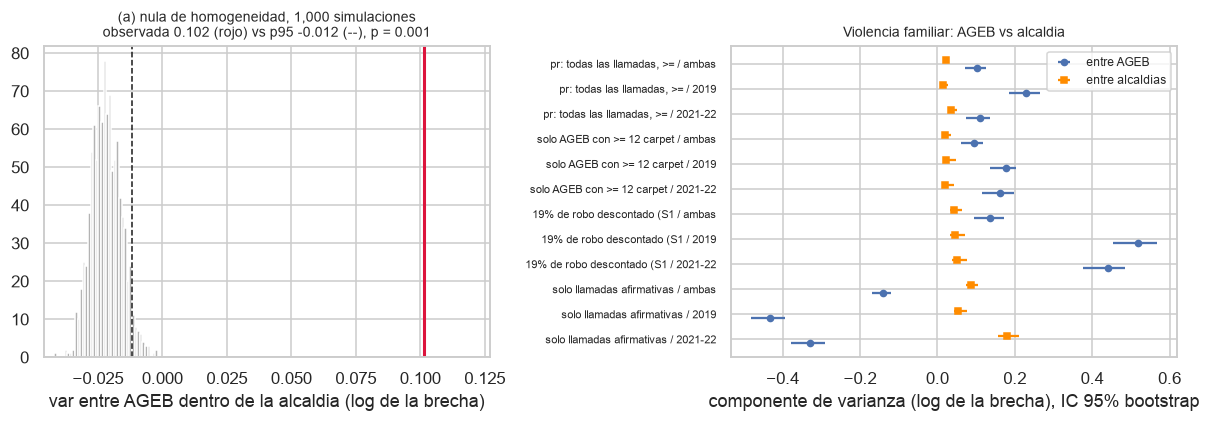

In [29]:
na0 = nula_homogeneidad(sp0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.hist(na0[:, 0], bins=40, color="0.7", edgecolor="white")
ax.axvline(r0.var_unidad, color="crimson", lw=2)
ax.axvline(np.percentile(na0[:, 0], 95), color="k", ls="--", lw=1)
ax.set_xlim(min(na0[:, 0].min(), 0) * 1.1, max(r0.var_unidad, np.percentile(na0[:, 0], 95)) * 1.25)
ax.set_xlabel("var entre AGEB dentro de la alcaldia (log de la brecha)")
ax.set_title(f"(a) nula de homogeneidad, {B_REP:,} simulaciones\nobservada {r0.var_unidad:.3f} (rojo) vs p95 {np.percentile(na0[:, 0], 95):.3f} (--), p = {r0.p_perm_a:.3f}", fontsize=9)
ax = axes[1]
sub = h1[(h1.delito == "violencia_familiar") & (h1.variante != V_GRU)].copy()
sub["eti"] = sub.variante.str.replace("sensibilidad: ", "").str.replace("principal: ", "pr: ").str[:26] + " / " + sub.ventana
yy = np.arange(len(sub))
ax.errorbar(sub.var_unidad, yy + .15, xerr=[sub.var_unidad - sub.var_unidad_ic95_inf, sub.var_unidad_ic95_sup - sub.var_unidad], fmt="o", ms=4, label="entre AGEB")
ax.errorbar(sub.var_alcaldia, yy - .15, xerr=[sub.var_alcaldia - sub.var_alcaldia_ic95_inf, sub.var_alcaldia_ic95_sup - sub.var_alcaldia], fmt="s", ms=4, color="darkorange", label="entre alcaldias")
ax.set_yticks(yy); ax.set_yticklabels(sub.eti, fontsize=7); ax.invert_yaxis()
ax.set_xlabel("componente de varianza (log de la brecha), IC 95% bootstrap")
ax.set_title("Violencia familiar: AGEB vs alcaldia", fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura (contraste con robo a conductor, a igual unidad):** el contraste del §3.3 pedía los 76 grupos de H3 como unidad. Al correrlo quedó claro que **76 grupos de 22 AGEB y 2,294 AGEB no son unidades comparables**, así que se agregó la violencia familiar a **los mismos 76 grupos** (fila `contraste a igual unidad`). Esta fila se añadió después de ver el tamaño de las unidades, **no entra en la regla de decisión de H1** (que se decide con las filas de AGEB) y solo sirve para leer el contraste.

| unidad = los 76 grupos de H3 | σ²_alc | σ²_grupo | ICC alcaldía | razón (IC 95%) |
|---|---|---|---|---|
| Violencia familiar, 2019 | 0.001 | 0.044 | 0.024 | 41.3 (1.21 – ∞) |
| Violencia familiar, 2021–22 | 0.017 | 0.038 | 0.307 | 2.25 (0.45 – 4.06) |
| Robo a conductor, 2019 | 0.032 | 0.059 | **0.354** | 1.83 (0.25 – 2.58) |
| Robo a conductor, 2021–22 | 0.050 | 0.048 | **0.512** | 0.95 (0.00 – 1.27) |

- **En robo a conductor, (b) no se puede afirmar:** ninguno de los dos IC de la razón queda por encima de 1, y la alcaldía se lleva entre 35% y 51% de la varianza, contra 11% en violencia familiar a grano AGEB. (a) sí se cumple en las dos ventanas (p = 0.001 y 0.004): hay variación real entre grupos, pero no se puede decir que supere a la de entre alcaldías.
- **Por qué el contraste es débil, como se declaró antes de verlo:** 76 unidades en 15 alcaldías (Milpa Alta queda fuera), **cuatro alcaldías con un solo grupo** que no aportan nada a σ²_grupo, y IC de la razón tan anchos que uno llega a infinito. No prueba nada sobre robo a conductor; sugiere que su fricción es más un asunto de alcaldía, lo cual es coherente con que el hecho ocurra en la vialidad y no en el domicilio (S5).
- **El hallazgo accidental y útil:** al agregar violencia familiar a los grupos, σ²_grupo cae de **0.102 a 0.044 y 0.038**, es decir, se pierde casi el 60% de la variación sub-alcaldía. **La señal vive por debajo del grano de los grupos de H3.** Eso justifica que H1 se pruebe en AGEB y que el mapa del 2.6 sea de AGEB y no de grupos.

### 9.6 Exportar `resultados/13_variacion_brecha_ageb_vs_alcaldia.csv`

In [30]:
cols13 = ["delito", "variante", "ventana", "unidad", "n_unidades", "n_alcaldias", "n_llamadas", "n_carpetas",
          "var_alcaldia", "var_alcaldia_ic95_inf", "var_alcaldia_ic95_sup",
          "var_unidad", "var_unidad_ic95_inf", "var_unidad_ic95_sup",
          "var_interaccion", "var_interaccion_ic95_inf", "var_interaccion_ic95_sup",
          "icc_alcaldia", "icc_alcaldia_ic95_inf", "icc_alcaldia_ic95_sup",
          "razon_unidad_alcaldia", "razon_ic95_inf", "razon_ic95_sup",
          "estadistico_a", "p95_nula_a", "p_perm_a", "p_perm_a_interaccion",
          "estadistico_b", "p95_nula_b", "p_perm_b",
          "sobredispersion_pearson", "interpretable", "veredicto_a", "veredicto_b", "veredicto_h1"]
o13 = h1[cols13].copy()
o13[["n_llamadas", "n_carpetas"]] = o13[["n_llamadas", "n_carpetas"]].round().astype(int)
num13 = o13.select_dtypes("number").columns
o13[num13] = o13[num13].replace([np.inf, -np.inf], np.nan).round(4)
assert len(o13) == 16 and not o13.duplicated(["delito", "variante", "ventana"]).any()
o13.to_csv(OUT / "13_variacion_brecha_ageb_vs_alcaldia.csv", index=False)
print(o13.shape); display(o13)
sorted(p.name for p in OUT.glob("*.csv"))

(16, 35)


,delito,variante,ventana,unidad,n_unidades,n_alcaldias,n_llamadas,n_carpetas,var_alcaldia,var_alcaldia_ic95_inf,var_alcaldia_ic95_sup,var_unidad,var_unidad_ic95_inf,var_unidad_ic95_sup,var_interaccion,var_interaccion_ic95_inf,var_interaccion_ic95_sup,icc_alcaldia,icc_alcaldia_ic95_inf,icc_alcaldia_ic95_sup,razon_unidad_alcaldia,razon_ic95_inf,razon_ic95_sup,estadistico_a,p95_nula_a,p_perm_a,p_perm_a_interaccion,estadistico_b,p95_nula_b,p_perm_b,sobredispersion_pearson,interpretable,veredicto_a,veredicto_b,veredicto_h1
0,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",ambas,AGEB,2294,16,47828,53050,0.021,0.016,0.030,0.102,0.072,0.127,0.070,0.039,0.101,0.110,0.085,0.158,4.820,2.806,6.444,0.102,-0.012,0.001,0.001,0.110,0.010,0.001,2.017,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
1,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2019,AGEB,2294,16,25104,25173,0.014,0.009,0.028,0.228,0.185,0.265,NaN,NaN,NaN,0.057,0.038,0.115,16.614,7.680,24.952,0.228,-0.029,0.001,NaN,0.057,0.014,0.001,2.182,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
2,violencia_familiar,"principal: todas las llamadas, >= 1 carpeta por ventana",2021-22,AGEB,2294,16,22724,27877,0.035,0.026,0.050,0.109,0.074,0.135,NaN,NaN,NaN,0.241,0.188,0.365,3.144,1.740,4.320,0.109,-0.024,0.001,NaN,0.241,0.020,0.001,1.852,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
3,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,ambas,AGEB,698,16,24282,29485,0.019,0.013,0.036,0.094,0.061,0.119,0.078,0.057,0.102,0.099,0.068,0.182,5.011,2.103,7.320,0.094,0.003,0.001,0.001,0.099,0.018,0.001,2.364,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
4,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2019,AGEB,698,16,12707,14202,0.022,0.015,0.048,0.177,0.136,0.203,NaN,NaN,NaN,0.110,0.080,0.229,8.072,3.364,11.542,0.177,0.012,0.001,NaN,0.110,0.025,0.001,2.503,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
5,violencia_familiar,sensibilidad: solo AGEB con >= 12 carpetas por ventana,2021-22,AGEB,698,16,11575,15283,0.020,0.014,0.044,0.162,0.114,0.199,NaN,NaN,NaN,0.112,0.079,0.233,7.972,3.298,11.659,0.162,0.011,0.001,NaN,0.112,0.027,0.001,2.225,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
6,violencia_familiar,sensibilidad: 19% de robo descontado (S1),ambas,AGEB,2294,16,39317,53050,0.044,0.034,0.063,0.137,0.094,0.172,0.345,0.294,0.399,0.084,0.066,0.117,3.104,1.819,4.191,0.137,0.059,0.001,0.001,0.084,0.005,0.001,2.017,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
7,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2019,AGEB,2294,16,20658,25173,0.044,0.033,0.072,0.518,0.454,0.568,NaN,NaN,NaN,0.079,0.060,0.124,11.634,7.030,15.663,0.518,0.208,0.001,NaN,0.079,0.008,0.001,2.182,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
8,violencia_familiar,sensibilidad: 19% de robo descontado (S1),2021-22,AGEB,2294,16,18659,27877,0.050,0.038,0.076,0.440,0.377,0.485,NaN,NaN,NaN,0.103,0.078,0.153,8.748,5.525,11.854,0.440,0.247,0.001,NaN,0.103,0.010,0.001,1.852,True,variacion real entre AGEB,mas entre AGEB que entre alcaldias,H1 se acepta
9,violencia_familiar,sensibilidad: solo llamadas afirmativas,ambas,AGEB,2294,16,9177,53050,0.087,0.074,0.106,-0.142,-0.168,-0.121,-0.421,-0.462,-0.382,NaN,NaN,NaN,NaN,NaN,NaN,-0.142,-0.170,0.001,0.816,NaN,NaN,NaN,1.227,False,no interpretable: varianza corregida negativa,no interpretable,no concluyente: conteos demasiado chicos para corregir el ruido


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv']

### 9.7 Qué deja el 2.3

**Veredicto, con la regla fijada el 8 de oct en `PLAN_15_OCT.md` §3.3 antes de calcular nada: H1 se acepta.** En violencia familiar la brecha llamadas/carpeta varía **4.8 veces más entre AGEB de la misma alcaldía que entre alcaldías** (IC 95%: 2.8–6.4) y esa variación no es ruido de conteo (p = 0.001 contra la nula de homogeneidad). La alcaldía se queda con el 11% de la varianza (ICC 0.110; IC 0.085–0.158). Se sostiene en las dos ventanas por separado, con solo los 698 AGEB de ≥ 12 carpetas y con el 19% de robo descontado; la única sensibilidad que no habla es la de llamadas afirmativas, por falta de eventos, y no contradice.

**Qué significa y qué no.** Significa que el grano de alcaldía —el del encuadre original, descartado en septiembre por falta de precisión en ENVIPE— también es el grano **equivocado** para la fricción entre el aviso y la denuncia: aunque ENVIPE pudiera medirse por alcaldía, se perdería el 89% de la variación. No significa que la brecha mida subregistro (S6): mide fricción entre el aviso y la denuncia, y el nivel de ciudad lo acota la ENDIREH (2.4). Tampoco significa que cada AGEB sea una unidad independiente: parte de σ²_ageb puede ser un gradiente suave sub-alcaldía, y eso lo separa el I de Moran del 2.5.

**Lo que el 2.6 necesita de aquí** (el mapa es la figura central del 15 de oct):
- **Grano AGEB, no grupos.** Agregar a los 76 grupos de H3 borra el 60% de la variación sub-alcaldía.
- **Pintar el promedio de las dos ventanas**, no una sola: σ²_int = 0.070 es del mismo orden que σ²_ageb = 0.102, así que una sola ventana mezcla lo estable con lo que no se repite.
- **Qué AGEB colorear:** los 2,294 con ≥ 1 carpeta en cada ventana. Los 139 restantes en gris ("sin carpetas en una ventana"), los de `conteo_bajo` (1,570 y 1,425 en `11_`) hachurados y no coloreados, y los 601 con `cambia_clasif_s1` marcados.
- **Escala divergente centrada en la brecha de la ciudad de cada ventana**, en **log**: ±1 desviación estándar entre AGEB es ×1.38 y ×0.73; ±2 es ×1.89 y ×0.53. Una escala lineal de la razón comprimiría la mitad baja.
- **Pie de figura obligatorio:** la variación es sub-alcaldía (ICC 0.11), así que el mapa **no** se lee como un mapa de alcaldías; y la cobertura de coordenadas de Cuauhtémoc (87.7% en 2021–22) y Milpa Alta (88.9% en 2019) puede inflar su brecha hasta 14%.

## 10. Experimento 2.6 — El mapa de la brecha por AGEB (`resultados/figuras/`)

Esta sección **no calcula nada nuevo**: lee `vf`, `rc` y `G` de la sección 8 (= `resultados/11_`) y los componentes de varianza `h1` de la sección 9 (= `resultados/13_`). Produce las tres figuras del deck y no exporta ningún CSV.

### 10.0 Qué tiene que poder concluir un sinodal en 10 segundos

**Una frase:** *la fricción entre el aviso y la denuncia cambia de un AGEB al de al lado, y ese cambio no respeta las fronteras de alcaldía.*

Si la figura no se puede describir así, está mal diseñada. Todo lo demás —el nivel de la brecha, el calibrador de ciudad, las covariables— es otra slide.

**Qué decisión sostiene (§5, slide 7, "Resultado 2: el grano AGEB funciona").** La slide 7 afirma que bajar a AGEB no es un capricho de resolución sino el único grano en el que el fenómeno es visible: el join por colonia coincide 38%, la unión espacial por coordenadas asigna 93.5% y 99.8%, y **lo que se gana con ese grano es el 89% de la varianza** que el grano de alcaldía borra (2.3). El mapa es la evidencia visual de esa última afirmación, y el mapa de robo a conductor al lado es el control: cuando los conteos obligan a agregar a 76 grupos, el patrón fino desaparece y lo que queda se parece a un mapa de alcaldías (ICC 0.354 y 0.512, contra 0.110).

**Qué no dice el mapa.** No dice cuánto subregistro hay en cada AGEB. La brecha acota la **fricción entre el aviso y la denuncia** (S6): los hechos que no llegan ni al 911 ni a la FGJ son invisibles para ella. El mapa **ordena territorios**; el nivel de ciudad lo acota la ENDIREH (2.4).

### 10.1 Qué se pinta y por qué, en el formato de supuestos del caso

| Decisión | Supuesto en el formato del caso |
|---|---|
| **Cantidad: la media de los dos log de la brecha centrados por ventana** (exactamente la que el 2.3 descompuso: `m = mean_w[ log((llamadas+0.5)/(carpetas+0.5)) − media de la ventana ]`) | *Uso el promedio de las dos ventanas asumiendo que lo que interesa es la parte de la brecha que se repite, y que centrar cada ventana por su propio nivel la hace comparable pese a la caída 1.00 → 0.82.* Es obligado por el 2.3: σ²_AGEB×ventana = 0.070 es del orden de σ²_AGEB = 0.102, así que pintar una sola ventana mezclaría lo estable con lo que no se repite. Si la brecha hubiera cambiado de **orden** entre ventanas, el promedio sería engañoso y habría que mapear cada ventana por separado; no es el caso (ρ = 0.30, p = 0.001, 8.5), y la figura de respaldo 10.3 muestra las dos. **No uso la razón de los conteos sumados** porque no es la cantidad que el 2.3 descompuso: sumar conteos pondera por volumen y le daría al mapa una escala cuya varianza no es la que el ICC reparte. |
| **Centro de la escala = el AGEB promedio de cada ventana**, no la razón de la ciudad | *Uso el promedio no ponderado de los AGEB como centro asumiendo que la pregunta es cómo se reparte la fricción entre **territorios**, que es el mismo peso igual por AGEB que fija el §3.3.* La brecha de la ciudad está ponderada por volumen y queda ×1.13 por encima de ese centro; va marcada con línea punteada en la barra de color para que las dos referencias sean visibles. Si lo que importara fuera dónde está el volumen de casos, el centro correcto sería la razón de la ciudad y el mapa se vería 0.12 en log más azul. |
| **Escala divergente en log, límites ±2σ entre AGEB (×1.89 / ×0.53)** | *Uso σ_AGEB del modelo de varianza —no los cuantiles observados— asumiendo que la escala debe medir variación **real** y no ruido de conteo.* el 57% de la dispersión visible de `m` es ruido binomial (Var(m) = 0.361, de la cual la varianza binomial esperada aporta 0.206 y σ²_AGEB solo 0.102, el 28%), así que fijar los extremos en los percentiles observados haría que el color midiera sobre todo cuántas carpetas tiene el AGEB. Una escala lineal de la razón comprimiría además toda la mitad baja (×0.53 a ×1.00 ocuparía un tercio del rango que ×1.00 a ×1.89). Si la varianza estuviera mal estimada, la lectura relativa del mapa (quién es más alto que quién) no cambia: solo cambia cuántos AGEB saturan. |
| **Hachurar los AGEB de conteo bajo y colorearlos igual** | *Los coloreo asumiendo que el mapa debe mostrar la ciudad completa y que el hachurado comunica "este valor lleva ruido" sin romper el patrón.* Son 1,596 de los 2,294 del universo: dejarlos en blanco vaciaría el 70% del mapa y el ojo leería "aquí no pasa nada" en vez de "aquí hay pocos casos". Si se prefiere la lectura estricta —no colorear lo que no se puede medir— está la figura de respaldo 10.4, con solo los 698 AGEB de ≥ 12 carpetas en cada ventana; el patrón fino sigue ahí. |
| **Marcar los AGEB sensibles a S1 solo donde no hay hachura** | *Marco con un círculo los 154 AGEB cuya clasificación cambia en la banda 0–19% de robo **y** que no están ya hachurados, asumiendo que un AGEB ya marcado por ruido no necesita una segunda advertencia.* Los otros 442 de los 596 sensibles a S1 dentro del universo caen en conteo bajo y ya van hachurados, así que los 596 llevan alguna marca. |
| **Grano AGEB, no los 76 grupos de H3** | *Uso el AGEB como unidad asumiendo que la señal vive por debajo del grupo.* El 2.3 lo verificó: al agregar violencia familiar a esos mismos 76 grupos, σ²_grupo cae de 0.102 a 0.044 y 0.038, o sea se borra ~60% de la variación sub-alcaldía. Si la señal hubiera sobrevivido a la agregación, el mapa de grupos sería preferible por ser menos ruidoso. |
| **Robo a conductor a grano de grupo, con Milpa Alta en gris** | *Lo mapeo a 76 grupos asumiendo que sus conteos no permiten el AGEB* (en 2021–22 los 2,433 AGEB tienen conteo bajo y solo 13 se distinguen de la ciudad, 8.2). Milpa Alta es el único grupo que no llega a 12 carpetas ni juntando toda la alcaldía, así que no tiene valor y va en gris; los 2 AGEB sin polígono quedan fuera de toda operación geométrica. **Aquí no se correlacionan ventanas:** eso es H3 y va en el 2.4. |

**Paleta.** Divergente azul ↔ rojo con punto medio gris neutro (separación CVD ΔE 16.1 en el peor par adyacente, deuteranopía). Rojo = más llamadas por carpeta; azul = más carpetas que llamadas. Nunca un arcoíris, nunca un tono en el punto medio.

In [31]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG = OUT / "figuras"; FIG.mkdir(exist_ok=True)

# --- la cantidad del 2.3, leída de vf (= 11_), sin recalcular la brecha ---
W = vf[["llamadas", "carpetas", "brecha_ciudad"]].unstack("ventana")
LLv = W["llamadas"][VENT].to_numpy(float); CARv = W["carpetas"][VENT].to_numpy(float)
Yv = np.log((LLv + 0.5) / (CARv + 0.5))
UNIV = (CARv >= 1).all(1)                       # universo del 2.3: >= 1 carpeta en cada ventana
CEN = Yv[UNIV].mean(axis=0, keepdims=True)      # mismo centrado por ventana que componentes()
Zv = Yv - CEN
MAPA_V = pd.DataFrame(np.where(UNIV[:, None], Zv, np.nan), index=W.index, columns=VENT)
MAPA_V["prom"] = np.where(UNIV, Zv.mean(axis=1), np.nan)
REF_CIUDAD = float((np.log(W["brecha_ciudad"][VENT].iloc[0].to_numpy(float)) - CEN[0]).mean())

BAJO = vf.conteo_bajo.unstack("ventana")[VENT].any(axis=1).reindex(W.index)
SENS1 = vf.cambia_clasif_s1.unstack("ventana")[VENT].any(axis=1).reindex(W.index)
U = pd.Series(UNIV, index=W.index); ALTO = pd.Series((CARv >= UMBRAL).all(1), index=W.index)

# --- escala: sigma entre AGEB del modelo de varianza (h1, = 13_) ---
PRIN = h1[(h1.delito == "violencia_familiar") & (h1.variante == V_PRIN)].set_index("ventana")
SD_AGEB = float(np.sqrt(PRIN.loc["ambas", "var_unidad"])); LIM = 2 * SD_AGEB
ICC = PRIN.icc_alcaldia.to_dict()
ICC_IC = (PRIN.loc["ambas", "icc_alcaldia_ic95_inf"], PRIN.loc["ambas", "icc_alcaldia_ic95_sup"])

# --- grupos de H3 para el mapa de contraste (mismo recetario, unidad = grupo) ---
GL = G.llamadas.unstack("ventana")[VENT]; GC = G.carpetas.unstack("ventana")[VENT]
GOK = G.cumple_umbral.unstack("ventana")[VENT[0]].reindex(GL.index).astype(bool).to_numpy()
Yg = np.log((GL.to_numpy(float) + 0.5) / (GC.to_numpy(float) + 0.5))
MAPA_G = pd.Series(np.where(GOK, (Yg - Yg[GOK].mean(axis=0, keepdims=True)).mean(axis=1), np.nan), index=GL.index)

# --- verificación: lo pintado cuadra con los conteos de 11_ ---
assert int(UNIV.sum()) == 2294 and int((~UNIV).sum()) == 139
assert int((U & BAJO).sum()) + int((U & ALTO).sum()) == int(UNIV.sum())
assert int(GOK.sum()) == 76 and len(GOK) == 77
assert np.isclose(CARv[UNIV].sum() / CARv.sum(), 0.995, atol=5e-4)
VAR_M = float(np.nanvar(MAPA_V.prom[U]))
# ruido de conteo esperado en m: Var(m) = sigma2_AGEB + sigma2_int/2 + vbar/2, con vbar la varianza binomial conocida
VBAR = float((1.0 / (LLv + 0.5) + 1.0 / (CARv + 0.5))[UNIV].mean())
RUIDO = (VBAR / 2) / VAR_M
print(f"universo coloreado {int(UNIV.sum()):,} | gris {int((~UNIV).sum())} | hachurados {int((U & BAJO).sum()):,} "
      f"| marcados S1 (no hachurados) {int((U & SENS1 & ~BAJO).sum())} | S1 ya hachurados {int((U & SENS1 & BAJO).sum())}")
print(f"sigma_AGEB = {SD_AGEB:.3f} -> +-1 = x{np.exp(SD_AGEB):.2f}/x{np.exp(-SD_AGEB):.2f}, "
      f"+-2 = x{np.exp(LIM):.2f}/x{np.exp(-LIM):.2f} | centro de la ciudad en la escala: x{np.exp(REF_CIUDAD):.2f}")
print(f"Var(m) observada {VAR_M:.3f} = sigma2_AGEB {PRIN.loc['ambas','var_unidad']:.3f} + ruido y AGEBxventana "
      f"| sigma2_AGEB es el {PRIN.loc['ambas','var_unidad'] / VAR_M:.0%} y el ruido de conteo el {RUIDO:.0%}")
print(f"AGEB saturados (|m| > 2 sigma): {int((MAPA_V.prom[U].abs() > LIM).sum()):,} de {int(UNIV.sum()):,} "
      f"| entre los de conteo alto: {int((MAPA_V.prom[U & ALTO].abs() > LIM).sum())} de {int((U & ALTO).sum())}")

universo coloreado 2,294 | gris 139 | hachurados 1,596 | marcados S1 (no hachurados) 154 | S1 ya hachurados 442
sigma_AGEB = 0.319 -> +-1 = x1.38/x0.73, +-2 = x1.89/x0.53 | centro de la ciudad en la escala: x1.13
Var(m) observada 0.361 = sigma2_AGEB 0.102 + ruido y AGEBxventana | sigma2_AGEB es el 28% y el ruido de conteo el 57%
AGEB saturados (|m| > 2 sigma): 589 de 2,294 | entre los de conteo alto: 99 de 698


In [32]:
# --- geometría: EPSG:6372 para mapear; los 2 AGEB sin polígono quedan fuera ---
GEO = ageb.dropna(subset=["geometry"]).to_crs(6372).set_index("ageb")
GEO["alcaldia"] = ageb.set_index("ageb").alcaldia.reindex(GEO.index)
ALC_POLY = GEO.dissolve("alcaldia")
XL, YL = GEO.total_bounds[[0, 2]], GEO.total_bounds[[1, 3]]
GPOLY = GEO.assign(grupo_h3=rc.xs(VENT[0]).grupo_h3.reindex(GEO.index)).dropna(subset=["grupo_h3"]).dissolve("grupo_h3")
print(f"AGEB con polígono: {len(GEO):,} de {len(ageb):,} | grupos con polígono: {len(GPOLY)} "
      f"| AGEB en el grupo que no llega al umbral, dibujados en gris: {int(rc.xs(VENT[0]).grupo_h3.isin(GL.index[~GOK]).reindex(GEO.index).fillna(False).sum())} | sin polígono, fuera del mapa: {int(ageb.geometry.isna().sum())}")

CMAP = LinearSegmentedColormap.from_list("brecha", ["#0d366b", "#256abf", "#86b6ef", "#cde2fb", "#f0efec",
                                                    "#fbd6d3", "#f0a39f", "#e34948", "#8f2322"])
GRIS, TINTA, TINTA2 = "#d9d7d2", "#1a1a19", "#56544f"
NORM = Normalize(-LIM, LIM)
ESTILO = {"font.size": 13, "hatch.linewidth": 0.45, "figure.facecolor": "white", "savefig.facecolor": "white"}
DPI = 200   # 16x9 pulgadas a 200 dpi = 3200x1800 px: proyector y slide a pantalla completa

def dibuja_mapa(ax, poly, val, bajo=None, s1=None, lw_alc=1.8):
    v = val.reindex(poly.index)
    poly[v.isna()].plot(ax=ax, color=GRIS, ec="none")
    poly[v.notna()].assign(_v=v[v.notna()].clip(-LIM, LIM)).plot(ax=ax, column="_v", cmap=CMAP, norm=NORM, ec="none")
    if bajo is not None:
        ix = poly.index.intersection(bajo[bajo.fillna(False)].index)
        if len(ix):
            poly.loc[ix].plot(ax=ax, fc="none", ec="white", lw=0, hatch="//", alpha=.75, zorder=3)
    if s1 is not None:
        ix = poly.index.intersection(s1[s1.fillna(False)].index)
        if len(ix):
            c = poly.loc[ix].representative_point()
            ax.scatter(c.x, c.y, s=9, fc="white", ec=TINTA, lw=.55, zorder=5)
    ALC_POLY.boundary.plot(ax=ax, ec="white", lw=lw_alc, zorder=4)   # frontera de alcaldía, encima del color
    ALC_POLY.boundary.plot(ax=ax, ec=TINTA, lw=.5, zorder=4)
    ax.set_xlim(*XL); ax.set_ylim(*YL); ax.set_axis_off()

def barra_color(fig, rect, vertical=True):
    cax = fig.add_axes(rect)
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=NORM, cmap=CMAP), cax=cax,
                      orientation="vertical" if vertical else "horizontal", extend="both")
    t = [-LIM, -SD_AGEB, 0, SD_AGEB, LIM]
    cb.set_ticks(t); cb.set_ticklabels([f"×{np.exp(x):.2f}" for x in t], fontsize=13)
    (cb.ax.axhline if vertical else cb.ax.axvline)(REF_CIUDAD, color=TINTA, lw=1.8, ls=(0, (2.5, 1.8)))
    return cb

def titulo_panel(ax, t, sub):
    ax.set_title(t, fontsize=16.5, color=TINTA, pad=26)
    ax.text(.5, 1.006, sub, transform=ax.transAxes, ha="center", va="bottom", fontsize=12.5, color=TINTA2)
print("utilerías de figura listas")

AGEB con polígono: 2,431 de 2,433 | grupos con polígono: 77 | AGEB en el grupo que no llega al umbral, dibujados en gris: 42 | sin polígono, fuera del mapa: 2
utilerías de figura listas


### 10.2 Figura principal: violencia familiar por AGEB, con robo a conductor al lado como control del grano

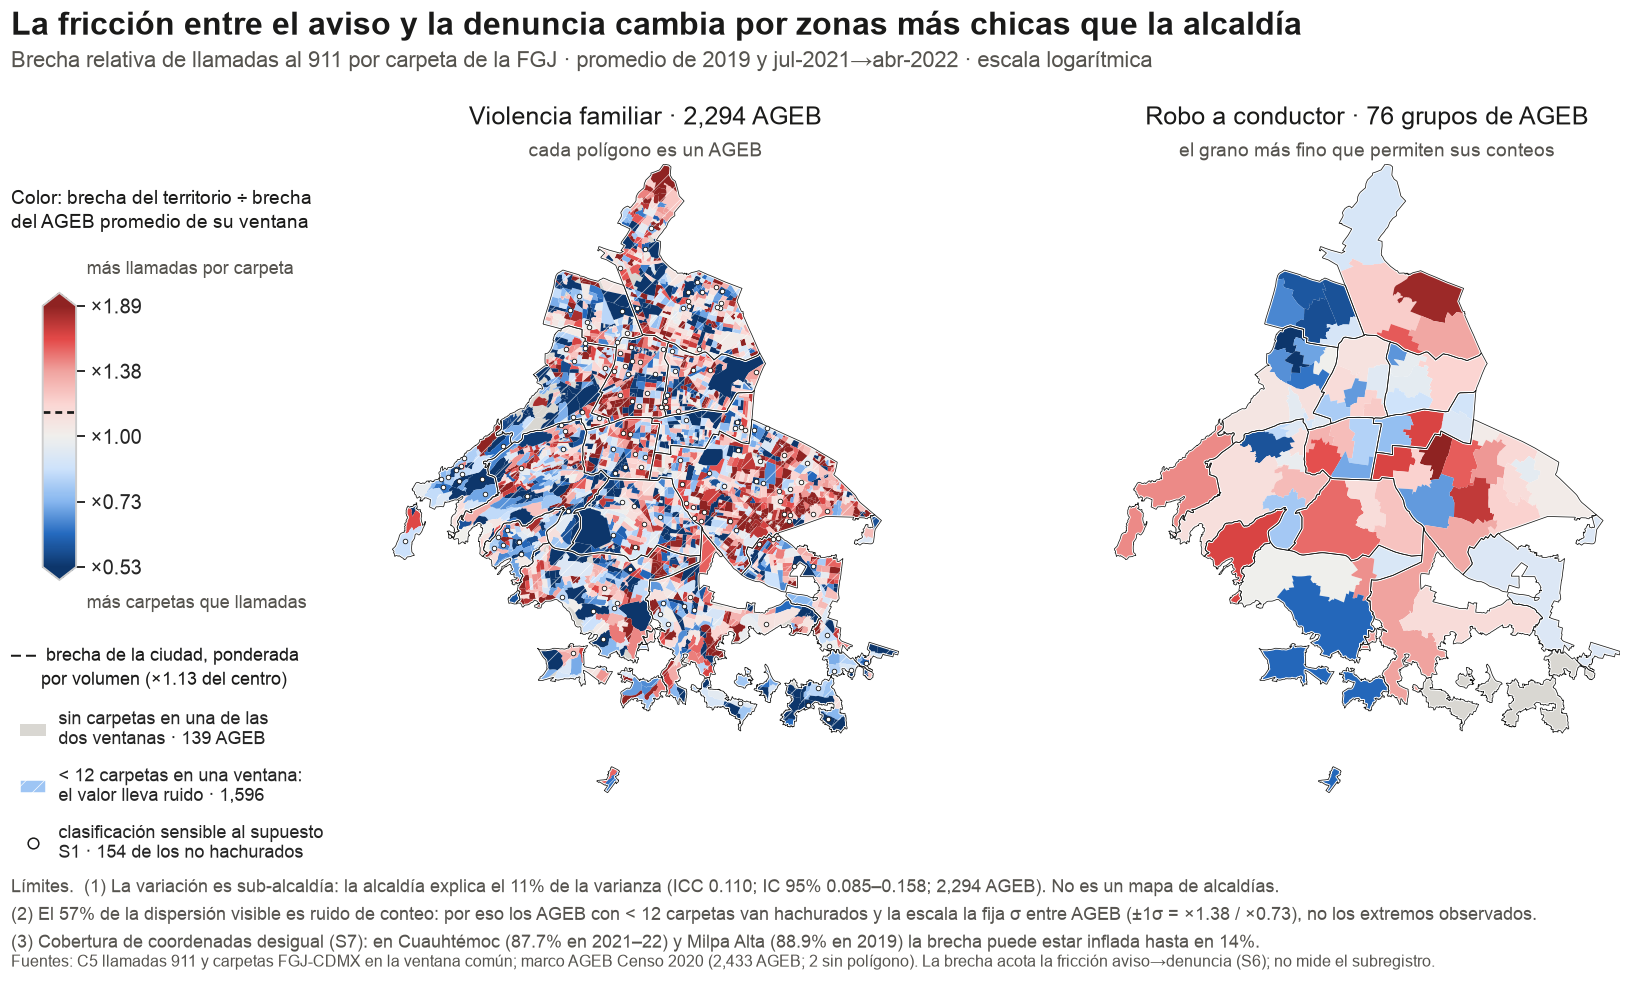

In [33]:
with mpl.rc_context(ESTILO):
    fig = plt.figure(figsize=(16, 9))
    ax1 = fig.add_axes([.175, .185, .395, .635]); ax2 = fig.add_axes([.585, .185, .395, .635])
    dibuja_mapa(ax1, GEO, MAPA_V.prom, bajo=BAJO & U, s1=SENS1 & U & ~BAJO)
    dibuja_mapa(ax2, GPOLY, MAPA_G)
    titulo_panel(ax1, f"Violencia familiar · {int(UNIV.sum()):,} AGEB", "cada polígono es un AGEB")
    titulo_panel(ax2, f"Robo a conductor · {int(GOK.sum())} grupos de AGEB", "el grano más fino que permiten sus conteos")
    fig.suptitle("La fricción entre el aviso y la denuncia cambia por zonas más chicas que la alcaldía",
                 fontsize=21, fontweight="bold", x=.012, ha="left", y=.975, color=TINTA)
    fig.text(.012, .918, "Brecha relativa de llamadas al 911 por carpeta de la FGJ · promedio de 2019 y jul-2021→abr-2022 · escala logarítmica",
             fontsize=14.5, color=TINTA2, ha="left")
    fig.text(.012, .80, "Color: brecha del territorio ÷ brecha\ndel AGEB promedio de su ventana",
             fontsize=12.5, color=TINTA, va="top", linespacing=1.45)
    barra_color(fig, [.030, .40, .019, .29])
    fig.text(.055, .705, "más llamadas por carpeta", fontsize=11.5, color=TINTA2, va="bottom")
    fig.text(.055, .385, "más carpetas que llamadas", fontsize=11.5, color=TINTA2, va="top")
    fig.text(.012, .335, f"– –  brecha de la ciudad, ponderada\n      por volumen (×{np.exp(REF_CIUDAD):.2f} del centro)",
             fontsize=11.5, color=TINTA, va="top", linespacing=1.45)
    leg = [Patch(fc=GRIS, ec="none", label=f"sin carpetas en una de las\ndos ventanas · {int((~UNIV).sum())} AGEB"),
           Patch(fc="#9ec5f4", ec="white", hatch="//", label=f"< {UMBRAL} carpetas en una ventana:\nel valor lleva ruido · {int((U & BAJO).sum()):,}"),
           Line2D([], [], marker="o", ls="", mfc="white", mec=TINTA, ms=7,
                  label=f"clasificación sensible al supuesto\nS1 · {int((U & SENS1 & ~BAJO).sum())} de los no hachurados")]
    fig.legend(handles=leg, loc="upper left", bbox_to_anchor=(.008, .285), fontsize=11.5, frameon=False,
               handlelength=1.5, labelspacing=1.0, handletextpad=.7)
    pie = [f"Límites.  (1) La variación es sub-alcaldía: la alcaldía explica el 11% de la varianza "
           f"(ICC {ICC['ambas']:.3f}; IC 95% {ICC_IC[0]:.3f}–{ICC_IC[1]:.3f}; {int(UNIV.sum()):,} AGEB). No es un mapa de alcaldías.",
           f"(2) El {RUIDO:.0%} de la dispersión visible es ruido de conteo: "
           f"por eso los AGEB con < {UMBRAL} carpetas van hachurados y la escala la fija σ entre AGEB (±1σ = ×{np.exp(SD_AGEB):.2f} / ×{np.exp(-SD_AGEB):.2f}), no los extremos observados.",
           "(3) Cobertura de coordenadas desigual (S7): en Cuauhtémoc (87.7% en 2021–22) y Milpa Alta (88.9% en 2019) la brecha puede estar inflada hasta en 14%."]
    for i, t in enumerate(pie):
        fig.text(.012, .098 - i * .028, t, fontsize=11.5, color=TINTA2, va="top")
    fig.text(.012, .006, "Fuentes: C5 llamadas 911 y carpetas FGJ-CDMX en la ventana común; marco AGEB Censo 2020 "
             "(2,433 AGEB; 2 sin polígono). La brecha acota la fricción aviso→denuncia (S6); no mide el subregistro.",
             fontsize=10.5, color=TINTA2, va="bottom")
    fig.savefig(FIG / "2.6_mapa_brecha_violencia_familiar_ageb.png", dpi=DPI)
    plt.show()

**Interpretación (figura principal):** en violencia familiar, AGEB contiguos de la misma alcaldía aparecen en rojo intenso y azul intenso uno junto al otro, y las fronteras de alcaldía (en blanco) no separan bloques de color; en robo a conductor, donde los conteos obligan a agregar a 76 grupos, el color se vuelve liso y los bloques se parecen a las alcaldías. **El mismo método aplicado a dos delitos produce un mapa fino y uno grueso, y la diferencia es el grano que permiten los conteos, no el fenómeno.**

### 10.3 Respaldo: las dos ventanas por separado

Responde a "¿y si el patrón es de una sola ventana?". Al pie va el ICC de alcaldía de cada ventana, que **no es parejo**: 0.057 en 2019 y 0.241 en 2021–22 (riesgo registrado el 8 de oct en `PLAN_15_OCT.md` §7). El orden de los AGEB se repite (ρ = 0.30, p = 0.001), el peso relativo de la alcaldía no.

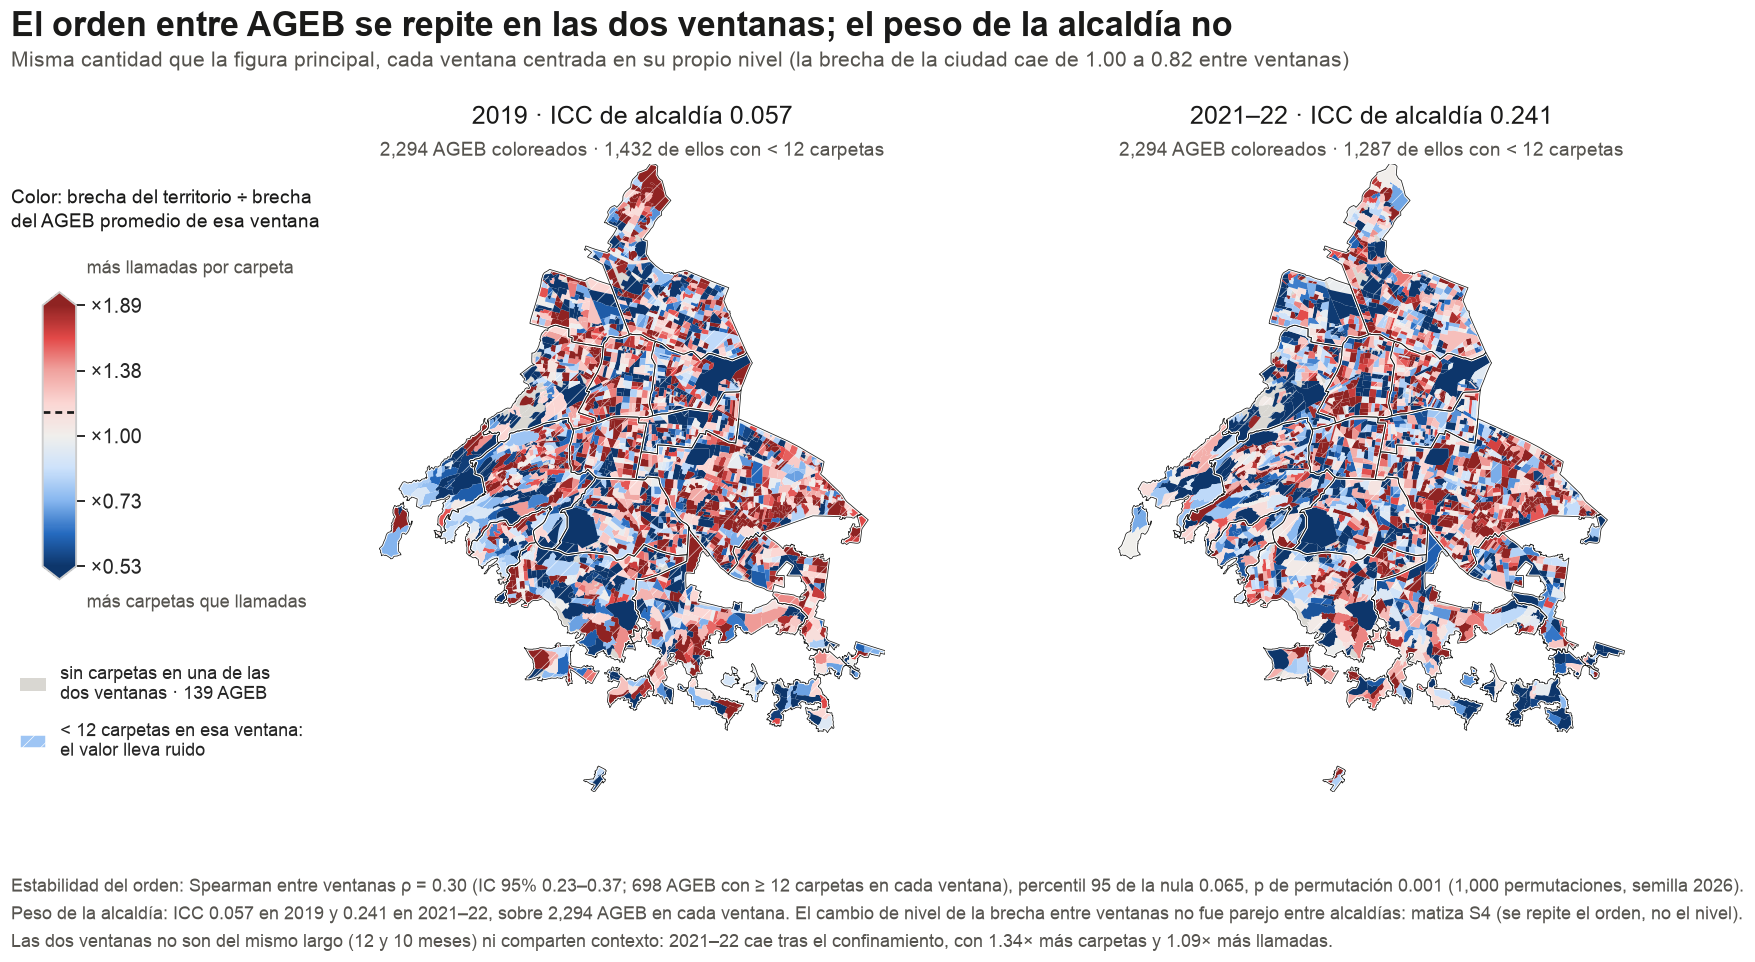

In [34]:
with mpl.rc_context(ESTILO):
    fig2 = plt.figure(figsize=(16, 9))
    axs = [fig2.add_axes([.165, .185, .40, .635]), fig2.add_axes([.585, .185, .40, .635])]
    for ax, w in zip(axs, VENT):
        bajo_w = (vf.xs(w).conteo_bajo & U).reindex(GEO.index)   # solo dentro del universo coloreado
        dibuja_mapa(ax, GEO, MAPA_V[w], bajo=bajo_w)
        n_col = int(MAPA_V[w].reindex(GEO.index).notna().sum())
        titulo_panel(ax, f"{w.replace('-', '–')} · ICC de alcaldía {ICC[w]:.3f}",
                     f"{n_col:,} AGEB coloreados · {int(bajo_w.fillna(False).sum()):,} de ellos con < {UMBRAL} carpetas")
    fig2.suptitle("El orden entre AGEB se repite en las dos ventanas; el peso de la alcaldía no",
                  fontsize=22, fontweight="bold", x=.012, ha="left", y=.975, color=TINTA)
    fig2.text(.012, .918, "Misma cantidad que la figura principal, cada ventana centrada en su propio nivel "
              "(la brecha de la ciudad cae de 1.00 a 0.82 entre ventanas)", fontsize=14, color=TINTA2)
    barra_color(fig2, [.030, .40, .019, .29])
    fig2.text(.012, .80, "Color: brecha del territorio ÷ brecha\ndel AGEB promedio de esa ventana",
              fontsize=12.5, color=TINTA, va="top", linespacing=1.45)
    fig2.text(.055, .705, "más llamadas por carpeta", fontsize=11.5, color=TINTA2, va="bottom")
    fig2.text(.055, .385, "más carpetas que llamadas", fontsize=11.5, color=TINTA2, va="top")
    fig2.legend(handles=[Patch(fc=GRIS, ec="none", label=f"sin carpetas en una de las\ndos ventanas · {int((~UNIV).sum())} AGEB"),
                         Patch(fc="#9ec5f4", ec="white", hatch="//", label=f"< {UMBRAL} carpetas en esa ventana:\nel valor lleva ruido")],
                loc="upper left", bbox_to_anchor=(.008, .33), fontsize=11.5, frameon=False, handlelength=1.5, labelspacing=1.0)
    pie2 = ["Estabilidad del orden: Spearman entre ventanas ρ = 0.30 (IC 95% 0.23–0.37; 698 AGEB con ≥ 12 carpetas en cada ventana), "
            "percentil 95 de la nula 0.065, p de permutación 0.001 (1,000 permutaciones, semilla 2026).",
            f"Peso de la alcaldía: ICC {ICC['2019']:.3f} en 2019 y {ICC['2021-22']:.3f} en 2021–22, sobre {int(UNIV.sum()):,} AGEB en cada ventana. "
            "El cambio de nivel de la brecha entre ventanas no fue parejo entre alcaldías: matiza S4 (se repite el orden, no el nivel).",
            "Las dos ventanas no son del mismo largo (12 y 10 meses) ni comparten contexto: 2021–22 cae tras el confinamiento, con 1.34× más carpetas y 1.09× más llamadas."]
    for i, t in enumerate(pie2):
        fig2.text(.012, .098 - i * .028, t, fontsize=11.5, color=TINTA2, va="top")
    fig2.savefig(FIG / "2.6_mapa_brecha_por_ventana.png", dpi=DPI)
    plt.show()

**Interpretación (dos ventanas):** el patrón fino está en las dos, así que no lo produce una ventana sola; lo que sí cambia entre ellas es cuánto de la variación se alinea con las alcaldías (ICC 0.057 → 0.241). *Supuesto:* mapeo las dos ventanas con la misma escala y el mismo centrado por ventana asumiendo que lo comparable entre ellas es la **posición relativa** del AGEB, no su nivel; si se quisieran comparar niveles, habría que usar una escala absoluta y entonces 2021–22 se vería entera más azul.

### 10.4 Respaldo: solo los AGEB donde la brecha se mide con precisión

Responde a "¿y si todo esto es ruido de conteo?". Son los 698 AGEB con ≥ 12 carpetas en **cada** ventana (CV de Poisson del denominador ≤ 28.9%), el mismo universo de la prueba de estabilidad de 8.5 y de la sensibilidad de H1 que da razón 5.01 (IC 2.10–7.32).

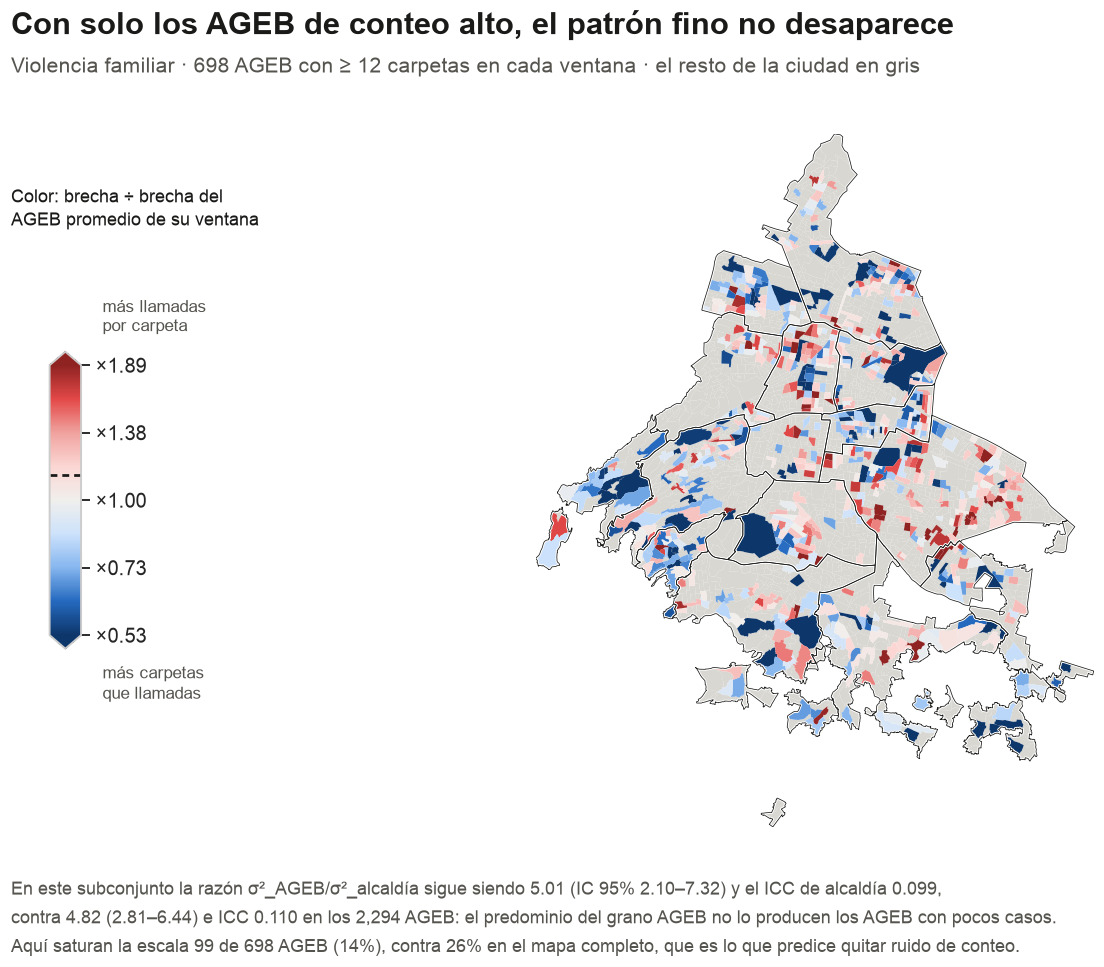

['2.5_diagnostico_ageb.png', '2.6_mapa_brecha_conteo_alto.png', '2.6_mapa_brecha_por_ventana.png', '2.6_mapa_brecha_violencia_familiar_ageb.png']


In [35]:
with mpl.rc_context(ESTILO):
    fig3 = plt.figure(figsize=(13, 9))
    ax = fig3.add_axes([.19, .15, .78, .70])
    dibuja_mapa(ax, GEO, MAPA_V.prom.where(ALTO))
    fig3.suptitle("Con solo los AGEB de conteo alto, el patrón fino no desaparece",
                  fontsize=20, fontweight="bold", x=.018, ha="left", y=.975, color=TINTA)
    fig3.text(.018, .912, f"Violencia familiar · {int((U & ALTO).sum())} AGEB con ≥ {UMBRAL} carpetas en cada ventana · "
              f"el resto de la ciudad en gris", fontsize=13.5, color=TINTA2)
    barra_color(fig3, [.045, .33, .022, .30])
    fig3.text(.018, .80, "Color: brecha ÷ brecha del\nAGEB promedio de su ventana", fontsize=12, color=TINTA, va="top", linespacing=1.45)
    fig3.text(.082, .645, "más llamadas\npor carpeta", fontsize=11, color=TINTA2, va="bottom", linespacing=1.3)
    fig3.text(.082, .315, "más carpetas\nque llamadas", fontsize=11, color=TINTA2, va="top", linespacing=1.3)
    pie3 = ["En este subconjunto la razón σ²_AGEB/σ²_alcaldía sigue siendo 5.01 (IC 95% 2.10–7.32) y el ICC de alcaldía 0.099,",
            f"contra 4.82 (2.81–6.44) e ICC {ICC['ambas']:.3f} en los {int(UNIV.sum()):,} AGEB: el predominio del grano AGEB no lo producen los AGEB con pocos casos.",
            f"Aquí saturan la escala {int((MAPA_V.prom[U & ALTO].abs() > LIM).sum())} de {int((U & ALTO).sum())} AGEB "
            f"({(MAPA_V.prom[U & ALTO].abs() > LIM).mean():.0%}), contra {(MAPA_V.prom[U].abs() > LIM).mean():.0%} en el mapa completo, "
            "que es lo que predice quitar ruido de conteo."]
    for i, t in enumerate(pie3):
        fig3.text(.018, .095 - i * .029, t, fontsize=11.5, color=TINTA2, va="top")
    fig3.savefig(FIG / "2.6_mapa_brecha_conteo_alto.png", dpi=DPI)
    plt.show()
print(sorted(p.name for p in FIG.glob("*.png")))

### 10.5 Figura del deck: el mapa a pantalla completa y el acercamiento de 6 km

La figura principal (10.2) pone dos paneles en 16×9, así que cada mapa queda a menos de media slide y los AGEB se vuelven indistinguibles en proyector. Para la presentación se produce **la misma cantidad, con la misma escala y el mismo universo**, en dos piezas separadas:

- **`2.6_mapa_hero_violencia_familiar.png`** — un solo panel vertical, con el ancho exacto de la ciudad y la leyenda en una franja propia, así que ningún AGEB queda tapado. Sin hachurado ni círculos: las marcas de conteo bajo y de S1 viven en la figura de 10.2, que pasa a respaldo.
- **`2.6_zoom_mosaico_1km.png`** — una ventana de 6 km del mismo mapa, donde un AGEB mide ~80 px en vez de ~12. Es la figura que hace visible la escala que midió el 2.5 (mosaico de 1–2 km) y que las fronteras de alcaldía no separan bloques de color.

*Supuesto de la ventana:* la elijo con una **regla fija que no mira el color**: de todas las ventanas de 6 km sobre una malla de 500 m, la que más AGEB de conteo alto (≥ 12 carpetas en cada ventana) contiene, entre las que tocan al menos dos alcaldías; empates por la coordenada menor. Así el acercamiento no se escoge por ser el más vistoso, sino por ser donde la brecha se mide con más precisión y donde se puede ver una frontera. Si la regla cayera en una zona atípica, el mapa completo de al lado lo delataría.

ventana de 6 km en (2801446, 820915) | AGEB dentro 141, de conteo alto 70 | alcaldías ['IZTACALCO', 'IZTAPALAPA', 'VENUSTIANO CARRANZA']


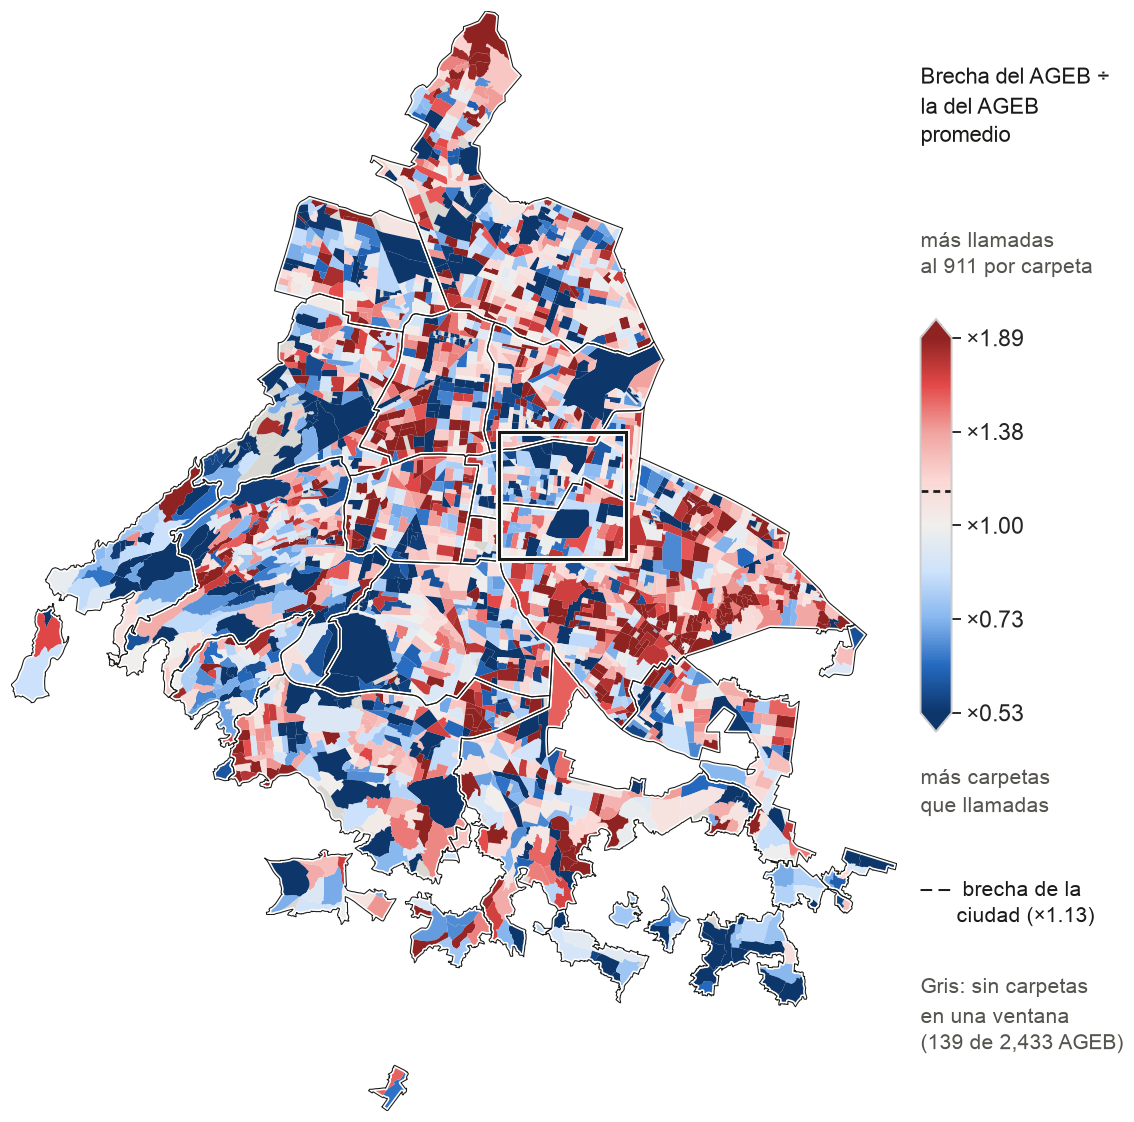

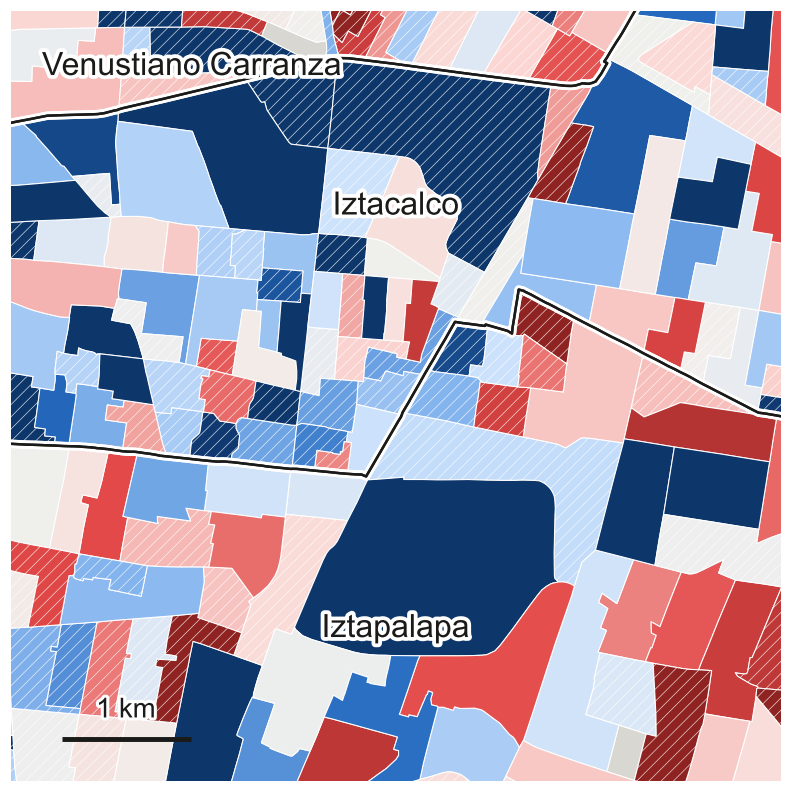

AGEB dibujados en el acercamiento: 171 | hachurados (conteo bajo): 88 | sin color (sin carpetas en una ventana): 3
['2.5_diagnostico_ageb.png', '2.6_mapa_brecha_conteo_alto.png', '2.6_mapa_brecha_por_ventana.png', '2.6_mapa_brecha_violencia_familiar_ageb.png', '2.6_mapa_hero_violencia_familiar.png', '2.6_zoom_mosaico_1km.png']


In [36]:
import matplotlib.patheffects as pe
from shapely.geometry import box as sbox

# --- ventana del acercamiento: regla fija, sin mirar el color (ver supuesto de 10.5) ---
LADO, PASO = 6000.0, 500.0
CENT = GEO.geometry.representative_point()
cxv, cyv, alcv = CENT.x.to_numpy(), CENT.y.to_numpy(), GEO.alcaldia.to_numpy()
hi = (U & ALTO).reindex(GEO.index).fillna(False).to_numpy()
mejor, caja = (-1, -1), None
for x0 in np.arange(XL[0], XL[1] - LADO + 1, PASO):
    for y0 in np.arange(YL[0], YL[1] - LADO + 1, PASO):
        m = (cxv >= x0) & (cxv < x0 + LADO) & (cyv >= y0) & (cyv < y0 + LADO)
        if m.sum() == 0 or len(set(alcv[m])) < 2:
            continue
        k = (int((m & hi).sum()), int(m.sum()))
        if k > mejor:
            mejor, caja = k, (x0, y0)
X0, Y0 = caja
EN_CAJA = (cxv >= X0) & (cxv < X0 + LADO) & (cyv >= Y0) & (cyv < Y0 + LADO)
print(f"ventana de {LADO/1000:.0f} km en ({X0:.0f}, {Y0:.0f}) | AGEB dentro {mejor[1]}, de conteo alto {mejor[0]} "
      f"| alcaldías {sorted(set(alcv[EN_CAJA]))}")

AR = (XL[1] - XL[0]) / (YL[1] - YL[0])          # la ciudad es más alta que ancha: el panel va vertical
V_HERO = MAPA_V.prom
H_IN, FRANJA = 10.0, 2.8                        # franja derecha para la leyenda: no tapa ningún AGEB
W_MAP = H_IN * AR; W_IN = W_MAP + FRANJA; FM = W_MAP / W_IN

with mpl.rc_context(ESTILO):
    figh = plt.figure(figsize=(W_IN, H_IN))
    axh = figh.add_axes([0, 0, FM, 1]); axh.set_axis_off()
    v = V_HERO.reindex(GEO.index)
    GEO[v.isna()].plot(ax=axh, color=GRIS, ec="none")
    GEO[v.notna()].assign(_v=v[v.notna()].clip(-LIM, LIM)).plot(ax=axh, column="_v", cmap=CMAP, norm=NORM, ec="none")
    ALC_POLY.boundary.plot(ax=axh, ec="white", lw=2.8, zorder=4)
    ALC_POLY.boundary.plot(ax=axh, ec=TINTA, lw=.7, zorder=4)
    for lw, c in ((4.5, "white"), (2.0, TINTA)):
        axh.add_patch(mpl.patches.Rectangle((X0, Y0), LADO, LADO, fc="none", ec=c, lw=lw, zorder=6))
    axh.set_xlim(*XL); axh.set_ylim(*YL)
    xt = FM + .020
    figh.text(xt, .955, "Brecha del AGEB ÷\nla del AGEB\npromedio", fontsize=14.5, color=TINTA, va="top", linespacing=1.45)
    figh.text(xt, .805, "más llamadas\nal 911 por carpeta", fontsize=13.5, color=TINTA2, va="top", linespacing=1.45)
    barra_color(figh, [xt, .345, .026, .375]).ax.tick_params(labelsize=15)
    figh.text(xt, .315, "más carpetas\nque llamadas", fontsize=13.5, color=TINTA2, va="top", linespacing=1.45)
    figh.text(xt, .215, f"– –  brecha de la\n      ciudad (×{np.exp(REF_CIUDAD):.2f})", fontsize=13.5, color=TINTA,
              va="top", linespacing=1.45)
    figh.text(xt, .125, f"Gris: sin carpetas\nen una ventana\n({int((~UNIV).sum())} de {len(ageb):,} AGEB)",
              fontsize=13.5, color=TINTA2, va="top", linespacing=1.45)
    figh.savefig(FIG / "2.6_mapa_hero_violencia_familiar.png", dpi=DPI)
    plt.show()

SEL = GEO.cx[X0:X0 + LADO, Y0:Y0 + LADO]
with mpl.rc_context(ESTILO):
    LADO_IN, FS_ALC = 7.0, 21
    figz = plt.figure(figsize=(LADO_IN, LADO_IN))
    axz = figz.add_axes([0, 0, 1, 1]); axz.set_axis_off()
    v = V_HERO.reindex(SEL.index)
    SEL[v.isna()].plot(ax=axz, color=GRIS, ec="white", lw=.7)
    SEL[v.notna()].assign(_v=v[v.notna()].clip(-LIM, LIM)).plot(ax=axz, column="_v", cmap=CMAP, norm=NORM, ec="white", lw=.7)
    ix = SEL.index.intersection(BAJO[BAJO.fillna(False)].index.intersection(U[U].index))
    SEL.loc[ix].plot(ax=axz, fc="none", ec="white", lw=0, hatch="///", alpha=.8, zorder=3)
    ALC_POLY.boundary.plot(ax=axz, ec="white", lw=5.5, zorder=4)
    ALC_POLY.boundary.plot(ax=axz, ec=TINTA, lw=1.6, zorder=4)
    for a, g in ALC_POLY.geometry.items():
        c = g.intersection(sbox(X0, Y0, X0 + LADO, Y0 + LADO))
        if c.is_empty or c.area < 2.5e6:          # no etiquetar una esquina de 2.5 km2
            continue
        q = c.representative_point()
        hw = .5 * len(a) * .52 * (FS_ALC / 72) * (LADO / LADO_IN) + 180
        axz.text(min(max(q.x, X0 + hw), X0 + LADO - hw), min(max(q.y, Y0 + .04 * LADO), Y0 + .96 * LADO),
                 a.title(), fontsize=FS_ALC, color=TINTA, ha="center", va="center", zorder=7,
                 path_effects=[pe.withStroke(linewidth=5, foreground="white")])
    axz.plot([X0 + 400, X0 + 1400], [Y0 + 330, Y0 + 330], color=TINTA, lw=3.2, zorder=7, solid_capstyle="butt")
    axz.text(X0 + 900, Y0 + 450, "1 km", fontsize=18, color=TINTA, ha="center", va="bottom", zorder=7,
             path_effects=[pe.withStroke(linewidth=4, foreground="white")])
    axz.set_xlim(X0, X0 + LADO); axz.set_ylim(Y0, Y0 + LADO)
    figz.savefig(FIG / "2.6_zoom_mosaico_1km.png", dpi=DPI)
    plt.show()
print(f"AGEB dibujados en el acercamiento: {len(SEL)} | hachurados (conteo bajo): {len(ix)} | "
      f"sin color (sin carpetas en una ventana): {int(v.isna().sum())}")
print(sorted(p.name for p in FIG.glob("*.png")))

**Interpretación (acercamiento):** dentro de una ventana de 6 km conviven AGEB en azul fuerte y en rojo fuerte pegados, y la frontera de alcaldía la cruza por en medio sin separar bloques de color. Es la misma conclusión que el 2.3 midió (la alcaldía explica el 11%) y que el 2.5 fechó en 1–2 km, pero vista en vez de citada.

**Interpretación (conteo alto):** con un cuarto de los AGEB pero más de la mitad de las carpetas, el mosaico sigue cruzando las fronteras de alcaldía y la proporción de AGEB que saturan la escala cae a la mitad, que es justo lo que predice quitar ruido de conteo. *Supuesto:* leo este mapa como el mismo fenómeno visto con menos ruido, asumiendo que los AGEB con ≥ 12 carpetas no son un subconjunto con otra fricción; si lo fueran (por ejemplo, si solo los AGEB densos tuvieran brecha alta), este mapa y el completo no se parecerían, y se parecen.

### 10.6 Qué deja el 2.6

- Cinco PNG en `resultados/figuras/`, con nombres estables: `2.6_mapa_hero_violencia_familiar.png` y `2.6_zoom_mosaico_1km.png` (las dos del deck, 10.5), y `2.6_mapa_brecha_violencia_familiar_ageb.png`, `2.6_mapa_brecha_por_ventana.png` y `2.6_mapa_brecha_conteo_alto.png` (respaldo). Se regeneran corriendo esta sección; no dependen de ningún CSV intermedio nuevo.
- **La figura dice una frase:** la fricción entre el aviso y la denuncia cambia por zonas más chicas que la alcaldía y no respeta sus fronteras. El mapa de robo a conductor al lado muestra que, cuando los conteos obligan a agregar, esa misma señal se vuelve un mapa de alcaldías. *(Frase actualizada el 13 de oct con la lectura del 2.5: el correlograma ubica el mosaico en 1–2 km, así que no es "de un AGEB al de al lado" ni un gradiente de alcaldía.)*
- **Lo que no dice:** cuánto subregistro hay. Ordena territorios (S6). El nivel de ciudad lo acota la ENDIREH en el 2.4.
- **Queda para el 2.5** la pregunta que el mapa plantea y no responde: si el mosaico es ruido espacial o un gradiente suave sub-alcaldía. El I de Moran lo separa, y a ojo el mapa tiene las dos cosas.

## 11. Experimento 2.5 — Diagnóstico de AGEB: conteos bajos, denominador y autocorrelación espacial (`resultados/15_`)

Esta sección **no recalcula la brecha ni los componentes de varianza**: lee `vf` y `rc` de la sección 8 (= `resultados/11_`), los componentes `h1` de la sección 9 (= `resultados/13_`) y la cantidad `MAPA_V.prom` de la sección 10, que es exactamente lo que pinta el mapa de la slide 7.

**La pregunta que el 2.6 dejó abierta.** H1 probó que la brecha varía más entre AGEB de la misma alcaldía que entre alcaldías (razón 4.82; ICC de alcaldía 0.110). Lo que H1 **no** separa es si esa variación sub-alcaldía es un **mosaico fino** de AGEB vecinos distintos o un **gradiente suave** que recorre varios AGEB: a ojo el mapa tiene las dos cosas (riesgo registrado el 9 de oct). Esa diferencia no cambia el veredicto de H1 — cambia la frase que se dice en voz alta en la slide 7.

**Regla de lectura fijada el 11 de oct en `PLAN_15_OCT.md` §3.4, antes de calcular cualquier estadístico espacial.** Se repite aquí lo que decide:
- Cantidad: `m` = media de los dos log de la brecha centrados por ventana, en los **2,294 AGEB con ≥ 1 carpeta en cada ventana**, peso igual. Vecindad: polígonos que se tocan (tolerancia 1 m, EPSG:6372), **sin** restringir a la alcaldía, estandarizada por filas.
- **El I observado está atenuado:** el ruido de conteo es espacialmente independiente, así que entra al denominador del I y no al numerador. Se reporta `I_obs` (cota inferior) y `I_corr = I_obs × Var(z) / (Var(z) − ruido binomial)`, con el ruido binomial conocido del 2.3 (v̄/2 para las dos ventanas, v̄ para una sola).
- Dos nulas de 1,000 réplicas con semilla 2026: **permutación** de `m` entre AGEB (cualquier estructura espacial) y la **nula de homogeneidad del 2.3(a)** (llamadas ~ Binomial(n observado, p̂ de su alcaldía y ventana)), que conserva el nivel de alcaldía *y* el ruido de conteo: superarla significa autocorrelación **más allá** de las fronteras de alcaldía.
- **Decide el `I_corr` de los residuos dentro de alcaldía** (`m` menos la media de su alcaldía), porque la pregunta es sobre la variación sub-alcaldía: `< 0.10` mosaico fino · `0.10–0.25` coexisten las dos estructuras · `≥ 0.25` hay gradiente suave y la frase de la slide 7 se matiza.

*Supuesto (por qué no hay IC bootstrap del I):* reporto la incertidumbre del I con sus dos nulas y con el z analítico, no con un bootstrap, asumiendo que remuestrear AGEB destruiría justo la vecindad que el estadístico mide; si se quisiera un IC, habría que remuestrear bloques espaciales contiguos, que con 2,294 unidades y una sola realización del proceso no está identificado.

### 11.1 Vecindad, estimador del I de Moran y corrección por atenuación

In [37]:
import scipy.sparse as ssp

AG_U = MAPA_V.index[U.to_numpy()]                      # universo del 2.3 y del mapa: >= 1 carpeta en cada ventana
assert ageb.set_index("ageb").geometry.reindex(AG_U).notna().all()   # los 2 AGEB sin polígono no entran (no tienen eventos)
POS = {a: i for i, a in enumerate(AG_U)}
NU = len(AG_U)

def contiguidad(ids):
    # polígonos que se tocan, con tolerancia de 1 m en EPSG:6372 (misma vecindad que la agregación de H3, sin restringir a la alcaldía)
    b = gpd.GeoDataFrame(geometry=GEO.loc[ids].buffer(1.0)).reset_index()
    pr = gpd.sjoin(b, b, predicate="intersects")
    pr = pr[pr.ageb_left != pr.ageb_right]
    pos = {a: i for i, a in enumerate(ids)}
    i = pr.ageb_left.map(pos).to_numpy(); j = pr.ageb_right.map(pos).to_numpy()
    C = ssp.csr_matrix((np.ones(len(i)), (i, j)), shape=(len(ids), len(ids)))
    C.data[:] = 1.0
    return C

def fila_estandar(C):
    d = np.asarray(C.sum(1)).ravel()
    return ssp.diags(np.where(d > 0, 1.0 / np.maximum(d, 1.0), 0.0)) @ C, d

def moran(z, W):
    z = np.asarray(z, float) - np.asarray(z, float).mean()
    return float(z @ (W @ z) / (z @ z))

def moran_z(I, W, n):
    # z analítico bajo normalidad (descriptivo: con n grande sirve para el signo y el orden de magnitud, no para un p fino)
    S0 = float(W.sum()); A = W + W.T
    S1 = 0.5 * float(A.multiply(A).sum())
    rs = np.asarray(W.sum(1)).ravel(); cs = np.asarray(W.sum(0)).ravel()
    S2 = float(((rs + cs) ** 2).sum())
    EI = -1.0 / (n - 1)
    VI = (n * n * S1 - n * S2 + 3 * S0 * S0) / ((n * n - 1) * S0 * S0) - EI ** 2
    return (I - EI) / np.sqrt(VI), EI, np.sqrt(VI)

def resid_alc(x, g):
    s = np.bincount(g, weights=x, minlength=K_ALC); k = np.bincount(g, minlength=K_ALC)
    mb = np.divide(s, k, out=np.zeros(K_ALC), where=k > 0)
    return x - mb[g]

C_U = contiguidad(AG_U)
W_U, GRADO = fila_estandar(C_U)
g_u = np.array([A_COD[a] for a in ALC_DE_AGEB.reindex(AG_U)])

# la cantidad y su ruido conocido, los mismos del 2.3 y del 2.6
MU = {"ambas": MAPA_V.prom.reindex(AG_U).to_numpy(float)}
MU.update({w: MAPA_V[w].reindex(AG_U).to_numpy(float) for w in VENT})
VU = (1.0 / (LLv + 0.5) + 1.0 / (CARv + 0.5))[U.to_numpy()]
RUIDO_V = {"ambas": float(VU.mean()) / 2, **{w: float(VU[:, i].mean()) for i, w in enumerate(VENT)}}
assert np.isclose(RUIDO_V["ambas"], VBAR / 2)
NT = (LLv + CARv)[U.to_numpy()].round().astype(np.int64)
_num = np.column_stack([np.bincount(g_u, weights=LLv[U.to_numpy()][:, c], minlength=K_ALC) for c in range(2)])
_tot = np.column_stack([np.bincount(g_u, weights=NT[:, c].astype(float), minlength=K_ALC) for c in range(2)])
P_HOM = np.divide(_num, _tot, out=np.full_like(_num, 0.5), where=_tot > 0)[g_u]

def sim_homogeneidad(rng):
    # misma nula que 9.3: cada AGEB con la p de su alcaldía y ventana, n observado fijo; centrado por ventana igual que el observado
    ll = rng.binomial(NT, P_HOM).astype(float)
    car = (NT - ll).astype(float)
    y = np.log((ll + 0.5) / (car + 0.5))
    return y - y.mean(axis=0, keepdims=True)

print(f"AGEB en el universo: {NU:,} | vecinos por AGEB: mediana {np.median(GRADO):.0f}, rango {GRADO.min():.0f}–{GRADO.max():.0f} "
      f"| AGEB sin vecinos en el universo: {int((GRADO == 0).sum())} | pares de vecindad: {int(C_U.nnz / 2):,}")
print("Ruido binomial conocido (varianza en la escala del log de la brecha):", {k: round(v, 4) for k, v in RUIDO_V.items()})
print(f"Var(m) = {np.var(MU['ambas']):.3f}; factor de atenuación = {np.var(MU['ambas']) / (np.var(MU['ambas']) - RUIDO_V['ambas']):.2f}x")

AGEB en el universo: 2,294 | vecinos por AGEB: mediana 6, rango 0–26 | AGEB sin vecinos en el universo: 1 | pares de vecindad: 6,697
Ruido binomial conocido (varianza en la escala del log de la brecha): {'ambas': 0.2055, '2019': 0.426, '2021-22': 0.396}
Var(m) = 0.361; factor de atenuación = 2.32x


**Lectura (vecindad y atenuación):** la contigüidad da una malla sana —6 vecinos por AGEB en la mediana, 6,697 pares— y solo **1 AGEB del universo queda aislado** (no toca ningún otro AGEB con carpetas en las dos ventanas): aporta su varianza al denominador del I y nada al numerador, así que lo sesga hacia cero en 1 de 2,294 unidades, que es despreciable y se reporta en vez de descartarlo. El factor de atenuación es **2.32×** sobre `m` (Var = 0.361, ruido binomial conocido 0.206) y **2.53×** sobre los residuos dentro de alcaldía: **más de la mitad de la varianza visible del mapa es ruido de conteo**, y por eso el I observado no se puede leer como si fuera el del proceso subyacente. El ruido de una sola ventana es el doble (0.426 y 0.396), así que las filas por ventana llevan correcciones mayores y menos confiables que la fila de las dos ventanas juntas, que es la que decide.

### 11.2 I de Moran de la brecha: total y dentro de alcaldía, con sus dos nulas

In [38]:
def fila_moran(nombre, mask, W, clave, residual, B=B_REP, semilla=SEMILLA):
    g = g_u[mask]
    m = MU[clave][mask]
    z = resid_alc(m, g) if residual else m - m.mean()
    I = moran(z, W)
    # el ruido binomial se calcula sobre las MISMAS unidades: el subconjunto de conteo alto tiene un tercio del ruido del universo
    vm = VU[mask]
    var_z = float(np.var(z))
    ruido = float(vm.mean()) / 2 if clave == "ambas" else float(vm[:, VENT.index(clave)].mean())
    I_corr = I * var_z / (var_z - ruido) if var_z > ruido else np.nan
    rng = np.random.default_rng(semilla)
    perm = np.array([moran(rng.permutation(z), W) for _ in range(B)])
    rng = np.random.default_rng(semilla)
    hom = np.empty(B)
    for b in range(B):
        zz = sim_homogeneidad(rng)
        mm = (zz.mean(axis=1) if clave == "ambas" else zz[:, VENT.index(clave)])[mask]
        hom[b] = moran(resid_alc(mm, g) if residual else mm - mm.mean(), W)
    za, EI, sd = moran_z(I, W, int(mask.sum()))
    return {"subconjunto": nombre, "cantidad": "residuos dentro de alcaldía" if residual else "m (incluye nivel de alcaldía)",
            "ventana": clave, "n_ageb": int(mask.sum()), "I_obs": I, "I_corr": I_corr,
            "var_z": var_z, "ruido_binomial": ruido, "atenuacion": var_z / (var_z - ruido) if var_z > ruido else np.nan,
            "z_analitico": za, "E_I": EI,
            "p95_nula_perm": np.percentile(perm, 95), "p_perm": (1 + (perm >= I).sum()) / (B + 1),
            "p95_nula_homog": np.percentile(hom, 95), "p_homog": (1 + (hom >= I).sum()) / (B + 1)}

TODO_U = np.ones(NU, bool)
AG_A = MAPA_V.index[(U & ALTO).to_numpy()]
mask_alto = np.isin(AG_U, AG_A)
W_A, GRADO_A = fila_estandar(contiguidad(list(AG_A)))
print(f"Subconjunto de conteo alto: {len(AG_A)} AGEB | con al menos un vecino dentro del subconjunto: {int((GRADO_A > 0).sum())}")

mor = pd.DataFrame([fila_moran("universo (2,294 AGEB)", TODO_U, W_U, w, r) for w in ["ambas"] + VENT for r in (True, False)]
                   + [fila_moran(f"conteo alto (>= {UMBRAL} carpetas)", mask_alto, W_A, "ambas", r) for r in (True, False)])
UMB_MOS, UMB_GRAD = 0.10, 0.25   # umbrales fijados en PLAN §3.4 antes de calcular
mor["veredicto"] = pd.cut(mor.I_corr, [-np.inf, UMB_MOS, UMB_GRAD, np.inf],
                          labels=["mosaico fino", "coexisten las dos estructuras", "gradiente suave"]).astype(str)
mor.loc[mor.cantidad != "residuos dentro de alcaldía", "veredicto"] = "(no decide: incluye el nivel de alcaldía)"
display(mor.set_index(["subconjunto", "cantidad", "ventana"]).round(4))

# contexto: ¿dónde está la autocorrelación que sí hay? indicadores sin atenuación conocida
car_u = CARv[U.to_numpy()].sum(axis=1)
extra = []
for nom, x in [("indicador de conteo bajo (< 12 carpetas en alguna ventana)", BAJO.reindex(AG_U).astype(float).to_numpy()),
               ("log(carpetas de las dos ventanas)", np.log(car_u)),
               ("indicador de sensibilidad a S1", SENS1.reindex(AG_U).astype(float).to_numpy())]:
    z = x - x.mean(); I = moran(z, W_U)
    rng = np.random.default_rng(SEMILLA)
    perm = np.array([moran(rng.permutation(z), W_U) for _ in range(B_REP)])
    extra.append({"variable": nom, "I_obs": I, "p95_nula_perm": np.percentile(perm, 95),
                  "p_perm": (1 + (perm >= I).sum()) / (B_REP + 1), "z_analitico": moran_z(I, W_U, NU)[0]})
extra = pd.DataFrame(extra)
display(extra.round(4))

Subconjunto de conteo alto: 698 AGEB | con al menos un vecino dentro del subconjunto: 664


n_ageb  I_obs  I_corr  var_z  ruido_binomial  atenuacion  z_analitico    E_I  p95_nula_perm  p_perm  p95_nula_homog  p_homog  \
subconjunto                  cantidad                      ventana                                                                                                                                 
universo (2,294 AGEB)        residuos dentro de alcaldía   ambas      2294  0.097   0.245  0.340           0.205       2.533        7.633 -0.000          0.021   0.001           0.018    0.001   
                             m (incluye nivel de alcaldía) ambas      2294  0.146   0.340  0.361           0.205       2.322       11.519 -0.000          0.021   0.001           0.128    0.005   
                             residuos dentro de alcaldía   2019       2294  0.092   0.268  0.649           0.426       2.908        7.270 -0.000          0.022   0.001           0.018    0.001   
                             m (incluye nivel de alcaldía) 2019       2294  0.112   0.312  0.666           0.426       2.775        8.851 -0.000          0.021   0.001           0.067    0.001   
                             residuos dentro de alcaldía   2021-22    2294  0.050   0.239  0.502           0.396       4.748        3.989 -0.000          0.022   0.001           0.018    0.001   
                             m (incluye nivel de alcaldía) 2021-22    2294  0.108   0.412  0.537           0.396       3.816        8.505 -0.000          0.022   0.001           0.104    0.034   
conteo alto (>= 12 carpetas) residuos dentro de alcaldía   ambas       698  0.119   0.180  0.195           0.066       1.515        3.636 -0.001          0.047   0.001           0.034    0.001   
                             m (incluye nivel de alcaldía) ambas       698  0.190   0.274  0.216           0.066       1.441        5.780 -0.001          0.047   0.001           0.294    0.913   

                                                                                                    veredicto  
subconjunto                  cantidad                      ventana                                             
universo (2,294 AGEB)        residuos dentro de alcaldía   ambas                coexisten las dos estructuras  
                             m (incluye nivel de alcaldía) ambas    (no decide: incluye el nivel de alcaldía)  
                             residuos dentro de alcaldía   2019                               gradiente suave  
                             m (incluye nivel de alcaldía) 2019     (no decide: incluye el nivel de alcaldía)  
                             residuos dentro de alcaldía   2021-22              coexisten las dos estructuras  
                             m (incluye nivel de alcaldía) 2021-22  (no decide: incluye el nivel de alcaldía)  
conteo alto (>= 12 carpetas) residuos dentro de alcaldía   ambas                coexisten las dos estructuras  
                             m (incluye nivel de alcaldía) ambas    (no decide: incluye el nivel de alcaldía)

,variable,I_obs,p95_nula_perm,p_perm,z_analitico
0,indicador de conteo bajo (< 12 carpetas en alguna ventana),0.242,0.021,0.001,18.986
1,log(carpetas de las dos ventanas),0.364,0.021,0.001,28.610
2,indicador de sensibilidad a S1,0.073,0.021,0.001,5.752


**Lectura (el veredicto del 2.5).** Con la regla del §3.4: **coexisten las dos estructuras, y el caso queda pegado al umbral del gradiente.**

- **Hay autocorrelación y no la explican las alcaldías.** En los residuos dentro de alcaldía de las dos ventanas, **I = 0.097**, contra un percentil 95 de **0.021** en la nula de permutación y de **0.018** en la nula de homogeneidad (p = 0.001 en las dos, el mínimo posible con 1,000 réplicas; z analítico 7.6). La nula de homogeneidad es la que importa: conserva el nivel de cada alcaldía *y* el ruido de conteo, así que superarla significa que **AGEB vecinos de la misma alcaldía se parecen entre sí más de lo que explica el azar**. El ruido de conteo, por construcción, tendría I = 0.
- **Corregido por atenuación, I = 0.245**, es decir **"coexisten las dos estructuras"** por 0.005 de margen. Un estimador puntual no distingue 0.245 de 0.25, así que el veredicto honesto es el de la banda intermedia **con la advertencia de que está en su borde superior**: por ventana da 0.268 (2019, que cruzaría a "gradiente suave") y 0.239 (2021–22).
- **La conclusión no depende de la corrección.** En los 698 AGEB de conteo alto el ruido es un tercio (0.066 contra 0.206) y la corrección apenas 1.51×: ahí el I observado es **más alto** (0.119, p = 0.001) y el corregido da **0.180**, en la misma banda. Que la corrección grande dé 0.245 y la chica 0.180 acota cuánto puede estar inflando el supuesto de independencia del ruido.
- **Por qué decide el residual y no `m`.** Sin quitar la media de la alcaldía, I = 0.146 y corregido 0.340, pero esa cifra mezcla dos cosas: contra la nula de homogeneidad su p sube a 0.005 y en 2021–22 a 0.034, justo porque parte de ese I lo produce la heterogeneidad **entre** alcaldías, que es lo que esa nula conserva. El §3.4 ya había fijado que decide el residual.
- **Contexto que importa para leer el mapa:** el indicador de conteo bajo está muy agrupado (**I = 0.242**, p = 0.001) y el volumen de carpetas más todavía (log(carpetas), **I = 0.364**). El hachurado del mapa de la slide 7 **no es ruido disperso: es una región**. La sensibilidad a S1 casi no se agrupa (I = 0.073), lo cual es tranquilizador para S1: la contaminación con robo no está concentrada en una zona.

*Supuesto:* leo `I_corr` como el I del proceso subyacente asumiendo que el ruido binomial es espacialmente independiente dado n; si los duplicados del 911 se concentraran entre vecinos (un mismo hecho llamado varias veces desde la misma cuadra), la corrección sobreestimaría y la cifra honesta sería el I observado (0.097), que seguiría siendo distinto de cero pero caería en la banda de "mosaico fino". Por eso se reportan las dos.

**Qué cambia para el 15 de oct:** la frase de la slide 7 pasa de *"cambia de un AGEB al de al lado"* a *"cambia por zonas más chicas que la alcaldía, que no respetan sus fronteras"*. **H1 no se toca:** sigue siendo cierto que la varianza entre AGEB de la misma alcaldía es 4.8× la de entre alcaldías; lo que el 2.5 agrega es que esa varianza sub-alcaldía tiene estructura espacial, así que el AGEB es el grano que **permite ver** esas zonas, no la unidad en la que ocurre el fenómeno.

### 11.3 Correlograma: a qué distancia se apaga la estructura

In [39]:
CEN_U = GEO.loc[AG_U].geometry.centroid
XY = np.column_stack([CEN_U.x.to_numpy(), CEN_U.y.to_numpy()])
D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1)) / 1000.0   # km entre centroides
BANDAS = [(0, 1), (1, 2), (2, 4), (4, 8), (8, 16)]

m_res = resid_alc(MU["ambas"], g_u)
corr = []
for lo, hi in BANDAS:
    B_ = ssp.csr_matrix(((D > max(lo, 1e-9)) & (D <= hi)).astype(float))
    Wb, db = fila_estandar(B_)
    keep = db > 0
    Wb = ssp.csr_matrix(Wb.toarray()[np.ix_(keep, keep)])
    Wb, _ = fila_estandar(ssp.csr_matrix((Wb > 0).astype(float)))
    z = m_res[keep] - m_res[keep].mean()
    I = moran(z, Wb)
    var_z = float(np.var(z)); at = var_z / (var_z - RUIDO_V["ambas"])
    za, EI, sd = moran_z(I, Wb, int(keep.sum()))
    corr.append({"banda_km": f"{lo}–{hi}", "n_ageb": int(keep.sum()), "vecinos_medianos": float(np.median(db[keep])),
                 "I_obs": I, "I_corr": I * at, "z_analitico": za, "ic95_nula_inf": EI - 1.96 * sd, "ic95_nula_sup": EI + 1.96 * sd})
corr = pd.DataFrame(corr)
display(corr.round(4))
del D

,banda_km,n_ageb,vecinos_medianos,I_obs,I_corr,z_analitico,ic95_nula_inf,ic95_nula_sup
0,0–1,2277,10.000,0.087,0.224,7.979,-0.022,0.021
1,1–2,2292,30.000,0.032,0.081,4.993,-0.013,0.012
2,2–4,2292,108.000,-0.004,-0.010,-0.981,-0.007,0.006
3,4–8,2294,356.000,-0.007,-0.018,-3.916,-0.004,0.003
4,8–16,2294,935.000,0.000,0.001,0.845,-0.002,0.001


**Lectura (escala del patrón):** la estructura se apaga **antes de los 2 km**. Corregido por atenuación, el I es **0.224 entre 0 y 1 km**, **0.081 entre 1 y 2 km** y luego nada: −0.010 (2–4 km), −0.018 (4–8 km) y 0.001 (8–16 km). El z de −3.9 en la banda de 4–8 km no describe un patrón: con 356 vecinos por AGEB en la mediana, una desviación de −0.018 sale "significativa" y su magnitud es despreciable; es justo el caso donde la aproximación normal no debe leerse como un hallazgo.

Esto es lo que resuelve la duda del 9 de oct: lo que el ojo leía como "zonas amplias del mismo color" son **vecindades de 1 a 2 km**, un orden de magnitud por debajo del tamaño de una alcaldía. No hay gradiente de escala de alcaldía (si lo hubiera, el I seguiría positivo a 4 y 8 km, y es cero). La variación sub-alcaldía que H1 midió es, entonces, **mosaico de barrio**: no AGEB independientes, pero tampoco regiones grandes.

*Supuesto:* uso bandas de distancia entre centroides asumiendo que el AGEB es lo bastante compacto para que su centroide lo represente. En la periferia (Milpa Alta, Tláhuac, Xochimilco) hay AGEB grandes donde dos centroides a 2 km pueden ser polígonos que se tocan, así que la banda de 1–2 km mezcla algo de contigüidad; si se quisiera separarlas, habría que medir distancia entre bordes, que con 2,294 polígonos no cambia la conclusión porque el apagón ocurre después.

### 11.4 Conteos bajos y denominador: qué parte del mapa no se puede medir

In [40]:
diag_cnt = []
for w in VENT:
    s = vf.xs(w)
    bajo = s.carpetas < UMBRAL
    diag_cnt.append({"ventana": w, "ageb_conteo_bajo": int(bajo.sum()), "ageb_sin_carpetas": int((s.carpetas == 0).sum()),
                     "pct_ageb_conteo_bajo": bajo.mean(),
                     "pct_carpetas_en_conteo_bajo": s.carpetas[bajo].sum() / s.carpetas.sum(),
                     "pct_llamadas_en_conteo_bajo": s.llamadas[bajo].sum() / s.llamadas.sum(),
                     "carpetas_mediana": float(s.carpetas.median()), "carpetas_p90": float(s.carpetas.quantile(.9))})
diag_cnt = pd.DataFrame(diag_cnt).set_index("ventana")
display(diag_cnt.round(4))

mb = MU["ambas"][mask_alto]; mp = MU["ambas"][~mask_alto]
u_mw = stats.mannwhitneyu(mb, mp, alternative="two-sided")
print(f"m en los {mask_alto.sum()} AGEB de conteo alto: mediana {np.median(mb):+.3f} (x{np.exp(np.median(mb)):.2f}), "
      f"desv. est. {mb.std():.3f} | en los {(~mask_alto).sum():,} de conteo bajo: mediana {np.median(mp):+.3f} "
      f"(x{np.exp(np.median(mp)):.2f}), desv. est. {mp.std():.3f} | Mann-Whitney p = {u_mw.pvalue:.3g}")

pb = BAJO.reindex(AG_U).groupby(ALC_DE_AGEB.reindex(AG_U)).mean().sort_values()
print(f"Fracción de AGEB con conteo bajo, por alcaldía (universo del mapa): mínimo {pb.iloc[0]:.0%} ({pb.index[0]}), "
      f"máximo {pb.iloc[-1]:.0%} ({pb.index[-1]}), ciudad {int((U & BAJO).sum()) / NU:.0%} "
      f"| las 3 más bajas: {[f'{a} {v:.0%}' for a, v in pb.head(3).items()]} | las 3 más altas: {[f'{a} {v:.0%}' for a, v in pb.tail(3).items()]}")

viv_u = ageb.set_index("ageb").viv.reindex(AG_U)
viv_all = ageb.set_index("ageb").viv
prot = vf.viv_protegido.groupby("ageb").any()
den = pd.DataFrame([
    {"grupo": "viviendas = 0", "n_ageb": int((viv_all == 0).sum()), "n_en_universo": int((viv_u == 0).sum()),
     "carpetas_22m": int(vf.carpetas[vf.viv_cero].sum()), "llamadas_22m": int(vf.llamadas[vf.viv_cero].sum())},
    {"grupo": "dato protegido (*)", "n_ageb": int(prot.sum()), "n_en_universo": int(prot.reindex(AG_U).fillna(False).sum()),
     "carpetas_22m": int(vf.carpetas[vf.viv_protegido].sum()), "llamadas_22m": int(vf.llamadas[vf.viv_protegido].sum())},
    {"grupo": "0 < viviendas < 50", "n_ageb": int(viv_all.between(1, 49).sum()), "n_en_universo": int(viv_u.between(1, 49).sum()),
     "carpetas_22m": int(vf.carpetas[vf.index.get_level_values("ageb").map(viv_all.between(1, 49)).fillna(False)].sum()),
     "llamadas_22m": int(vf.llamadas[vf.index.get_level_values("ageb").map(viv_all.between(1, 49)).fillna(False)].sum())},
    {"grupo": "viviendas >= 50 (denominador usable)", "n_ageb": int((viv_all >= 50).sum()), "n_en_universo": int((viv_u >= 50).sum()),
     "carpetas_22m": int(vf.carpetas[vf.index.get_level_values("ageb").map(viv_all >= 50).fillna(False)].sum()),
     "llamadas_22m": int(vf.llamadas[vf.index.get_level_values("ageb").map(viv_all >= 50).fillna(False)].sum())}]).set_index("grupo")
den["pct_carpetas_22m"] = den.carpetas_22m / den.carpetas_22m.sum()
display(den)
chicos = vf[vf.index.get_level_values("ageb").map(viv_all.between(1, 49)).fillna(False)]
print("Tasas por 1,000 viviendas en los AGEB con < 50 viviendas (máximo): "
      f"carpetas {chicos.carpetas_por_1k_viv.max():,.0f} | llamadas {chicos.llamadas_por_1k_viv.max():,.0f} "
      f"| contra el p99 de los AGEB con >= 50 viviendas: "
      f"{vf.carpetas_por_1k_viv[vf.index.get_level_values('ageb').map(viv_all >= 50).fillna(False)].quantile(.99):,.0f}")

,ageb_conteo_bajo,ageb_sin_carpetas,pct_ageb_conteo_bajo,pct_carpetas_en_conteo_bajo,pct_llamadas_en_conteo_bajo,carpetas_mediana,carpetas_p90
ventana,,,,,,,
2019,1570,96,0.645,0.342,0.414,9.000,22.000
2021-22,1425,75,0.586,0.275,0.349,9.000,24.000


m en los 698 AGEB de conteo alto: mediana -0.010 (x0.99), desv. est. 0.465 | en los 1,596 de conteo bajo: mediana +0.089 (x1.09), desv. est. 0.649 | Mann-Whitney p = 5.28e-06
Fracción de AGEB con conteo bajo, por alcaldía (universo del mapa): mínimo 37% (CUAJIMALPA DE MORELOS), máximo 82% (BENITO JUAREZ), ciudad 70% | las 3 más bajas: ['CUAJIMALPA DE MORELOS 37%', 'LA MAGDALENA CONTRERAS 37%', 'IZTACALCO 52%'] | las 3 más altas: ['COYOACAN 75%', 'TLALPAN 77%', 'BENITO JUAREZ 82%']


,n_ageb,n_en_universo,carpetas_22m,llamadas_22m,pct_carpetas_22m
grupo,,,,,
viviendas = 0,20,15,177,47,0.003
dato protegido (*),12,10,79,40,0.001
0 < viviendas < 50,36,19,235,88,0.004
viviendas >= 50 (denominador usable),2365,2250,52825,48087,0.991


Tasas por 1,000 viviendas en los AGEB con < 50 viviendas (máximo): carpetas 7,250 | llamadas 2,000 | contra el p99 de los AGEB con >= 50 viviendas: 44


**Lectura (conteos bajos y denominador):**

- **Cuántos y cuánto pesan.** 1,570 AGEB (64.5%) en 2019 y 1,425 (58.6%) en 2021–22 tienen menos de 12 carpetas, pero concentran solo **34.2% y 27.5% de las carpetas** y 41.4% y 34.9% de las llamadas. La mediana es de 9 carpetas por AGEB y el p90 de 22–24: el fenómeno es de pocos casos por territorio, y de ahí el umbral de 12 fijado el 5 de oct.
- **El límite más fuerte del mapa, y hay que decirlo en voz alta.** Los AGEB de conteo bajo **no son intercambiables** con el resto: su `m` mediana es **+0.089 (×1.09)** contra **−0.010 (×0.99)** en los de conteo alto, con Mann-Whitney **p = 5×10⁻⁶**, y además están **agrupados en el territorio** (I = 0.242). Parte de esa diferencia es **mecánica, no un hallazgo**: la brecha lleva las carpetas en el denominador, así que agrupar por "pocas carpetas" selecciona justo lo que empuja la razón hacia arriba, y la corrección de 0.5 del logit empírico pesa más donde los conteos son chicos. **No son la periferia:** la fracción de AGEB con conteo bajo va de 37% en Cuajimalpa y Magdalena Contreras a **82% en Benito Juárez**, que es céntrica y de ingreso alto; lo que define al grupo es tener pocas carpetas, no estar lejos. **Consecuencia para la slide 7:** el hachurado se ve sistemáticamente más rojo y eso **no** se debe leer como que ahí hay más fricción. El respaldo 10.4 (solo los 698 AGEB de conteo alto) es la figura que responde esa objeción.
- **Denominador (afecta a las tasas y a H2, no a la brecha).** 20 AGEB con **viviendas = 0** (15 en el universo del mapa, 177 carpetas), 12 con **dato protegido `*`** (10 en el universo, 79 carpetas) y 36 con **1–49 viviendas** (19 en el universo, 235 carpetas): juntos son **0.9% de las carpetas** de los 22 meses. Los 2,365 AGEB con ≥ 50 viviendas concentran el 99.1%. En los de menos de 50 viviendas la tasa llega a **7,250 carpetas por 1,000 viviendas**, contra un p99 de **44** en los demás: son AGEB comerciales o institucionales y sus tasas no deben mapearse nunca. La brecha no usa denominador, así que el mapa del 2.6 no está afectado; el 2.2 y H2 sí, y por eso S5 excluye estos AGEB.

### 11.5 Figura de respaldo: correlograma y dónde está lo que no se puede medir

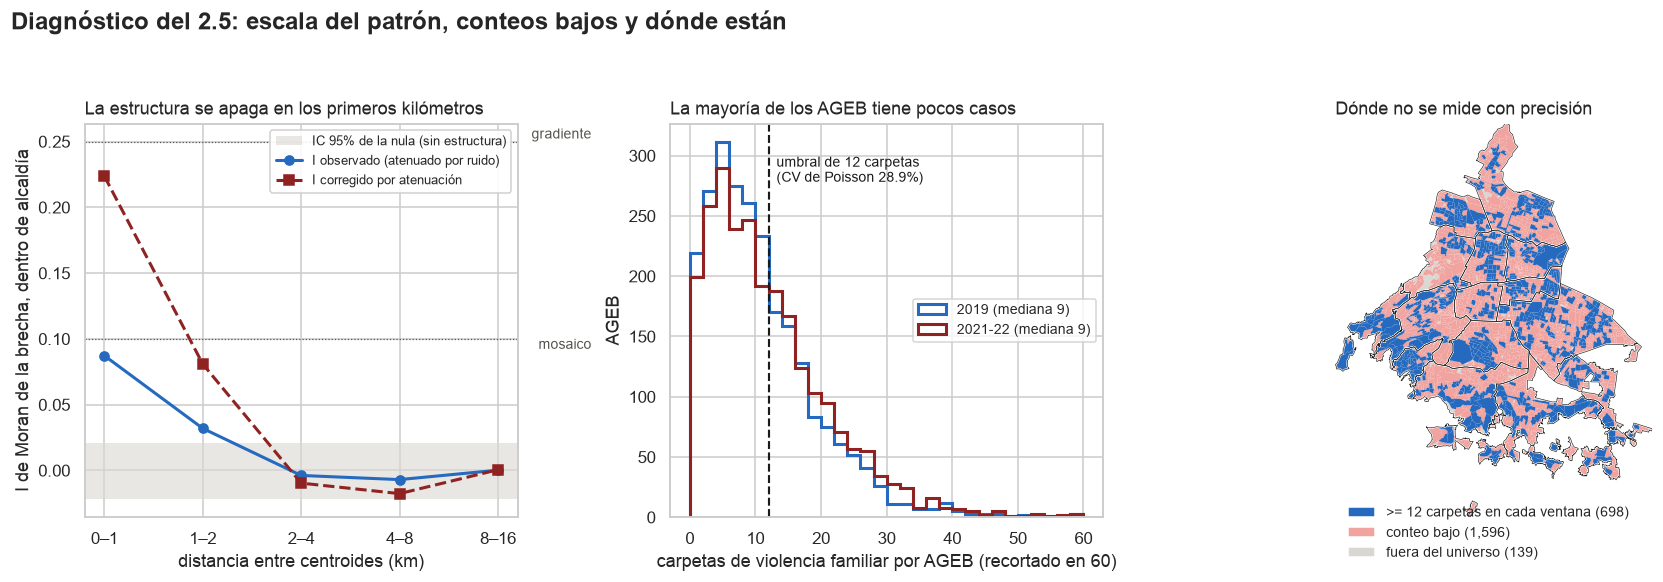

['2.5_diagnostico_ageb.png', '2.6_mapa_brecha_conteo_alto.png', '2.6_mapa_brecha_por_ventana.png', '2.6_mapa_brecha_violencia_familiar_ageb.png', '2.6_mapa_hero_violencia_familiar.png', '2.6_zoom_mosaico_1km.png']


In [41]:
with mpl.rc_context(ESTILO):
    fig5, axes = plt.subplots(1, 3, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.0, 1.0, 1.1]})
    a0 = axes[0]
    xs = np.arange(len(corr))
    a0.axhspan(corr.ic95_nula_inf.min(), corr.ic95_nula_sup.max(), color=GRIS, alpha=.6, lw=0, label="IC 95% de la nula (sin estructura)")
    a0.plot(xs, corr.I_obs, "o-", color="#256abf", lw=2, label="I observado (atenuado por ruido)")
    a0.plot(xs, corr.I_corr, "s--", color="#8f2322", lw=2, label="I corregido por atenuación")
    a0.axhline(UMB_MOS, color=TINTA2, lw=.8, ls=":")
    a0.axhline(UMB_GRAD, color=TINTA2, lw=.8, ls=":")
    a0.text(len(corr) - .05, UMB_GRAD, " gradiente", fontsize=9, color=TINTA2, va="bottom", ha="right")
    a0.text(len(corr) - .05, UMB_MOS, " mosaico", fontsize=9, color=TINTA2, va="top", ha="right")
    a0.set_xticks(xs); a0.set_xticklabels(corr.banda_km)
    a0.set_xlabel("distancia entre centroides (km)"); a0.set_ylabel("I de Moran de la brecha, dentro de alcaldía")
    a0.set_title("La estructura se apaga en los primeros kilómetros", fontsize=12, loc="left")
    a0.legend(fontsize=8.5, loc="upper right", framealpha=.9)

    a1 = axes[1]
    for w, c in zip(VENT, ["#256abf", "#8f2322"]):
        s = vf.xs(w).carpetas.clip(upper=60)
        a1.hist(s, bins=np.arange(0, 62, 2), histtype="step", lw=2, color=c, label=f"{w} (mediana {vf.xs(w).carpetas.median():.0f})")
    a1.axvline(UMBRAL, color=TINTA, lw=1.4, ls="--")
    a1.text(UMBRAL + 1.2, a1.get_ylim()[1] * .92, f"umbral de {UMBRAL} carpetas\n(CV de Poisson 28.9%)", fontsize=9, color=TINTA, va="top")
    a1.set_xlabel("carpetas de violencia familiar por AGEB (recortado en 60)"); a1.set_ylabel("AGEB")
    a1.set_title("La mayoría de los AGEB tiene pocos casos", fontsize=12, loc="left")
    a1.legend(fontsize=9)

    a2 = axes[2]
    cap = GEO.assign(_b=BAJO.reindex(GEO.index), _u=U.reindex(GEO.index).fillna(False))
    cap[~cap._u].plot(ax=a2, color=GRIS, ec="none")
    cap[cap._u & cap._b.fillna(False)].plot(ax=a2, color="#f0a39f", ec="none")
    cap[cap._u & ~cap._b.fillna(False)].plot(ax=a2, color="#256abf", ec="none")
    ALC_POLY.boundary.plot(ax=a2, ec="white", lw=1.2, zorder=4)
    ALC_POLY.boundary.plot(ax=a2, ec=TINTA, lw=.4, zorder=4)
    a2.set_xlim(*XL); a2.set_ylim(*YL); a2.set_axis_off()
    a2.set_title("Dónde no se mide con precisión", fontsize=12, loc="left")
    a2.legend(handles=[Patch(fc="#256abf", label=f">= {UMBRAL} carpetas en cada ventana ({int((U & ALTO).sum())})"),
                       Patch(fc="#f0a39f", label=f"conteo bajo ({int((U & BAJO).sum()):,})"),
                       Patch(fc=GRIS, label=f"fuera del universo ({int((~U).sum())})")],
              fontsize=9, loc="upper left", bbox_to_anchor=(0, 0.06), frameon=False)
    fig5.suptitle("Diagnóstico del 2.5: escala del patrón, conteos bajos y dónde están", fontsize=16, fontweight="bold", x=.01, ha="left")
    fig5.tight_layout(rect=[0, 0, 1, .94])
    fig5.savefig(FIG / "2.5_diagnostico_ageb.png", dpi=DPI)
    plt.show()
print(sorted(p.name for p in FIG.glob("*.png")))

### 11.6 Exportar `resultados/15_diagnostico_ageb.csv`

In [42]:
filas = []
for r in mor.to_dict("records"):
    filas.append({"bloque": "autocorrelacion", "indicador": "I de Moran (contigüidad, estandarizada por filas)",
                  "variante": f"{r['subconjunto']} · {r['cantidad']}", "ventana": r["ventana"], "n_ageb": r["n_ageb"],
                  "valor": r["I_obs"], "valor_corregido": r["I_corr"], "factor_atenuacion": r["atenuacion"],
                  "p95_nula_perm": r["p95_nula_perm"], "p_perm": r["p_perm"],
                  "p95_nula_homog": r["p95_nula_homog"], "p_homog": r["p_homog"], "z_analitico": r["z_analitico"],
                  "lectura": r["veredicto"]})
for r in extra.to_dict("records"):
    filas.append({"bloque": "autocorrelacion", "indicador": "I de Moran (contigüidad, estandarizada por filas)",
                  "variante": f"contexto: {r['variable']}", "ventana": "ambas", "n_ageb": NU, "valor": r["I_obs"],
                  "p95_nula_perm": r["p95_nula_perm"], "p_perm": r["p_perm"], "z_analitico": r["z_analitico"],
                  "lectura": "contexto, sin corrección por atenuación"})
for r in corr.to_dict("records"):
    filas.append({"bloque": "autocorrelacion", "indicador": "I de Moran por banda de distancia (correlograma)",
                  "variante": f"banda {r['banda_km']} km · residuos dentro de alcaldía", "ventana": "ambas",
                  "n_ageb": r["n_ageb"], "valor": r["I_obs"], "valor_corregido": r["I_corr"], "z_analitico": r["z_analitico"],
                  "lectura": "z analítico (aproximación normal), descriptivo"})
for w, r in diag_cnt.iterrows():
    for ind, v in [("AGEB con < 12 carpetas", r.ageb_conteo_bajo), ("AGEB con 0 carpetas", r.ageb_sin_carpetas),
                   ("fracción de AGEB con conteo bajo", r.pct_ageb_conteo_bajo),
                   ("fracción de carpetas en AGEB de conteo bajo", r.pct_carpetas_en_conteo_bajo),
                   ("fracción de llamadas en AGEB de conteo bajo", r.pct_llamadas_en_conteo_bajo),
                   ("carpetas por AGEB: mediana", r.carpetas_mediana), ("carpetas por AGEB: p90", r.carpetas_p90)]:
        filas.append({"bloque": "conteos_bajos", "indicador": ind, "variante": "violencia familiar, todos los AGEB",
                      "ventana": w, "n_ageb": len(ageb), "valor": v,
                      "lectura": "pocos AGEB concentran las carpetas; el resto no se mide con precisión"})
filas.append({"bloque": "conteos_bajos", "indicador": "m: mediana en conteo alto vs conteo bajo (log de la brecha)",
              "variante": f"conteo alto ({int(mask_alto.sum())}) vs conteo bajo ({int((~mask_alto).sum())})", "ventana": "ambas",
              "n_ageb": NU, "valor": float(np.median(mb)), "valor_corregido": float(np.median(mp)), "p_perm": float(u_mw.pvalue),
              "lectura": "Mann-Whitney en p_perm: si difieren, el hachurado no es intercambiable con el resto"})
for gr, r in den.iterrows():
    for ind, v in [("AGEB en el grupo", r.n_ageb), ("AGEB del grupo dentro del universo del mapa", r.n_en_universo),
                   ("carpetas 22 meses", r.carpetas_22m), ("fracción de las carpetas", r.pct_carpetas_22m)]:
        filas.append({"bloque": "denominador", "indicador": ind, "variante": gr, "ventana": "ambas (22 meses)",
                      "n_ageb": len(ageb), "valor": v,
                      "lectura": "afecta a las tasas por vivienda y a H2 (2.2), no a la brecha"})

cols15 = ["bloque", "indicador", "variante", "ventana", "n_ageb", "valor", "valor_corregido", "factor_atenuacion",
          "p95_nula_perm", "p_perm", "p95_nula_homog", "p_homog", "z_analitico", "lectura"]
o15 = pd.DataFrame(filas).reindex(columns=cols15)
num15 = o15.select_dtypes("number").columns
o15[num15] = o15[num15].replace([np.inf, -np.inf], np.nan).round(4)
assert not o15.duplicated(["bloque", "indicador", "variante", "ventana"]).any() and len(o15) > 40
o15.to_csv(OUT / "15_diagnostico_ageb.csv", index=False)
print(o15.shape); display(o15)
sorted(p.name for p in OUT.glob("*.csv"))

(47, 14)


,bloque,indicador,variante,ventana,n_ageb,valor,valor_corregido,factor_atenuacion,p95_nula_perm,p_perm,p95_nula_homog,p_homog,z_analitico,lectura
0,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · residuos dentro de alcaldía",ambas,2294,0.097,0.245,2.533,0.021,0.001,0.018,0.001,7.633,coexisten las dos estructuras
1,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · m (incluye nivel de alcaldía)",ambas,2294,0.146,0.340,2.322,0.021,0.001,0.128,0.005,11.519,(no decide: incluye el nivel de alcaldía)
2,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · residuos dentro de alcaldía",2019,2294,0.092,0.268,2.908,0.022,0.001,0.018,0.001,7.270,gradiente suave
3,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · m (incluye nivel de alcaldía)",2019,2294,0.112,0.312,2.775,0.021,0.001,0.067,0.001,8.851,(no decide: incluye el nivel de alcaldía)
4,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · residuos dentro de alcaldía",2021-22,2294,0.050,0.239,4.748,0.022,0.001,0.018,0.001,3.989,coexisten las dos estructuras
5,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)","universo (2,294 AGEB) · m (incluye nivel de alcaldía)",2021-22,2294,0.108,0.412,3.816,0.022,0.001,0.104,0.034,8.505,(no decide: incluye el nivel de alcaldía)
6,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)",conteo alto (>= 12 carpetas) · residuos dentro de alcaldía,ambas,698,0.119,0.180,1.515,0.047,0.001,0.034,0.001,3.636,coexisten las dos estructuras
7,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)",conteo alto (>= 12 carpetas) · m (incluye nivel de alcaldía),ambas,698,0.190,0.274,1.441,0.047,0.001,0.294,0.913,5.780,(no decide: incluye el nivel de alcaldía)
8,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)",contexto: indicador de conteo bajo (< 12 carpetas en alguna ventana),ambas,2294,0.242,NaN,NaN,0.021,0.001,NaN,NaN,18.986,"contexto, sin corrección por atenuación"
9,autocorrelacion,"I de Moran (contigüidad, estandarizada por filas)",contexto: log(carpetas de las dos ventanas),ambas,2294,0.364,NaN,NaN,0.021,0.001,NaN,NaN,28.610,"contexto, sin corrección por atenuación"


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv']

### 11.7 Qué deja el 2.5

- **Veredicto, con la regla fijada el 11 de oct en `PLAN_15_OCT.md` §3.4 antes de calcular nada: coexisten las dos estructuras**, con el caso pegado al umbral del gradiente. I observado de los residuos dentro de alcaldía = **0.097** (p = 0.001 contra las dos nulas), corregido por atenuación **0.245** en los 2,294 AGEB y **0.180** en los 698 de conteo alto, donde la corrección es tres veces menor.
- **La escala es de 1 a 2 km.** El correlograma deja el I corregido en 0.224 (0–1 km) y 0.081 (1–2 km), y en cero de 2 km en adelante. Lo que el mapa mostraba como zonas amplias es **mosaico de barrio**, no un gradiente de escala de alcaldía.
- **H1 queda intacta y mejor interpretada.** σ²_AGEB/σ²_alcaldía = 4.82 sigue siendo la cifra; el 2.5 dice que esa varianza sub-alcaldía tiene estructura espacial, así que el AGEB es el grano que **permite ver** las zonas, no la unidad en la que ocurre el fenómeno. La frase de la slide 7 se corrige en consecuencia.
- **Un límite nuevo y duro:** los AGEB de conteo bajo tienen brecha mediana 9% más alta (p = 5×10⁻⁶) y están agrupados en el territorio (I = 0.242), en parte por construcción, porque las carpetas están en el denominador. **No son la periferia** —van de 37% de los AGEB en Cuajimalpa a 82% en Benito Juárez—, así que no se pueden descartar como "la zona rural". El hachurado del mapa no es neutro y hay que decirlo al presentar.
- **Qué implica para el 2.2 (H2), si entra:** con autocorrelación a 1–2 km, una regresión que trate los AGEB como independientes daría errores estándar demasiado optimistas. Haría falta error espacialmente correlacionado, efectos de vecindad o inferencia por bloques. Queda anotado como requisito del 2.2 y como trabajo futuro.
- **Salida:** `resultados/15_diagnostico_ageb.csv` (47 filas: 16 de autocorrelación, 15 de conteos bajos y 16 de denominador) y la figura de respaldo `resultados/figuras/2.5_diagnostico_ageb.png`.